# NUTRICARE: FUSED FOOD, NUTRITION AND AGRICULTURE DATA ANALYSIS USING MACHINE LEARNING

**Project workflow:** Dataset loading → data quality assessment → exploratory data analysis → preprocessing → eight machine-learning algorithms → evaluation → potential application.

**Dataset:** `dimpaltamta/nutricare-fused-food-nutrition-agriculture`

**Important notes**
- This notebook is designed to inspect the real dataset before selecting variables. It does not assume column names that have not been verified.
- Set the target-variable names in the configuration cell after inspecting the dataset. Automatic suggestions are provided, but you must confirm that the targets make scientific sense.
- Keep the Kaggle dataset and this notebook private if the data must remain private. Do not publish outputs containing confidential information.
- A model can only be evaluated meaningfully when the dataset contains a suitable target variable and enough valid observations.

## PART A – PROJECT INTRODUCTION

### A1. Introduction
Food, nutrition and agriculture datasets can contain information from multiple sources. Combining an original dataset with information obtained through an API can create a fused dataset with a broader range of attributes. Before analysis, the combined data must be checked for completeness, consistency, duplication and validity.

This project examines the fused food, nutrition and agriculture dataset through data quality assessment and exploratory data analysis. Suitable classification and regression algorithms are then evaluated to investigate whether selected attributes can support prediction tasks.

### A2. Aim
To assess, explore and analyse a fused food, nutrition and agriculture dataset and evaluate suitable machine-learning algorithms for meaningful prediction tasks.

### A3. Objectives
1. Load and understand the fused dataset using KaggleHub and Python.
2. identify the dataset structure, variables and data types.
3. Assess missing values, duplicates, inconsistencies and outliers.
4. Clean and validate the dataset while retaining the original data.
5. Explore important variables and relationships using statistical summaries and visualisations.
6. Prepare suitable features and target variables for machine learning.
7. Implement and evaluate eight classification and regression algorithms.
8. Compare model performance and identify a potential data-driven application.

### A4. Problem statement
The project investigates whether the available food, nutrition and agriculture attributes in the fused dataset are sufficiently complete, consistent and informative to support exploratory analysis and selected predictive modelling tasks.

### A5. Dataset description
The dataset is identified by the Kaggle slug shown above. Its exact number of records, columns, variable names, source fields and file format will be reported after loading. Original-source and API-derived fields must be identified using dataset documentation or verified column names; they must not be guessed.

## PART B – DATASET LOADING AND UNDERSTANDING

### B1. Install and import libraries
Run this cell in a Kaggle Notebook, Google Colab or a local Jupyter environment with internet access. If Kaggle asks for authentication, use your own Kaggle credentials. Never paste an API token into a notebook that you plan to share.

In [15]:
%pip -q install kagglehub[pandas-datasets] openpyxl pyarrow seaborn scikit-learn scipy

In [16]:
import os
import re
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### B2. Authenticate and locate the Kaggle dataset

The following code uses your Kaggle dataset identifier. For a private dataset, the signed-in Kaggle account must own the dataset or have collaborator access.

The dataset is first downloaded to a local cache so that the notebook can inspect the actual filenames. A CSV file is then loaded with the requested `KaggleDatasetAdapter.PANDAS` method. If the dataset uses Excel or Parquet instead, the notebook uses the corresponding pandas reader.

In [17]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import os

dataset_folder = "/content/drive/MyDrive"

for root, dirs, files in os.walk(dataset_folder):
    for file in files:
        if file.lower().endswith((".csv", ".xlsx", ".xls", ".parquet", ".json")):
            print(os.path.join(root, file))

/content/drive/MyDrive/Dimpal_February25_ManualTesting_AssignmentSet1.docx-EmbeddedFile.xlsx
/content/drive/MyDrive/OrangeHRM_ManualTesting.xlsx
/content/drive/MyDrive/ML-EdgeIIoT-dataset.csv
/content/drive/MyDrive/nutricare_fusion_backup.csv
/content/drive/MyDrive/foodname.csv
/content/drive/MyDrive/Final_Fused_Dataset.xlsx
/content/drive/MyDrive/Fused_Dataset.xlsx
/content/drive/MyDrive/Classroom/DSAA July 2026 MCA regular/nutricare_final_fused_dataset.xlsx
/content/drive/MyDrive/Excelr/Dimpal_Excelr_ManualTesting.xlsx
/content/drive/MyDrive/Excelr/Testcase.xlsx
/content/drive/MyDrive/Excelr/OrangeHRM_ManualTesting.xlsx
/content/drive/MyDrive/Excelr/System Test Case.xlsx
/content/drive/MyDrive/Food_Dataset/indian_food_database.csv
/content/drive/MyDrive/Food_Dataset/crop_yield.csv
/content/drive/MyDrive/Food_Dataset/usda_match_progress.csv
/content/drive/MyDrive/Food_Dataset/Copy of global_nutrition_base.csv
/content/drive/MyDrive/Food_Dataset/Fusion_Data.xlsx
/content/drive/MyDrive/

In [19]:

import pandas as pd
from pathlib import Path

# Dataset path in Google Drive
file_path = "/content/drive/MyDrive/Fused_Dataset.xlsx"

# Load Excel dataset
df = pd.read_excel(file_path)

# Preserve original dataset
df_original = df.copy(deep=True)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset name: Fused_Dataset.xlsx")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())


Dataset loaded successfully!
Dataset name: Fused_Dataset.xlsx
Shape: (8779, 26)

Column names:
['Food Name', 'Image URL', 'Hindi Name', 'Marathi Name', 'Calories (kcal)', 'Protein (g)', 'Carbohydrates (g)', 'Fat (g)', 'Fiber (g)', 'Calcium (mg)', 'Iron (mg)', 'Potassium (mg)', 'Sodium (mg)', 'Vitamin C (mg)', 'Nutri-Score Grade', 'nova_group', 'Top Producing Country', 'Top 3 Producing Countries', 'Total Global Production (tonnes)', 'Top Producing Indian State', 'Top 3 Producing Indian States', 'India Total Production (tonnes)', "India's share in global production(%)", 'Cancer_Risk_Classification', 'Cancer_Patient_Support_Category', 'Assumption']

First five records:


,Food Name,Image URL,Hindi Name,Marathi Name,Calories (kcal),Protein (g),Carbohydrates (g),Fat (g),Fiber (g),Calcium (mg),Iron (mg),Potassium (mg),Sodium (mg),Vitamin C (mg),Nutri-Score Grade,nova_group,Top Producing Country,Top 3 Producing Countries,Total Global Production (tonnes),Top Producing Indian State,Top 3 Producing Indian States,India Total Production (tonnes),India's share in global production(%),Cancer_Risk_Classification,Cancer_Patient_Support_Category,Assumption
0,Cornstarch,https://www.finedininglovers.co.uk/sites/defau...,कॉर्नस्टार्च,कॉर्नस्टार्च,381,0.26,91.27,0.1,0.9,2.0,0.47,3.0,9.0,0.0,C,4,United States,"United States, China, Brazil",1200000000,Karnataka,"Karnataka, Madhya Pradesh, Maharashtra",38000000,3.17,Neutral - refined starch with few nutrients,High-calorie / weight maintenance,Cornstarch -> Maize
1,"Nuts, pecans",https://pixabay.com/get/g1fcee2ea842ed3cd674a4...,पेकान मेवे,पेकान नट्स,691,9.17,13.86,72.0,9.6,70.0,2.53,410.0,0.0,1.1,B,1,Mexico,"Mexico, United States, South Africa",300000,Not produced in India,Not produced in India,0,0.00,Protective - unsaturated fats and polyphenols,High-calorie / weight maintenance,Pecans -> Pecan
2,"Eggplant, raw",https://pixabay.com/get/g7b8398258dfe25253b4cd...,कच्चा बैंगन,कच्चे वांगे,25,0.98,5.88,0.2,3.0,9.0,0.23,229.0,2.0,2.2,A,1,China,"China, India, Egypt",59000000,West Bengal,"West Bengal, Odisha, Gujarat",13000000,22.03,Protective - anthocyanin antioxidants,Antioxidant-rich / protective,Eggplant -> Eggplant
3,"Teff, uncooked",https://pixabay.com/get/gb1849187099fb4e204ea9...,"टेफ, बिना पकाया हुआ","टेफ, न शिजवलेले",367,13.30,73.13,2.4,8.0,180.0,7.63,427.0,12.0,0.0,A,1,Ethiopia,"Ethiopia, Eritrea, United States",5000000,Not produced in India,Not produced in India,0,0.00,Protective - whole grain with fiber,General / neutral,Teff -> Teff
4,"Sherbet, orange",https://pixabay.com/get/gd46bed210090a141ff468...,संतरे का शरबत,संत्र्याचे शरबत,144,1.10,30.40,2.0,1.3,54.0,0.14,96.0,46.0,2.3,C,4,Brazil,"Brazil, China, India",75000000,Andhra Pradesh,"Andhra Pradesh, Maharashtra, Madhya Pradesh",10000000,13.33,Risk factor - high added sugar,Limit or avoid,Sherbet -> Oranges


### B3. Initial dataset inspection

In [20]:
print("Dataset dimensions (rows, columns):", df.shape)
print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nData types:")
display(df.dtypes.astype(str).to_frame("Data type"))

print("\nDataset information:")
df.info()

Dataset dimensions (rows, columns): (8779, 26)

Column names:
1. Food Name
2. Image URL
3. Hindi Name
4. Marathi Name
5. Calories (kcal)
6. Protein (g)
7. Carbohydrates (g)
8. Fat (g)
9. Fiber (g)
10. Calcium (mg)
11. Iron (mg)
12. Potassium (mg)
13. Sodium (mg)
14. Vitamin C (mg)
15. Nutri-Score Grade
16. nova_group
17. Top Producing Country
18. Top 3 Producing Countries
19. Total Global Production (tonnes)
20. Top Producing Indian State
21. Top 3 Producing Indian States
22. India Total Production (tonnes)
23. India's share in global production(%)
24. Cancer_Risk_Classification
25. Cancer_Patient_Support_Category
26. Assumption

Data types:


,Data type
Food Name,object
Image URL,object
Hindi Name,object
Marathi Name,object
Calories (kcal),int64
Protein (g),float64
Carbohydrates (g),float64
Fat (g),float64
Fiber (g),float64
Calcium (mg),float64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8779 entries, 0 to 8778
Data columns (total 26 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Food Name                              8779 non-null   object 
 1   Image URL                              8779 non-null   object 
 2   Hindi Name                             8779 non-null   object 
 3   Marathi Name                           8779 non-null   object 
 4   Calories (kcal)                        8779 non-null   int64  
 5   Protein (g)                            8779 non-null   float64
 6   Carbohydrates (g)                      8779 non-null   float64
 7   Fat (g)                                8779 non-null   float64
 8   Fiber (g)                              8779 non-null   float64
 9   Calcium (mg)                           8763 non-null   float64
 10  Iron (mg)                              8764 non-nu

In [21]:
print("Descriptive statistics – numerical attributes")
display(df.describe(include=[np.number]).T)

print("Descriptive statistics – categorical attributes")
display(df.describe(include=["object", "category", "bool"]).T)

Descriptive statistics – numerical attributes


,count,mean,std,min,25%,50%,75%,max
Calories (kcal),8779.0,2.262419e+02,1.697758e+02,0.0,91.00,1.910000e+02,3.370000e+02,9.020000e+02
Protein (g),8779.0,1.133746e+01,1.052894e+01,0.0,2.38,8.000000e+00,1.987000e+01,8.832000e+01
Carbohydrates (g),8779.0,2.214446e+01,2.727258e+01,0.0,0.05,9.380000e+00,3.506500e+01,1.000000e+02
Fat (g),8779.0,1.054601e+01,1.579362e+01,0.0,1.00,5.100000e+00,1.400000e+01,1.000000e+02
Fiber (g),8779.0,2.043650e+00,4.270791e+00,0.0,0.00,4.000000e-01,2.400000e+00,7.900000e+01
Calcium (mg),8763.0,7.393674e+01,2.000256e+02,0.0,9.00,2.000000e+01,6.500000e+01,7.364000e+03
Iron (mg),8764.0,2.647761e+00,5.663766e+00,0.0,0.50,1.310000e+00,2.560000e+00,1.240000e+02
Potassium (mg),8753.0,2.678418e+02,3.688140e+02,0.0,115.00,2.230000e+02,3.310000e+02,1.650000e+04
Sodium (mg),8767.0,3.068886e+02,9.405074e+02,0.0,37.00,8.400000e+01,3.910000e+02,3.880000e+04
Vitamin C (mg),8712.0,8.448145e+00,6.592299e+01,0.0,0.00,0.000000e+00,2.600000e+00,2.732000e+03


Descriptive statistics – categorical attributes


,count,unique,top,freq
Food Name,8779,8779,Cornstarch,1
Image URL,8779,8685,https://encrypted-tbn0.gstatic.com/images?q=tb...,12
Hindi Name,8779,8638,"दूध, कम वसा वाला, कल्चर्ड, तरल, छाछ",3
Marathi Name,8779,8640,"बालआहार, बटरनट स्क्वॅश आणि मका, भाजी",2
Nutri-Score Grade,8779,6,A,2200
Top Producing Country,8779,69,United States,5432
Top 3 Producing Countries,8779,650,"United States, Canada, United Kingdom",1588
Top Producing Indian State,8779,24,Not produced in India,4227
Top 3 Producing Indian States,8779,202,Not produced in India,4227
Cancer_Risk_Classification,8779,1371,Risk factor - red meat (IARC Group 2A probable...,919


In [22]:
print("Random sample of records:")
display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))

Random sample of records:


,Food Name,Image URL,Hindi Name,Marathi Name,Calories (kcal),Protein (g),Carbohydrates (g),Fat (g),Fiber (g),Calcium (mg),Iron (mg),Potassium (mg),Sodium (mg),Vitamin C (mg),Nutri-Score Grade,nova_group,Top Producing Country,Top 3 Producing Countries,Total Global Production (tonnes),Top Producing Indian State,Top 3 Producing Indian States,India Total Production (tonnes),India's share in global production(%),Cancer_Risk_Classification,Cancer_Patient_Support_Category,Assumption
509,"Barley, hulled",https://pixabay.com/get/g181b6e2177c50aedb61bb...,जौ (छिलका सहित),जव (सालीसह),354,12.48,73.48,2.3,17.3,33.0,3.60,452.0,12.0,0.0,A,1,Russia,"Russia, France, Germany",150000000,Rajasthan,"Rajasthan, Uttar Pradesh, Madhya Pradesh",1700000,1.133333,Protective - beta-glucan fiber,General / neutral,Barley
1076,"Bread, toasted, rice bran",https://pixabay.com/get/gab0f4b3844cf27442b1e5...,"ब्रेड, टोस्टेड, चावल की भूसी","ब्रेड, टोस्टेड, तांदळाचा कोंडा",264,9.70,47.30,5.0,5.3,75.0,3.92,212.0,292.0,0.0,C,4,United States,"United States, Japan, Canada",100000,Not produced in India,Not produced in India,0,0.000000,Protective - rice bran nutrients,General / neutral,Rice bran bread -> Wheat flour + Rice bran
7613,"Beef, grilled, cooked, choice, trimmed to 0"" f...",https://pixabay.com/get/g87c24750492d9218f16c0...,"गोमांस, ग्रिल पर पकाया हुआ, पका हुआ, चॉइस ग्रे...","गोमांस, ग्रिल केलेले, शिजवलेले, चॉइस ग्रेड, 0 ...",215,27.97,0.00,11.0,0.0,16.0,2.88,391.0,75.0,0.0,B,1,United States,"United States, Brazil, China",76340000,Uttar Pradesh,"Uttar Pradesh, Andhra Pradesh, Maharashtra",4400000,5.763689,Risk factor - red meat (IARC Group 2A probable...,High-protein / muscle preservation,Beef -> Bovine meat (cattle)
8379,"Lamb, cooked, choice, trimmed to 1/4"" fat, sep...",https://pixabay.com/get/g29096ce6e192d2d33c45c...,"मेमने का मांस, पका हुआ, चॉइस ग्रेड, 1/4 इंच चर...","कोकराचे मांस, शिजवलेले, चॉइस ग्रेड, 1/4 इंच चर...",294,24.52,0.00,21.0,0.0,17.0,1.88,310.0,72.0,0.0,D,1,China,"China, India, Australia",11530000,Telangana,"Telangana, Andhra Pradesh, Karnataka",1141450,9.899827,Risk factor - red meat (IARC Group 2A probable...,High-protein / muscle preservation,Lamb -> Sheep meat
7968,"Oil, principal uses icings and fillings, palm,...",https://pixabay.com/get/geb0b52451e2b866e49a24...,"सूअर का मांस, तवे पर भूना हुआ, गरम किया हुआ, क...","डुकराचे मांस, तव्यावर भाजलेले, गरम केलेले, फक्...",884,0.00,0.00,100.0,0.0,0.0,0.00,0.0,0.0,0.0,E,4,Indonesia,"Indonesia, Malaysia, Thailand",75000000,Andhra Pradesh,"Andhra Pradesh, Telangana, Karnataka",300000,0.400000,"Neutral - refined oil, no direct cancer link",General / neutral,Palm oil -> Oil palm


### B4. Identify original-source and API-derived variables

Do not assume that column names containing words such as `api` or `original` are definitive evidence of provenance. Use the dataset documentation, data dictionary or project source files to verify which fields came from each source.

The next cell provides a preliminary name-based search only. Edit the two lists after checking the dataset documentation.

In [23]:
# EDIT THESE LISTS after verifying the dataset documentation.
ORIGINAL_SOURCE_COLUMNS = []  # Example: ["food_name", "energy_kcal"]
API_SOURCE_COLUMNS = []       # Example: ["api_food_category", "api_brand"]

# Preliminary column-name hints; these are NOT proof of data provenance.
original_hints = [c for c in df.columns
                  if re.search(r"original|source|base|raw", str(c), re.I)]
api_hints = [c for c in df.columns
             if re.search(r"api|external|fused|enriched", str(c), re.I)]

print("Potential original/source-related column names:", original_hints)
print("Potential API/enrichment-related column names:", api_hints)
print("\nVerified original-source columns:", ORIGINAL_SOURCE_COLUMNS)
print("Verified API-source columns:", API_SOURCE_COLUMNS)

Potential original/source-related column names: []
Potential API/enrichment-related column names: []

Verified original-source columns: []
Verified API-source columns: []


## PART C – DATA PREPROCESSING

### C1. Create a working copy and standardise column names

The original loaded DataFrame is preserved as `df_original`. Cleaning is performed on `df_work` so that the source data remains available for comparison.

In [24]:
df_work = df_original.copy(deep=True)

def clean_column_name(name):
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    name = re.sub(r"_+", "_", name).strip("_")
    return name or "unnamed_column"

cleaned_names = [clean_column_name(c) for c in df_work.columns]

# Ensure column names remain unique after standardisation.
seen = {}
unique_names = []
for name in cleaned_names:
    count = seen.get(name, 0)
    unique_names.append(name if count == 0 else f"{name}_{count+1}")
    seen[name] = count + 1

df_work.columns = unique_names
print("Standardised column names:")
print(df_work.columns.tolist())

Standardised column names:
['food_name', 'image_url', 'hindi_name', 'marathi_name', 'calories_kcal', 'protein_g', 'carbohydrates_g', 'fat_g', 'fiber_g', 'calcium_mg', 'iron_mg', 'potassium_mg', 'sodium_mg', 'vitamin_c_mg', 'nutri_score_grade', 'nova_group', 'top_producing_country', 'top_3_producing_countries', 'total_global_production_tonnes', 'top_producing_indian_state', 'top_3_producing_indian_states', 'india_total_production_tonnes', 'india_s_share_in_global_production', 'cancer_risk_classification', 'cancer_patient_support_category', 'assumption']


In [25]:
# Attempt conservative type conversion for object columns.
# Conversion is accepted only when most non-missing values are numeric.
for col in df_work.select_dtypes(include="object").columns:
    converted = pd.to_numeric(
        df_work[col].astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce"
    )
    non_missing = df_work[col].notna().sum()
    if non_missing > 0 and converted.notna().sum() / non_missing >= 0.90:
        df_work[col] = converted

print("Numerical columns:", df_work.select_dtypes(include=np.number).columns.tolist())
print("Categorical columns:", df_work.select_dtypes(include=["object", "category", "bool"]).columns.tolist())

Numerical columns: ['calories_kcal', 'protein_g', 'carbohydrates_g', 'fat_g', 'fiber_g', 'calcium_mg', 'iron_mg', 'potassium_mg', 'sodium_mg', 'vitamin_c_mg', 'nova_group', 'total_global_production_tonnes', 'india_total_production_tonnes', 'india_s_share_in_global_production']
Categorical columns: ['food_name', 'image_url', 'hindi_name', 'marathi_name', 'nutri_score_grade', 'top_producing_country', 'top_3_producing_countries', 'top_producing_indian_state', 'top_3_producing_indian_states', 'cancer_risk_classification', 'cancer_patient_support_category', 'assumption']


## PART D – DATA QUALITY ASSESSMENT

### D1. Structural checks

In [26]:
print("1. Dataset dimensions:", df_work.shape)

structure_table = pd.DataFrame({
    "Column": df_work.columns,
    "Data type": [str(df_work[c].dtype) for c in df_work.columns],
    "Non-missing values": [df_work[c].notna().sum() for c in df_work.columns],
    "Unique values": [df_work[c].nunique(dropna=True) for c in df_work.columns],
    "Missing values": [df_work[c].isna().sum() for c in df_work.columns],
})
display(structure_table)

print("2. Total unique rows:", len(df_work.drop_duplicates()))
print("3. Duplicate records:", int(df_work.duplicated().sum()))

1. Dataset dimensions: (8779, 26)


,Column,Data type,Non-missing values,Unique values,Missing values
0,food_name,object,8779,8779,0
1,image_url,object,8779,8685,0
2,hindi_name,object,8779,8638,0
3,marathi_name,object,8779,8640,0
4,calories_kcal,int64,8779,671,0
5,protein_g,float64,8779,2664,0
6,carbohydrates_g,float64,8779,3322,0
7,fat_g,float64,8779,185,0
8,fiber_g,float64,8779,251,0
9,calcium_mg,float64,8763,564,16


2. Total unique rows: 8779
3. Duplicate records: 0


In [27]:
# Detect possible identifier columns from their names.
id_like_columns = [
    c for c in df_work.columns
    if re.search(r"(^id$|_id$|^id_|identifier|record_no|serial)", c, re.I)
]
print("Possible identifier columns:", id_like_columns)

# Report duplicate identifiers, without assuming that every ID must be unique.
duplicate_id_report = []
for col in id_like_columns:
    duplicate_id_report.append({
        "Identifier column": col,
        "Missing identifiers": int(df_work[col].isna().sum()),
        "Unique identifiers": int(df_work[col].nunique(dropna=True)),
        "Rows with repeated identifier": int(df_work[col].duplicated(keep=False).sum())
    })
display(pd.DataFrame(duplicate_id_report))

Possible identifier columns: []


""


In [28]:
# Inspect unique values for manageable categorical columns.
categorical_cols = df_work.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

for col in categorical_cols:
    n = df_work[col].nunique(dropna=True)
    if n <= 50:
        print(f"\n{col} ({n} unique values):")
        print(df_work[col].value_counts(dropna=False).head(50).to_string())
    else:
        print(f"\n{col}: {n} unique values; showing 15 most frequent")
        print(df_work[col].value_counts(dropna=False).head(15).to_string())


food_name: 8779 unique values; showing 15 most frequent
food_name
Cornstarch               1
Nuts, pecans             1
Eggplant, raw            1
Teff, uncooked           1
Sherbet, orange          1
Cauliflower, raw         1
Taro leaves, raw         1
Lamb, raw, ground        1
Cheese, camembert        1
Vegetarian fillets       1
PACE, Picante Sauce      1
Goji berries, dried      1
Mango nectar, canned     1
Crackers, rusk toast     1
Chicken, boiled, feet    1

image_url: 8685 unique values; showing 15 most frequent
image_url
https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcS7gQORF59Mqsm0hZDYA-XTrGavOyQNaMW4xXtWuqSCDg&s=10    12
https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcReOblx6nBZ_G-kJDLzzw_rISltFTPY7PouFU1Y4Z4eRA&s=10    10
https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTtn4OVAPpmc0OOmqlJdk2K8DODZBSibj1AVE8Rg4m2ow&s=10     7
https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSOgM1Fj9rAUi_4K12pVpgZAyROYQZIiK5Xks8N2Cof-Q&s=10     6
https://encrypted-tbn

### D2. Missing-data assessment

Missing values are reported as both counts and percentages. The bar chart identifies attributes with the highest proportion of missing values. Missing-value treatment is performed later in the modelling pipeline using training-data imputers to reduce data leakage.

In [29]:
missing_count = df_work.isna().sum()
missing_percent = (missing_count / max(len(df_work), 1) * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing count": missing_count,
    "Missing percentage": missing_percent
}).sort_values("Missing percentage", ascending=False)

display(missing_summary)
print("Total missing cells:", int(missing_count.sum()))
print("Attributes with maximum missing data:")
display(missing_summary.head(10))

,Missing count,Missing percentage
vitamin_c_mg,67,0.76
potassium_mg,26,0.30
calcium_mg,16,0.18
iron_mg,15,0.17
sodium_mg,12,0.14
marathi_name,0,0.00
image_url,0,0.00
hindi_name,0,0.00
calories_kcal,0,0.00
food_name,0,0.00


Total missing cells: 136
Attributes with maximum missing data:


,Missing count,Missing percentage
vitamin_c_mg,67,0.76
potassium_mg,26,0.30
calcium_mg,16,0.18
iron_mg,15,0.17
sodium_mg,12,0.14
marathi_name,0,0.00
image_url,0,0.00
hindi_name,0,0.00
calories_kcal,0,0.00
food_name,0,0.00


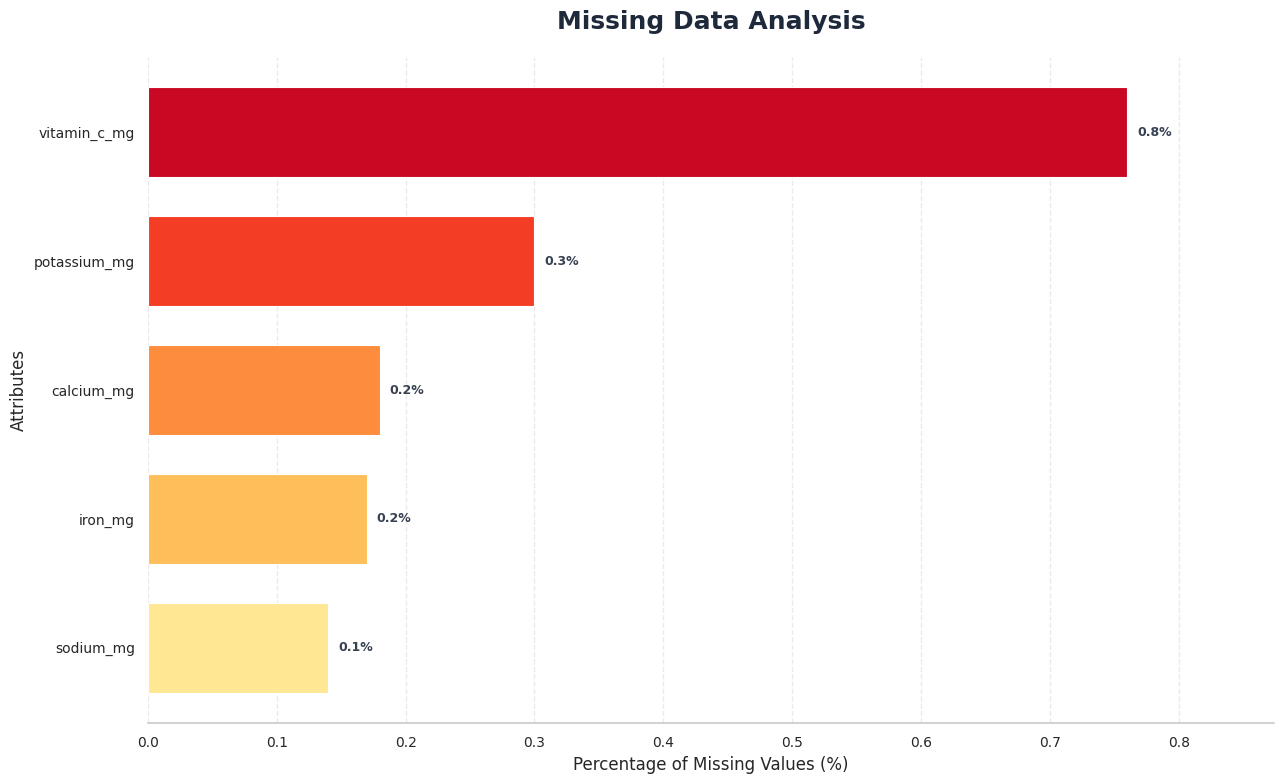

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

missing_to_plot = (
    missing_summary[missing_summary["Missing count"] > 0]
    .sort_values("Missing percentage", ascending=True)
    .tail(25)
)

if not missing_to_plot.empty:

    # Professional theme
    sns.set_theme(style="whitegrid", context="notebook")

    fig, ax = plt.subplots(figsize=(13, 8))

    # Gradient colors based on missing percentage
    values = missing_to_plot["Missing percentage"]

    colors = sns.color_palette("YlOrRd", n_colors=len(missing_to_plot))

    # Horizontal bar plot
    bars = ax.barh(
        missing_to_plot.index,
        values,
        color=colors,
        edgecolor="white",
        linewidth=0.8,
        height=0.7
    )

    # Add percentage labels
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_width() + max(values) * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center",
            fontsize=9,
            fontweight="bold",
            color="#374151"
        )

    # Title and labels
    ax.set_title(
        "Missing Data Analysis",
        fontsize=18,
        fontweight="bold",
        color="#1E293B",
        pad=20
    )

    ax.set_xlabel(
        "Percentage of Missing Values (%)",
        fontsize=12,
        fontweight="medium"
    )

    ax.set_ylabel("Attributes", fontsize=12, fontweight="medium")

    # Styling
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.grid(axis="y", visible=False)

    ax.set_xlim(0, max(values) * 1.15)

    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)

    plt.tight_layout()
    plt.show()

else:
    print("No missing values detected.")

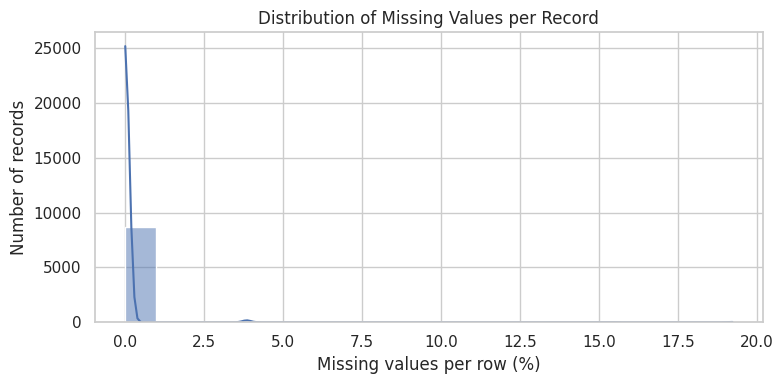

Rows with more than 50% missing values: 0


In [31]:
# Missingness pattern: percentage of missing cells per row.
row_missing_percent = df_work.isna().mean(axis=1) * 100
plt.figure(figsize=(8, 4))
sns.histplot(row_missing_percent, bins=20, kde=True)
plt.title("Distribution of Missing Values per Record")
plt.xlabel("Missing values per row (%)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

print("Rows with more than 50% missing values:", int((row_missing_percent > 50).sum()))

### D3. Consistency assessment

The following checks flag possible issues for inspection. Automated flags are not automatically errors: for example, spelling differences may represent legitimate distinct categories, and unusual numeric values may be valid observations.

In [32]:
# Check leading/trailing whitespace in text fields.
whitespace_report = []
for col in categorical_cols:
    s = df_work[col].dropna().astype(str)
    count = int((s != s.str.strip()).sum())
    if count:
        whitespace_report.append({"Column": col, "Values with surrounding whitespace": count})
display(pd.DataFrame(whitespace_report))

""


In [33]:
# Check categorical values that differ only by case/spacing.
category_variants = []
for col in categorical_cols:
    s = df_work[col].dropna().astype(str)
    normalised = s.str.strip().str.lower()
    mapping = pd.DataFrame({"original": s, "normalised": normalised}).drop_duplicates()
    counts = mapping.groupby("normalised")["original"].nunique()
    for key, n_variants in counts[counts > 1].items():
        variants = mapping.loc[mapping["normalised"] == key, "original"].tolist()
        category_variants.append({
            "Column": col,
            "Normalised form": key,
            "Possible spelling/case variants": variants
        })
display(pd.DataFrame(category_variants))

,Column,Normalised form,Possible spelling/case variants
0,assumption,beef noodle soup -> beef + wheat flour,"[Beef noodle soup -> Beef + Wheat flour, Beef ..."
1,assumption,broccoli cheese soup -> broccoli + cheese + milk,[Broccoli cheese soup -> Broccoli + Cheese + M...
2,assumption,butter cookies -> wheat flour + butter + sugar,[Butter Cookies -> Wheat flour + Butter + Suga...
3,assumption,chicken broth -> chicken + water,"[Chicken broth -> Chicken + Water, Chicken Bro..."
4,assumption,chicken noodle soup -> chicken + wheat flour,"[Chicken noodle soup -> Chicken + Wheat flour,..."
5,assumption,chicken with rice soup,"[Chicken with rice soup, Chicken with Rice Soup]"
6,assumption,cream of asparagus soup -> asparagus + milk + ...,[Cream of asparagus soup -> Asparagus + Milk +...
7,assumption,cream of potato soup -> potato + milk + wheat ...,[Cream of potato soup -> Potato + Milk + Wheat...
8,assumption,cream of shrimp soup -> shrimp + milk + wheat ...,[Cream of shrimp soup -> Shrimp + Milk + Wheat...
9,assumption,cream of wheat -> wheat,"[Cream of Wheat -> Wheat, Cream of wheat -> Wh..."


In [34]:
# Check date-like columns and parsing failures.
date_like_cols = [c for c in df_work.columns if re.search(r"date|time|year|month", c, re.I)]
date_reports = []

for col in date_like_cols:
    parsed = pd.to_datetime(df_work[col], errors="coerce")
    non_missing = df_work[col].notna().sum()
    date_reports.append({
        "Column": col,
        "Non-missing values": int(non_missing),
        "Successfully parsed": int(parsed.notna().sum()),
        "Unparsed values": int(non_missing - parsed.notna().sum())
    })

display(pd.DataFrame(date_reports))

""


In [35]:
# Basic numeric validity checks: negative values and infinite values.
numeric_cols = df_work.select_dtypes(include=np.number).columns.tolist()
numeric_validity = []

for col in numeric_cols:
    s = df_work[col]
    numeric_validity.append({
        "Column": col,
        "Negative values": int((s < 0).sum()),
        "Positive infinity": int(np.isposinf(s).sum()),
        "Negative infinity": int(np.isneginf(s).sum()),
        "Zero values": int((s == 0).sum())
    })

display(pd.DataFrame(numeric_validity))

,Column,Negative values,Positive infinity,Negative infinity,Zero values
0,calories_kcal,0,0,0,39
1,protein_g,0,0,0,357
2,carbohydrates_g,0,0,0,2149
3,fat_g,0,0,0,450
4,fiber_g,0,0,0,4036
5,calcium_mg,0,0,0,579
6,iron_mg,0,0,0,427
7,potassium_mg,0,0,0,524
8,sodium_mg,0,0,0,331
9,vitamin_c_mg,0,0,0,4821


In [36]:
# Check for potential conflicts between verified original and API source columns.
# This compares columns with the same normalised values only when they are paired by the user.
# Provide pairs after verifying which fields represent the same concept.
SOURCE_COLUMN_PAIRS = [
    # ("original_column_name", "api_column_name"),
]

conflict_results = []
for original_col, api_col in SOURCE_COLUMN_PAIRS:
    if original_col in df_work.columns and api_col in df_work.columns:
        left = df_work[original_col].astype("string").str.strip().str.lower()
        right = df_work[api_col].astype("string").str.strip().str.lower()
        comparable = left.notna() & right.notna()
        conflicts = comparable & (left != right)
        conflict_results.append({
            "Original column": original_col,
            "API column": api_col,
            "Comparable records": int(comparable.sum()),
            "Conflicting records": int(conflicts.sum()),
            "Conflict percentage": round(conflicts.sum() / max(comparable.sum(), 1) * 100, 2)
        })

display(pd.DataFrame(conflict_results))
print("If no pairs are listed, source conflicts cannot yet be assessed.")

""


If no pairs are listed, source conflicts cannot yet be assessed.


### D4. Outlier detection using the IQR method

For each numerical attribute, the interquartile range (IQR) is calculated as Q3 − Q1. Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as potential outliers.

An IQR flag does not prove that a value is incorrect. Outliers must be reviewed using domain knowledge, units, source records and plausible biological/nutritional ranges.

In [37]:
outlier_rows = []
iqr_bounds = {}

for col in numeric_cols:
    s = df_work[col].replace([np.inf, -np.inf], np.nan).dropna()
    if len(s) < 4 or s.nunique() < 2:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df_work[col] < lower) | (df_work[col] > upper)
    iqr_bounds[col] = (lower, upper)
    outlier_rows.append({
        "Attribute": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower bound": lower,
        "Upper bound": upper,
        "Outlier count": int(mask.sum()),
        "Outlier percentage": round(mask.sum() / max(df_work[col].notna().sum(), 1) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values("Outlier percentage", ascending=False)
display(outlier_summary)

,Attribute,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count,Outlier percentage
9,vitamin_c_mg,0.00,2.600000e+00,2.600000e+00,-3.900000e+00,6.500000e+00,1596,18.32
11,total_global_production_tonnes,500000.00,7.833000e+07,7.783000e+07,-1.162450e+08,1.950750e+08,1346,15.33
12,india_total_production_tonnes,0.00,4.500000e+06,4.500000e+06,-6.750000e+06,1.125000e+07,1321,15.05
5,calcium_mg,9.00,6.500000e+01,5.600000e+01,-7.500000e+01,1.490000e+02,956,10.91
4,fiber_g,0.00,2.400000e+00,2.400000e+00,-3.600000e+00,6.000000e+00,805,9.17
13,india_s_share_in_global_production,0.00,6.451613e+00,6.451613e+00,-9.677419e+00,1.612903e+01,770,8.77
6,iron_mg,0.50,2.560000e+00,2.060000e+00,-2.590000e+00,5.650000e+00,688,7.85
8,sodium_mg,37.00,3.910000e+02,3.540000e+02,-4.940000e+02,9.220000e+02,488,5.57
3,fat_g,1.00,1.400000e+01,1.300000e+01,-1.850000e+01,3.350000e+01,473,5.39
7,potassium_mg,115.00,3.310000e+02,2.160000e+02,-2.090000e+02,6.550000e+02,377,4.31


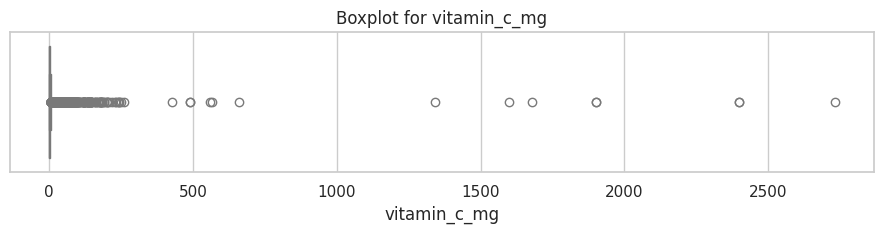

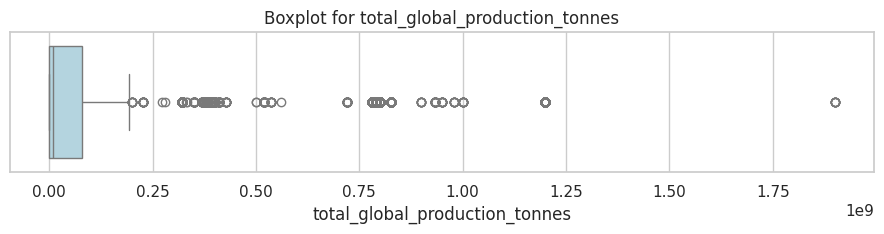

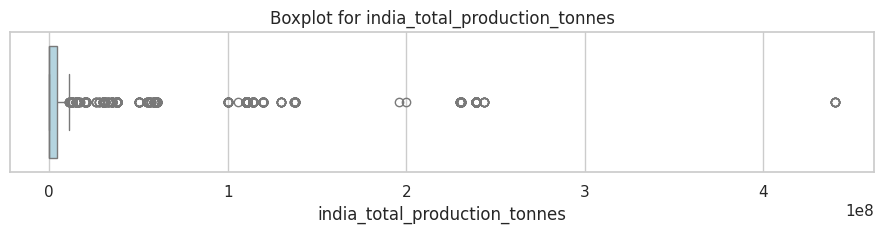

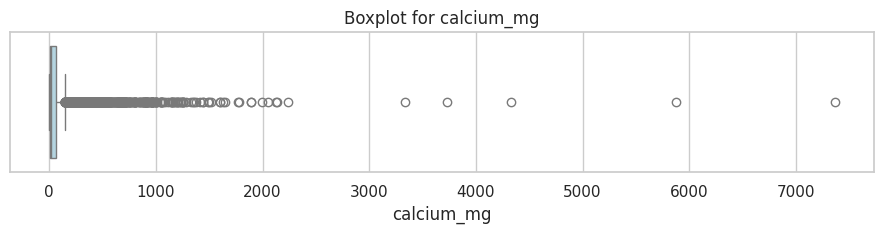

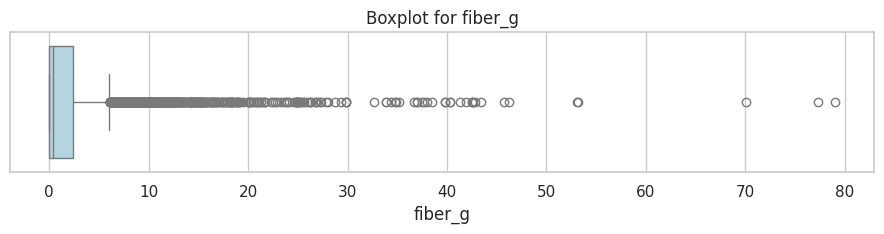

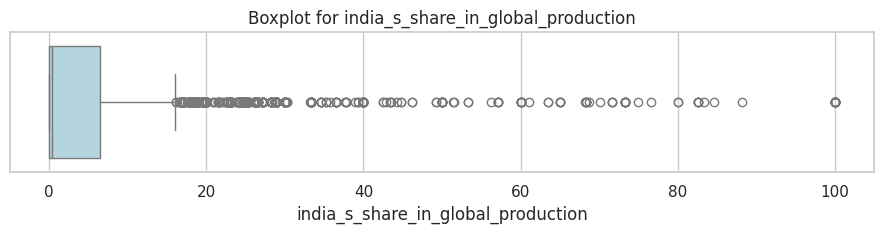

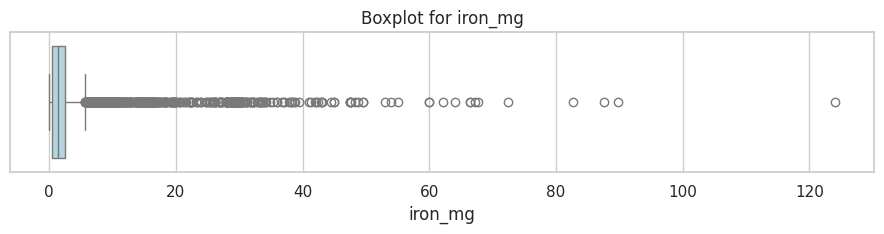

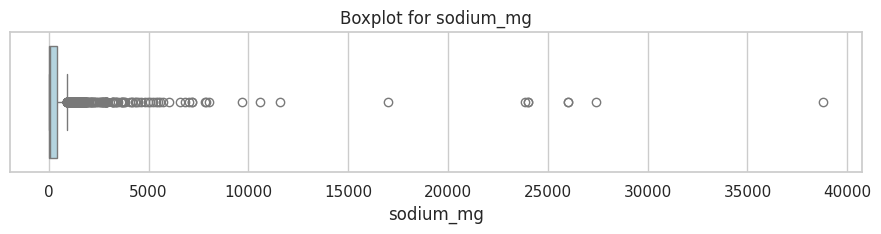

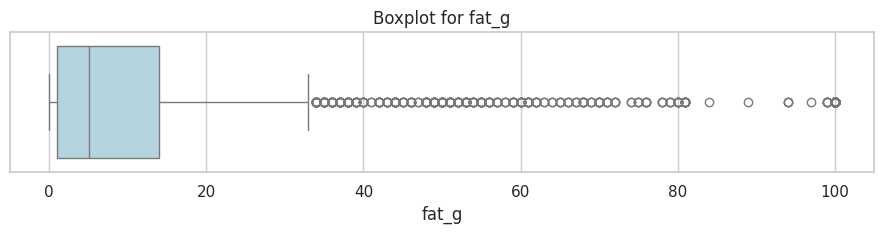

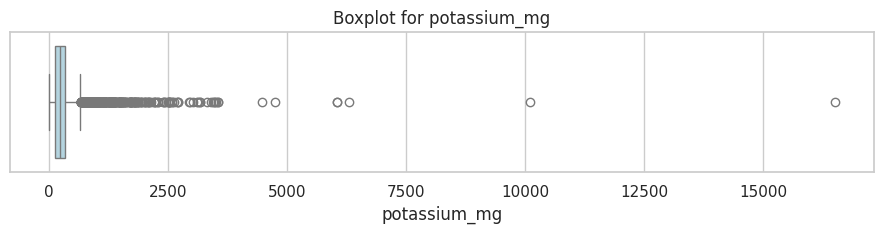

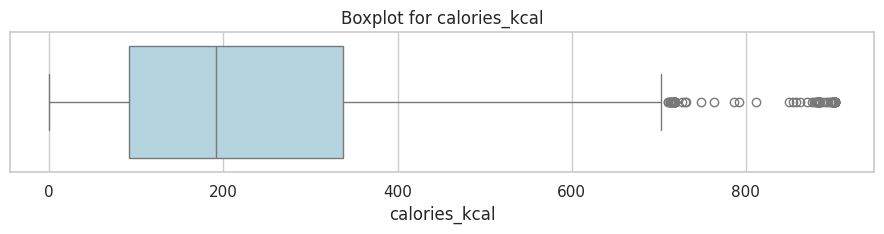

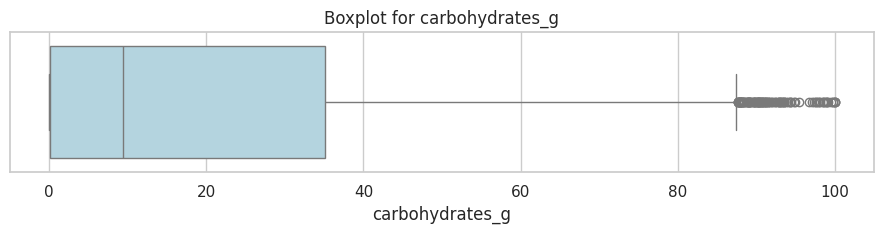

In [38]:
# Boxplots for up to 12 numerical variables with the largest IQR outlier counts.
if not outlier_summary.empty:
    selected_outlier_cols = outlier_summary.head(12)["Attribute"].tolist()
    for col in selected_outlier_cols:
        plt.figure(figsize=(9, 2.5))
        sns.boxplot(x=df_work[col], color="lightblue")
        plt.title(f"Boxplot for {col}")
        plt.tight_layout()
        plt.show()
else:
    print("No suitable numerical attributes for IQR outlier detection.")

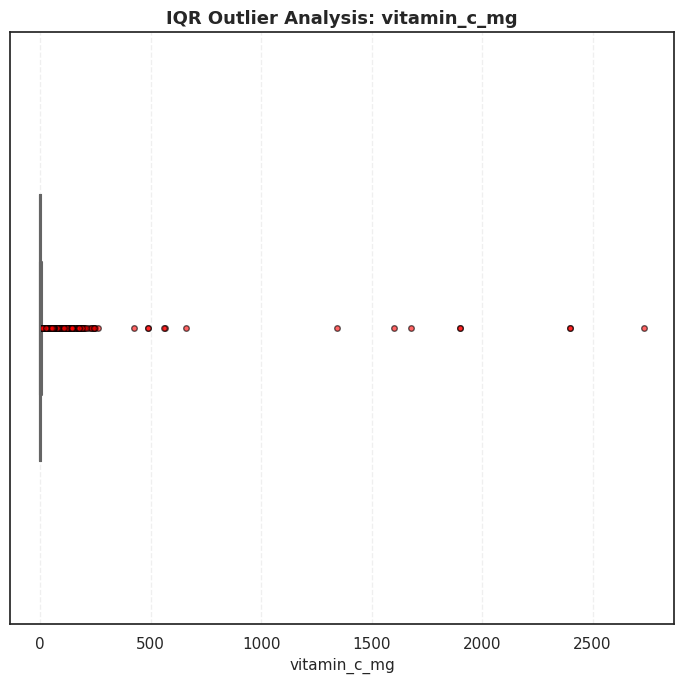

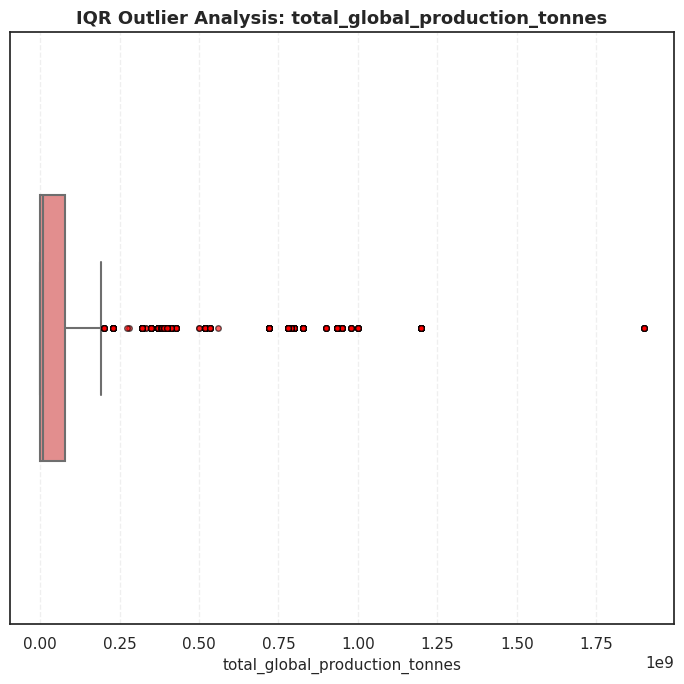

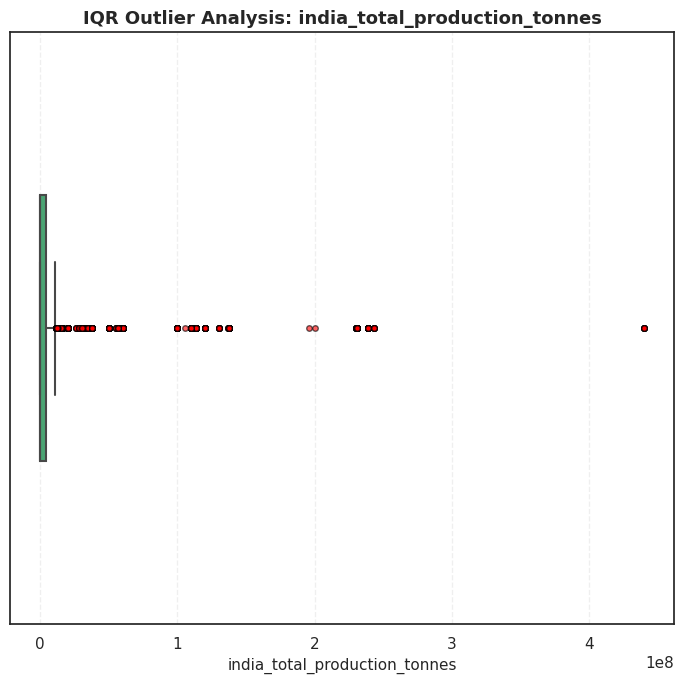

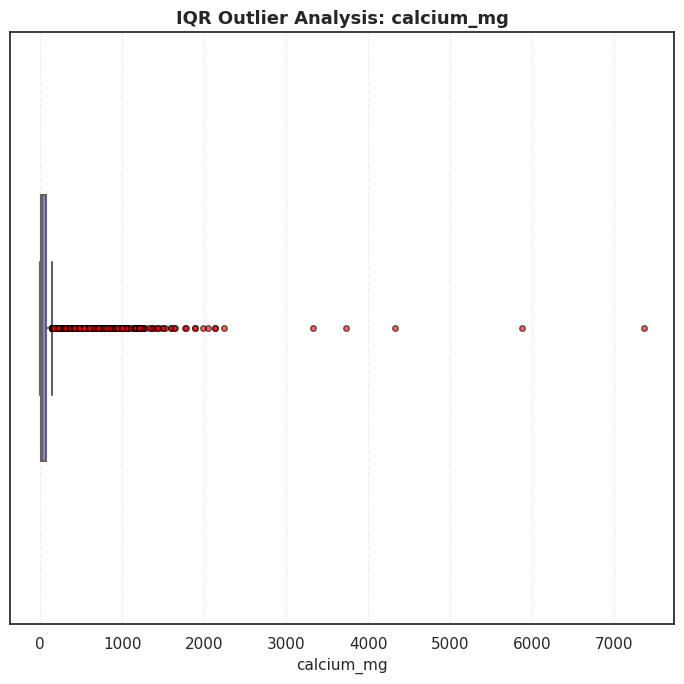

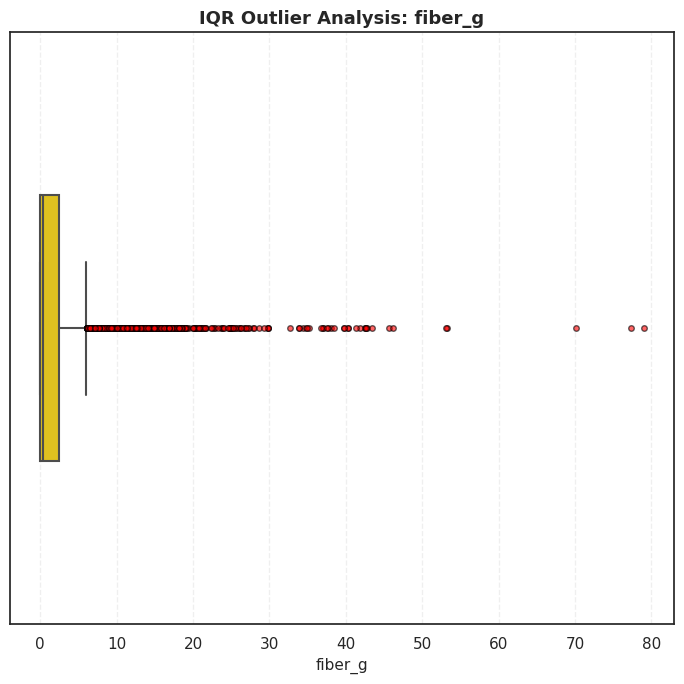

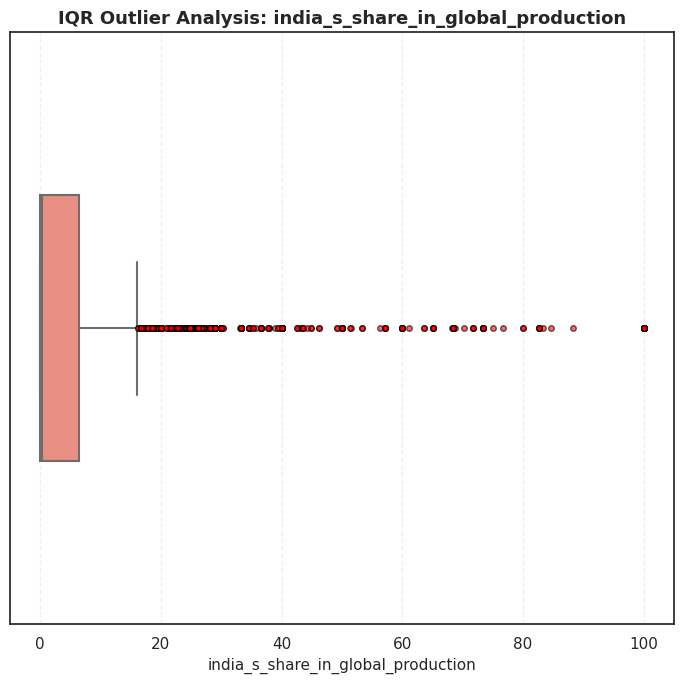

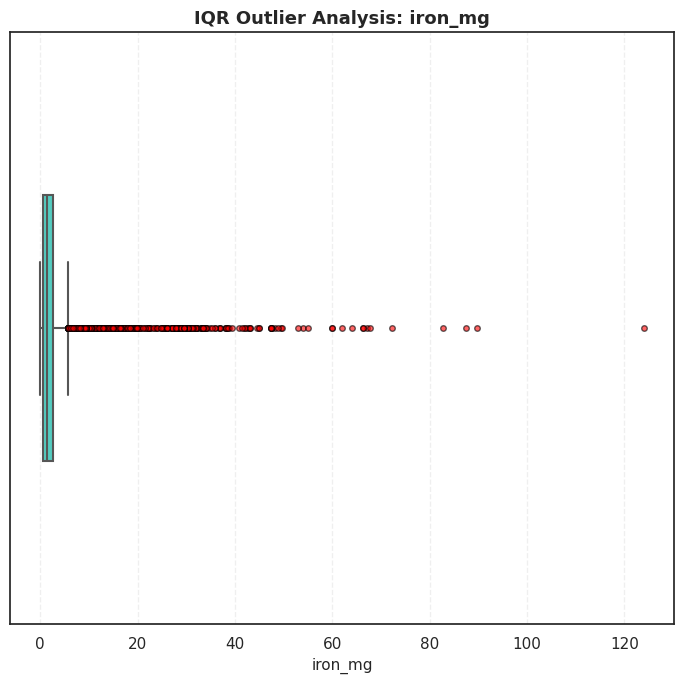

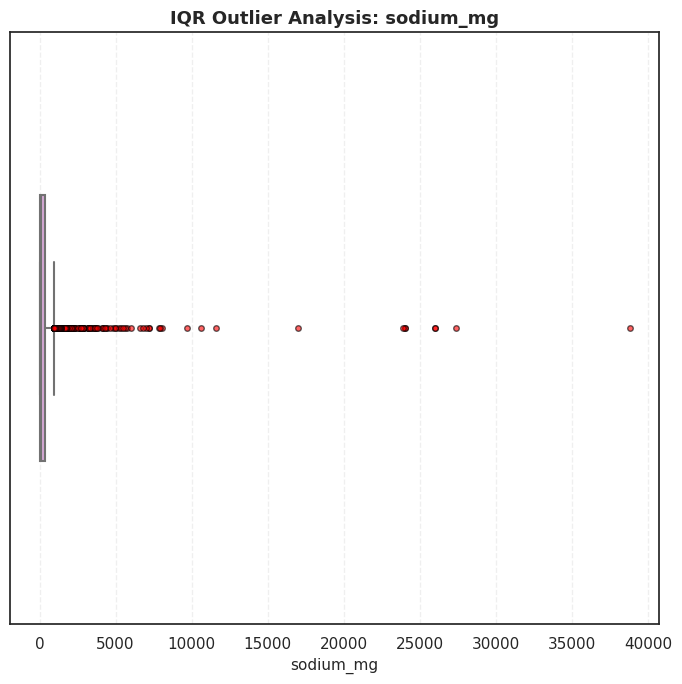

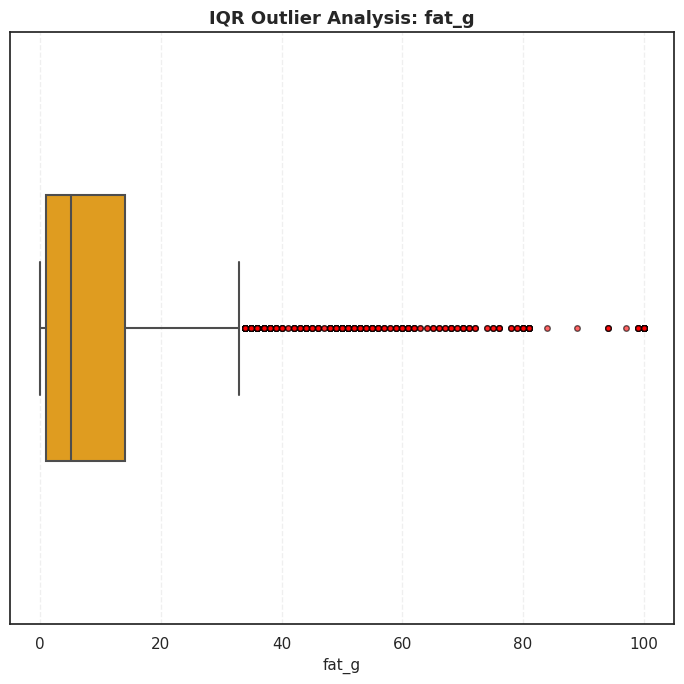

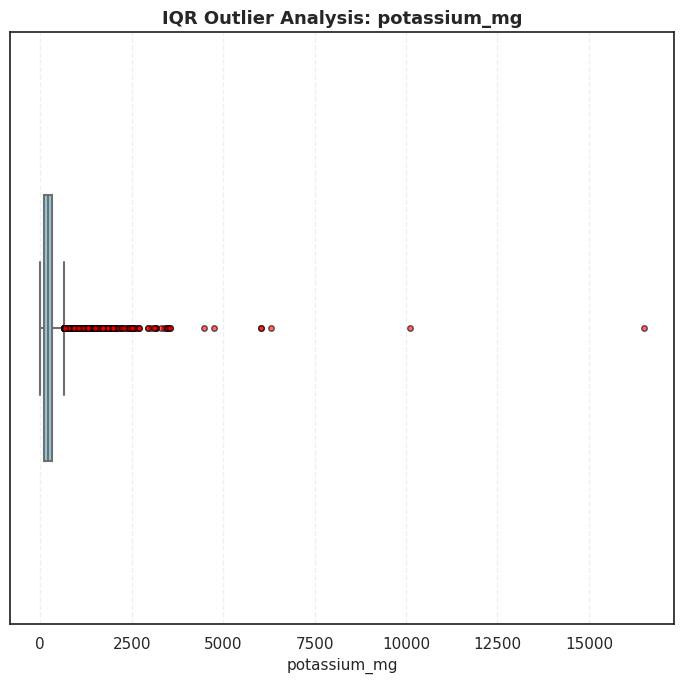

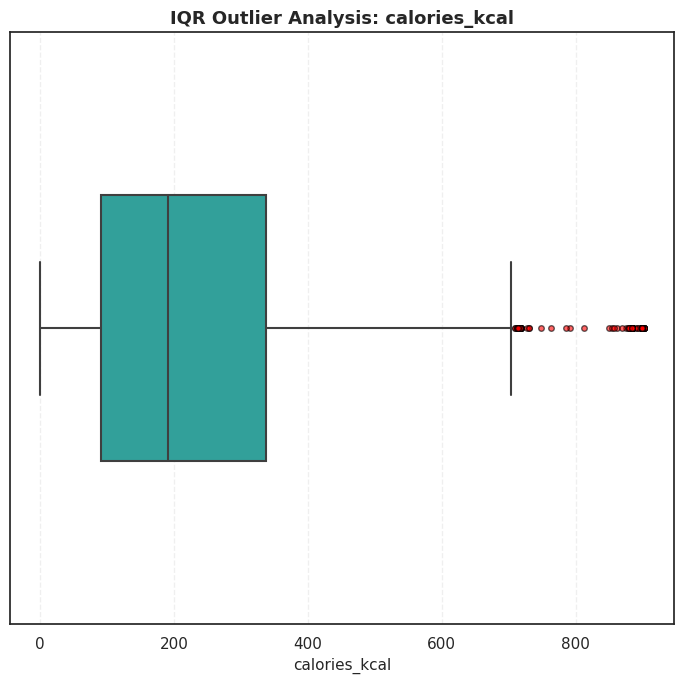

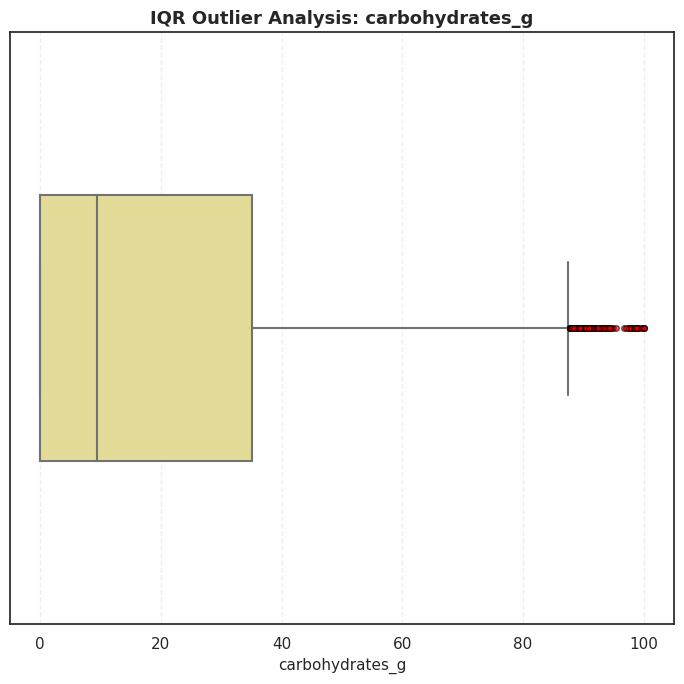

In [83]:
# Boxplots for up to 12 numerical variables with the largest IQR outlier counts

outlier_colors = [
    "cornflowerblue",
    "lightcoral",
    "mediumseagreen",
    "mediumpurple",
    "gold",
    "salmon",
    "turquoise",
    "plum",
    "orange",
    "skyblue",
    "lightseagreen",
    "khaki"
]

if not outlier_summary.empty:

    selected_outlier_cols = outlier_summary.head(12)["Attribute"].tolist()

    for i, col in enumerate(selected_outlier_cols):

        plt.figure(figsize=(7, 7))

        sns.boxplot(
            x=df_work[col],
            color=outlier_colors[i % len(outlier_colors)],
            width=0.45,
            linewidth=1.5,
            flierprops={
                "marker": "o",
                "markersize": 4,
                "markerfacecolor": "red",
                "markeredgecolor": "black",
                "alpha": 0.6
            }
        )

        plt.title(
            f"IQR Outlier Analysis: {col}",
            fontsize=13,
            fontweight="bold"
        )

        plt.xlabel(col, fontsize=11)
        plt.grid(axis="x", linestyle="--", alpha=0.3)

        plt.tight_layout()
        plt.show()

else:
    print("No suitable numerical attributes for IQR outlier detection.")

In [39]:
# Z-score flags as a supplementary method (sensitive to skewness and non-normal data).
from scipy.stats import zscore

zscore_rows = []
for col in numeric_cols:
    s = df_work[col].replace([np.inf, -np.inf], np.nan)
    valid = s.dropna()
    if len(valid) >= 3 and valid.std(ddof=0) > 0:
        z = pd.Series(zscore(valid, nan_policy="omit"), index=valid.index)
        zscore_rows.append({
            "Attribute": col,
            "Absolute Z-score > 3": int((z.abs() > 3).sum())
        })

display(pd.DataFrame(zscore_rows))

,Attribute,Absolute Z-score > 3
0,calories_kcal,119
1,protein_g,52
2,carbohydrates_g,0
3,fat_g,215
4,fiber_g,156
5,calcium_mg,156
6,iron_mg,189
7,potassium_mg,111
8,sodium_mg,49
9,vitamin_c_mg,23


### D5. Data cleaning and validation

This section applies conservative corrections:
- Trim surrounding whitespace in text fields.
- Replace positive/negative infinity with missing values.
- Remove exact duplicate records from the working copy.
- Do not delete outliers automatically.
- Do not remove rows with missing values globally; imputation is handled inside modelling pipelines.
- Do not standardise spelling variants automatically unless the intended category is verified.

In [40]:
df_clean = df_work.copy()

for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

df_clean = df_clean.replace([np.inf, -np.inf], np.nan)
duplicates_before = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Duplicate records removed:", duplicates_before)
print("Shape before cleaning:", df_work.shape)
print("Shape after exact-duplicate removal:", df_clean.shape)
print("Remaining missing cells:", int(df_clean.isna().sum().sum()))

Duplicate records removed: 0
Shape before cleaning: (8779, 26)
Shape after exact-duplicate removal: (8779, 26)
Remaining missing cells: 136


In [41]:
# Final data quality summary
quality_summary = pd.DataFrame({
    "Measure": [
        "Rows after cleaning",
        "Columns",
        "Duplicate rows remaining",
        "Total missing cells",
        "Columns containing missing values",
        "Numeric columns",
        "Categorical columns"
    ],
    "Result": [
        len(df_clean),
        df_clean.shape[1],
        int(df_clean.duplicated().sum()),
        int(df_clean.isna().sum().sum()),
        int(df_clean.isna().any().sum()),
        len(df_clean.select_dtypes(include=np.number).columns),
        len(df_clean.select_dtypes(include=["object", "category", "bool"]).columns)
    ]
})
display(quality_summary)

,Measure,Result
0,Rows after cleaning,8779
1,Columns,26
2,Duplicate rows remaining,0
3,Total missing cells,136
4,Columns containing missing values,5
5,Numeric columns,14
6,Categorical columns,12


## PART E – EXPLORATORY DATA ANALYSIS (EDA)

EDA is selected to examine the actual variables in the fused dataset. The analysis should pay particular attention to API-added variables and relationships between verified original-source and API-source attributes.

### E1. Univariate analysis

In [42]:
eda_numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

if eda_numeric_cols:
    numeric_summary = df_clean[eda_numeric_cols].describe().T
    numeric_summary["median"] = df_clean[eda_numeric_cols].median()
    numeric_summary["variance"] = df_clean[eda_numeric_cols].var()
    display(numeric_summary)
else:
    print("No numerical columns are available for numerical univariate analysis.")

,count,mean,std,min,25%,50%,75%,max,median,variance
calories_kcal,8779.0,2.262419e+02,1.697758e+02,0.0,91.00,1.910000e+02,3.370000e+02,9.020000e+02,1.910000e+02,2.882384e+04
protein_g,8779.0,1.133746e+01,1.052894e+01,0.0,2.38,8.000000e+00,1.987000e+01,8.832000e+01,8.000000e+00,1.108587e+02
carbohydrates_g,8779.0,2.214446e+01,2.727258e+01,0.0,0.05,9.380000e+00,3.506500e+01,1.000000e+02,9.380000e+00,7.437935e+02
fat_g,8779.0,1.054601e+01,1.579362e+01,0.0,1.00,5.100000e+00,1.400000e+01,1.000000e+02,5.100000e+00,2.494384e+02
fiber_g,8779.0,2.043650e+00,4.270791e+00,0.0,0.00,4.000000e-01,2.400000e+00,7.900000e+01,4.000000e-01,1.823966e+01
calcium_mg,8763.0,7.393674e+01,2.000256e+02,0.0,9.00,2.000000e+01,6.500000e+01,7.364000e+03,2.000000e+01,4.001026e+04
iron_mg,8764.0,2.647761e+00,5.663766e+00,0.0,0.50,1.310000e+00,2.560000e+00,1.240000e+02,1.310000e+00,3.207824e+01
potassium_mg,8753.0,2.678418e+02,3.688140e+02,0.0,115.00,2.230000e+02,3.310000e+02,1.650000e+04,2.230000e+02,1.360238e+05
sodium_mg,8767.0,3.068886e+02,9.405074e+02,0.0,37.00,8.400000e+01,3.910000e+02,3.880000e+04,8.400000e+01,8.845543e+05
vitamin_c_mg,8712.0,8.448145e+00,6.592299e+01,0.0,0.00,0.000000e+00,2.600000e+00,2.732000e+03,0.000000e+00,4.345841e+03


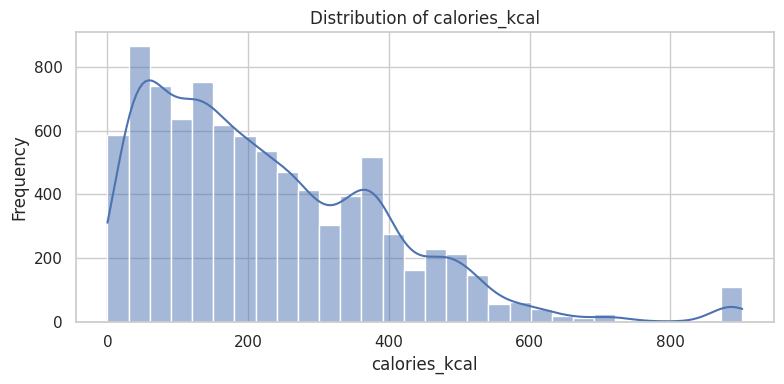

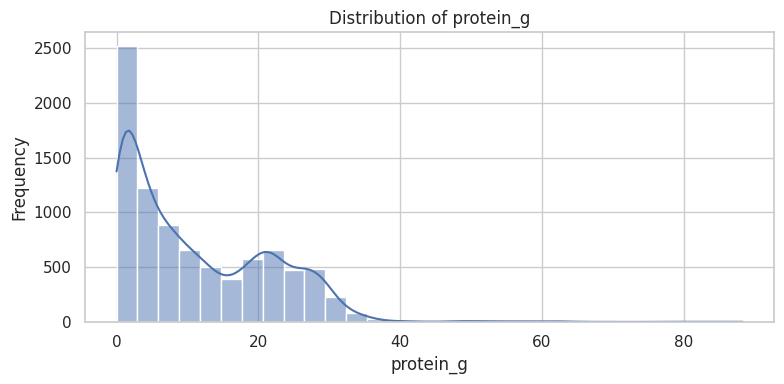

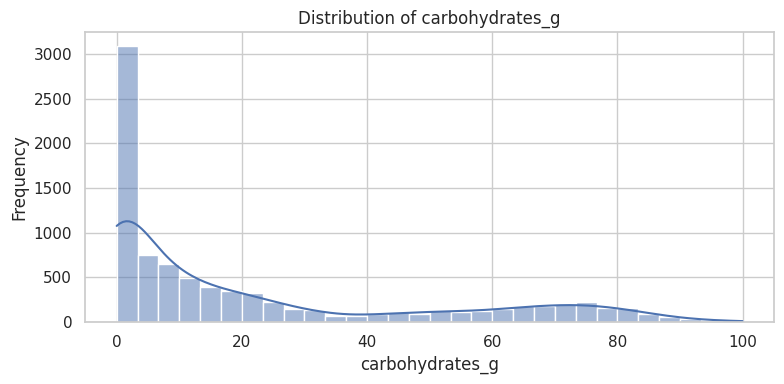

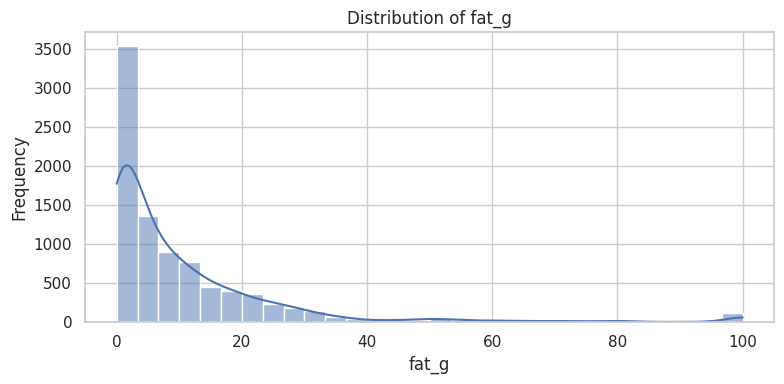

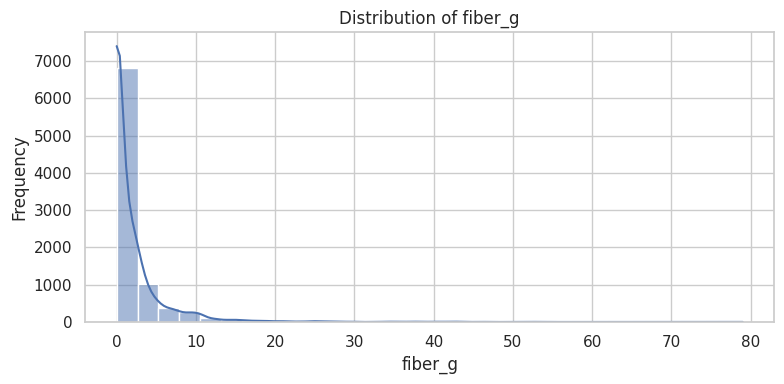

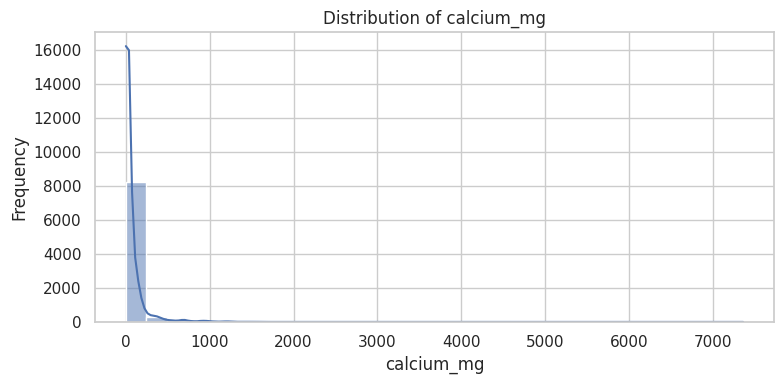

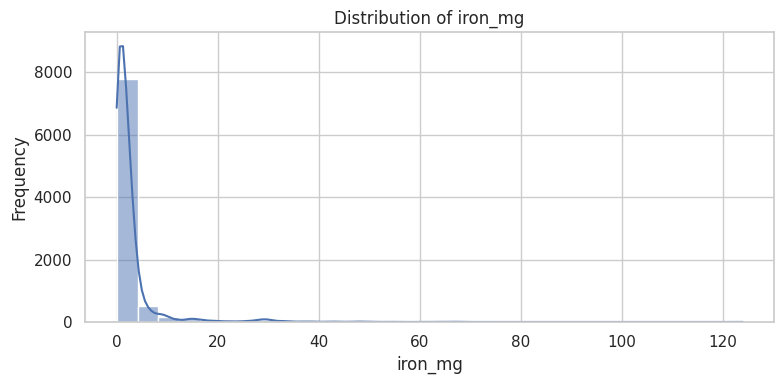

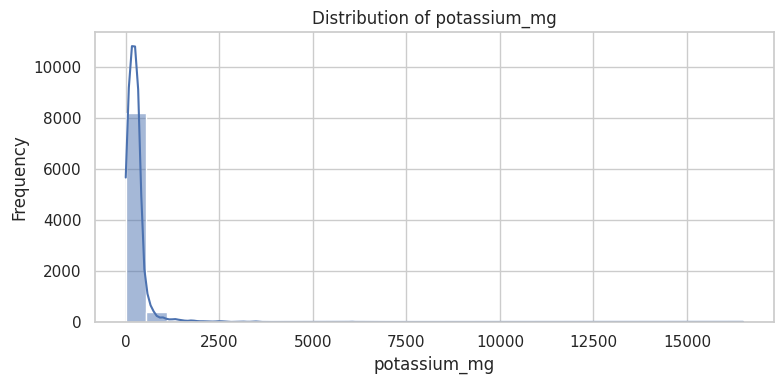

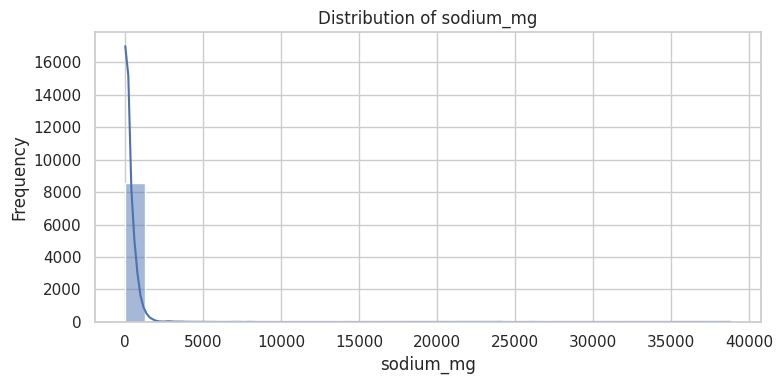

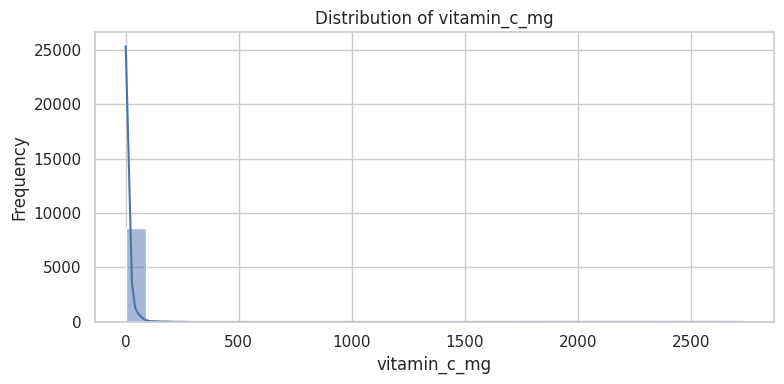

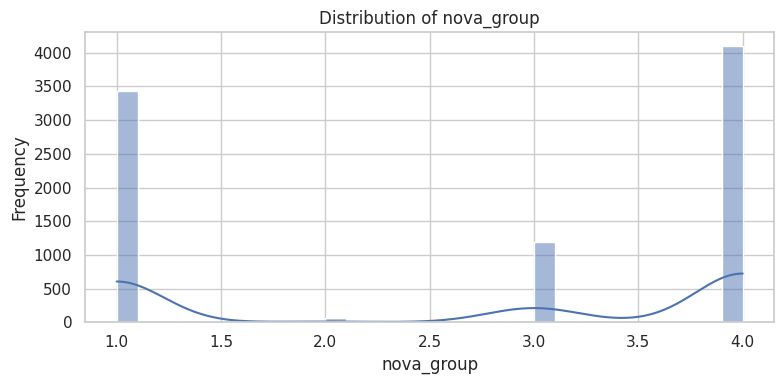

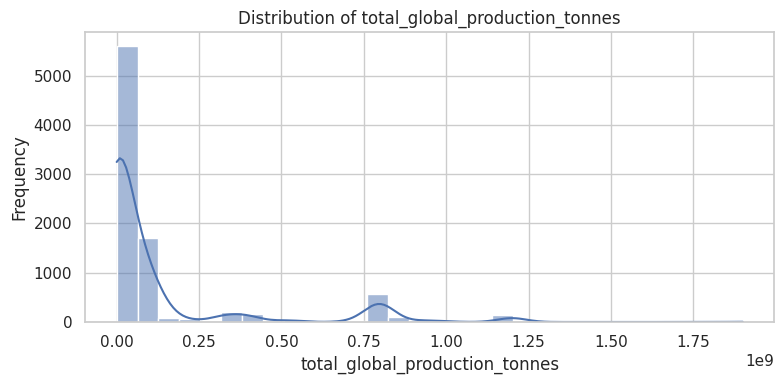

In [43]:
# Histograms for numerical attributes (up to 12 columns).
for col in eda_numeric_cols[:12]:
    values = df_clean[col].dropna()
    if len(values) == 0:
        continue
    plt.figure(figsize=(8, 4))
    sns.histplot(values, kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

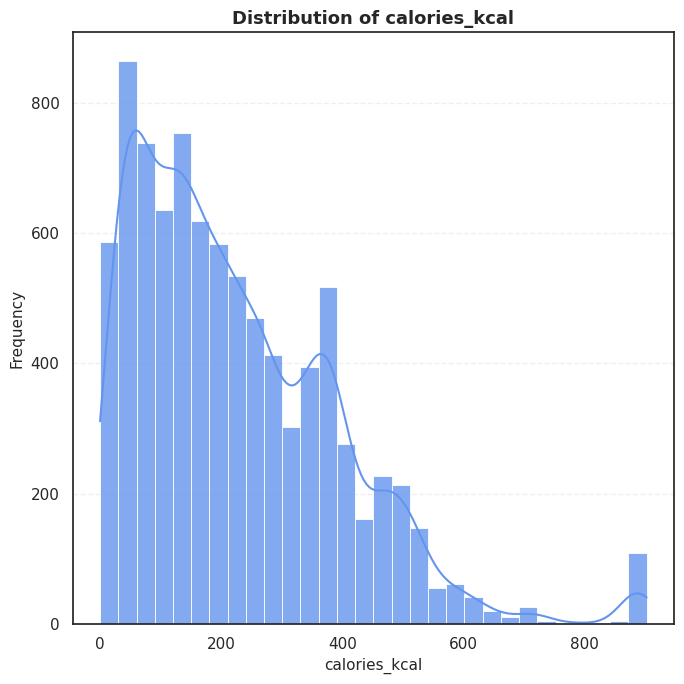

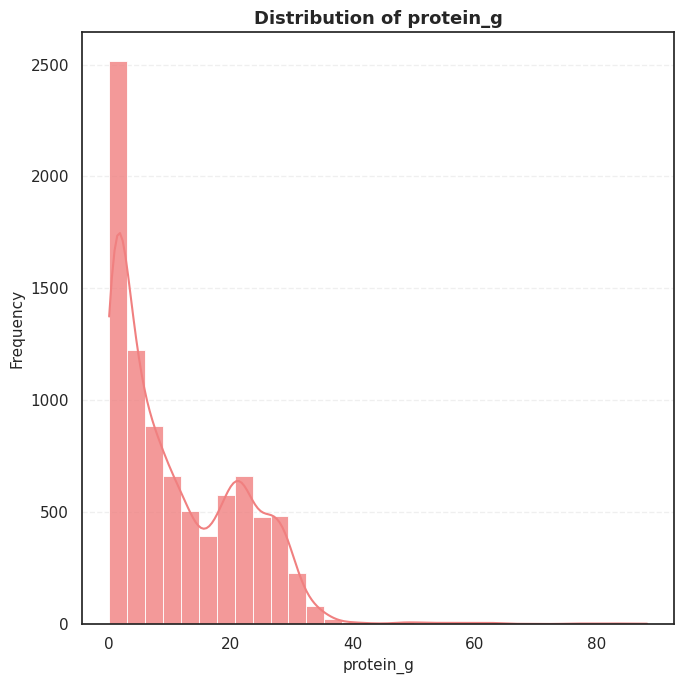

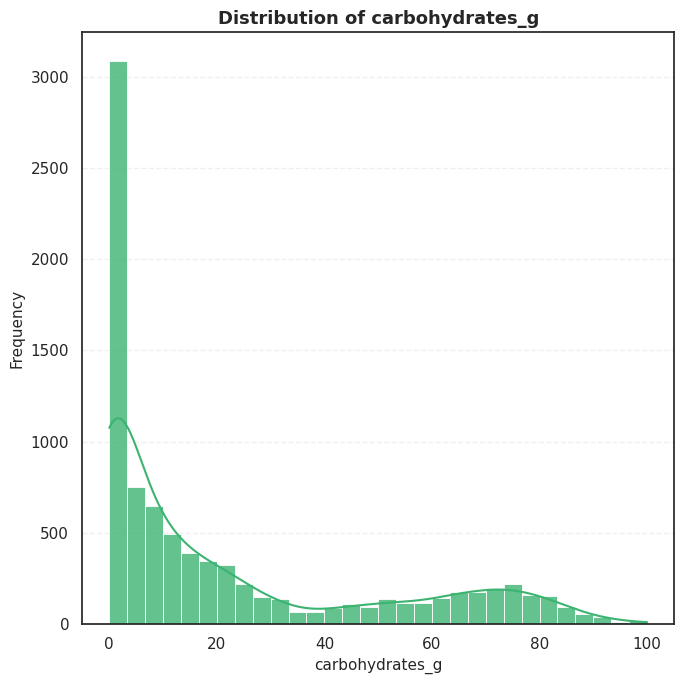

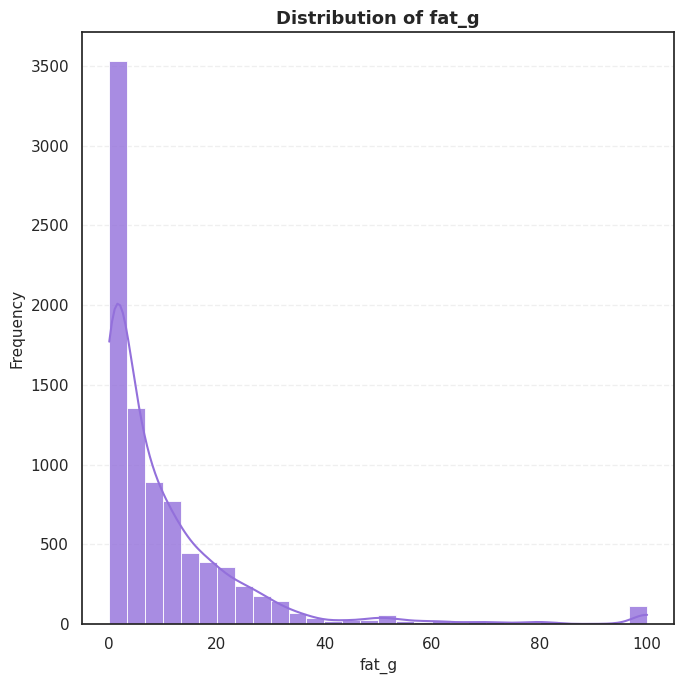

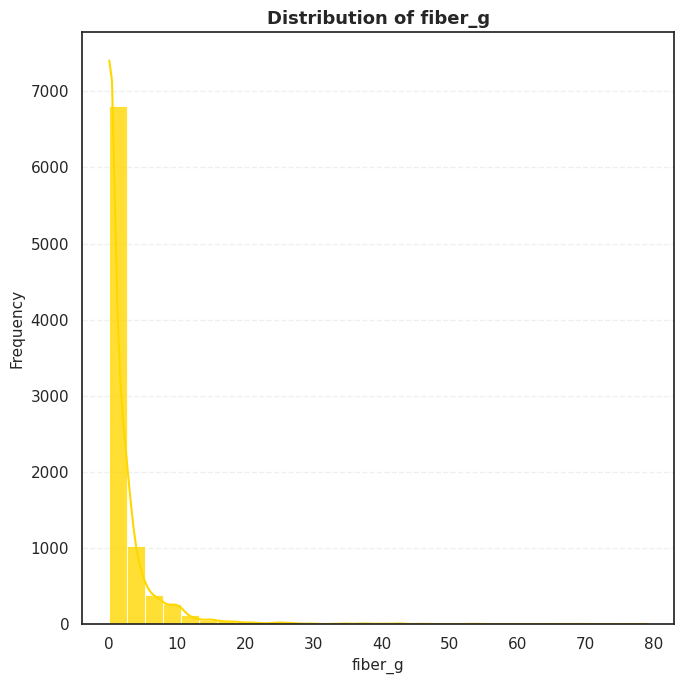

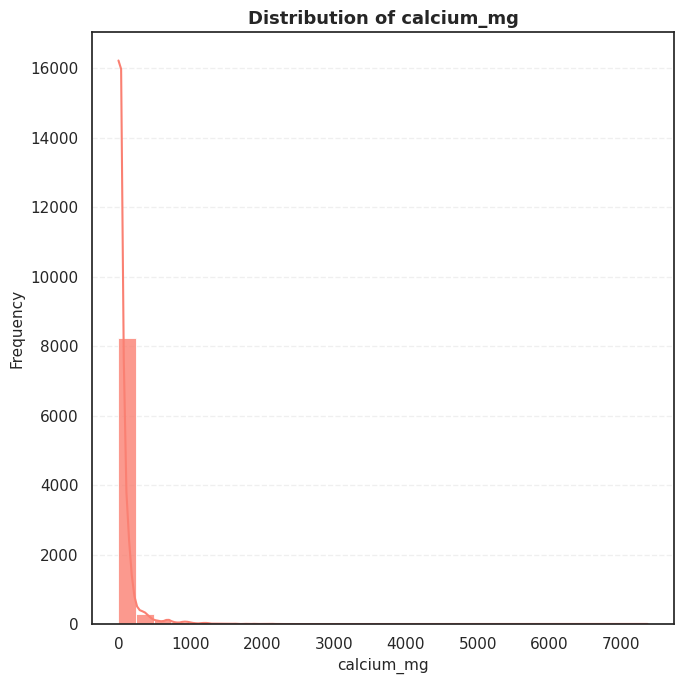

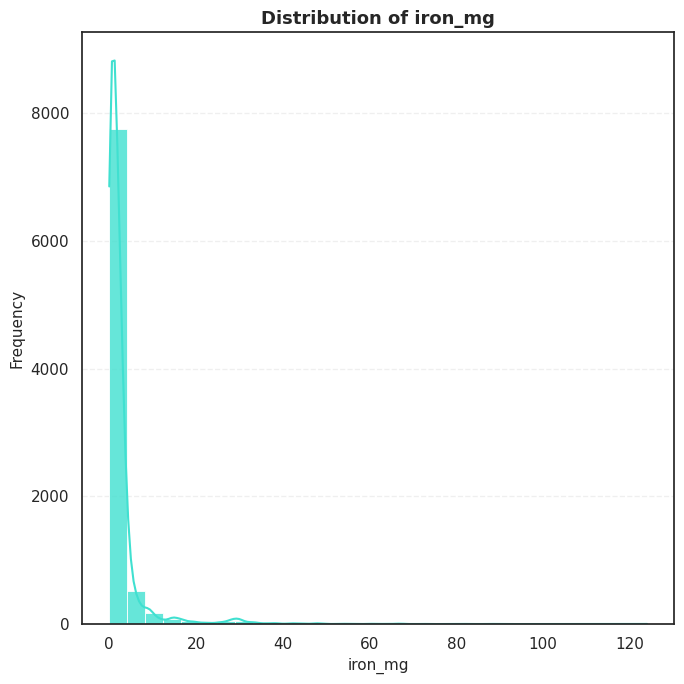

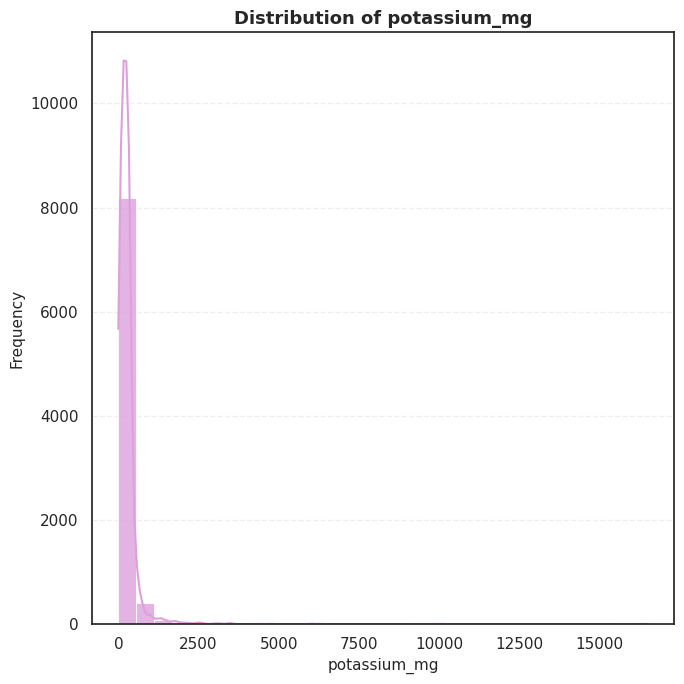

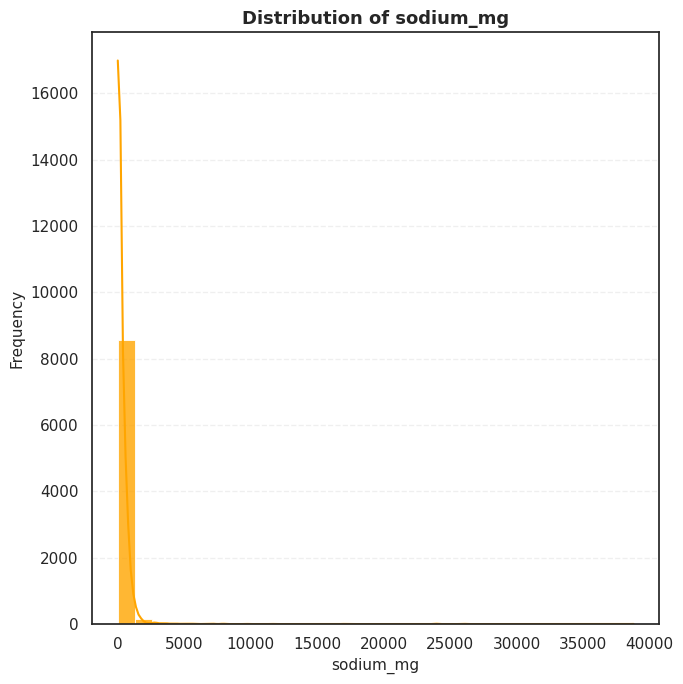

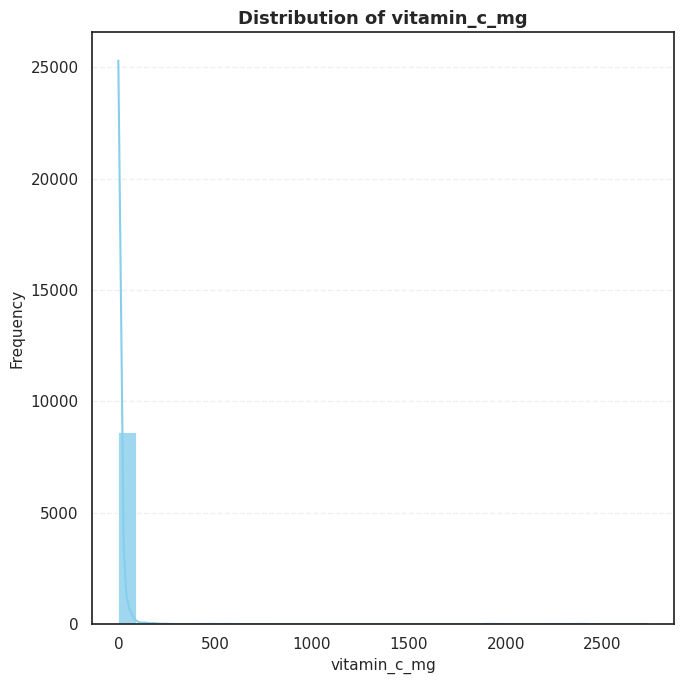

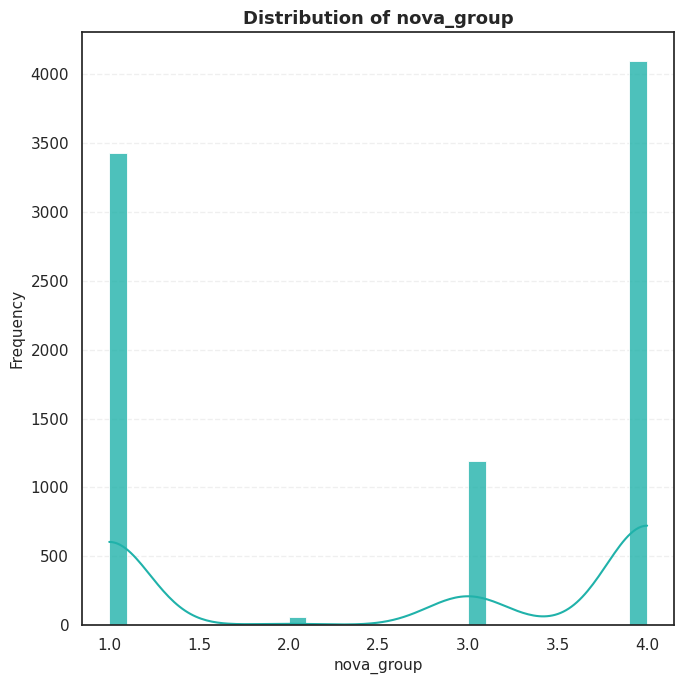

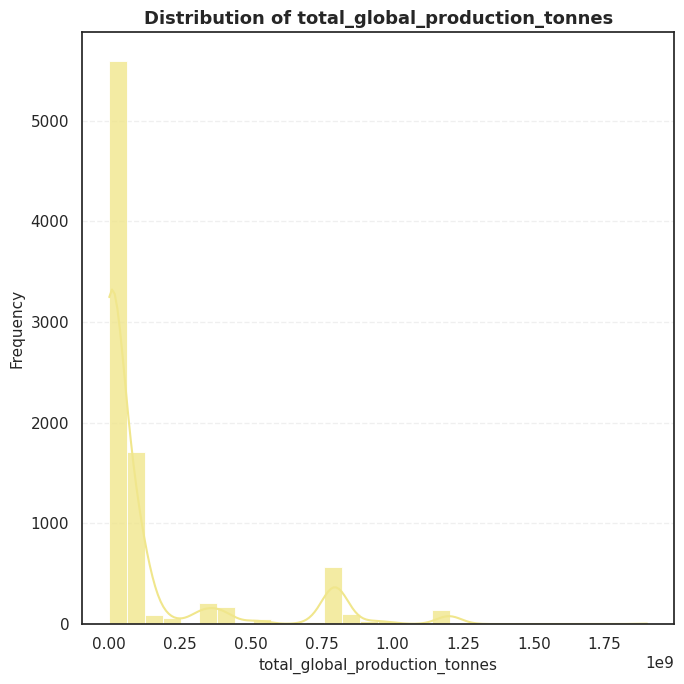

In [82]:
# Histograms for numerical attributes (up to 12 columns)

hist_colors = [
    "cornflowerblue",
    "lightcoral",
    "mediumseagreen",
    "mediumpurple",
    "gold",
    "salmon",
    "turquoise",
    "plum",
    "orange",
    "skyblue",
    "lightseagreen",
    "khaki"
]

for i, col in enumerate(eda_numeric_cols[:12]):

    values = df_clean[col].dropna()

    if len(values) == 0:
        continue

    plt.figure(figsize=(7, 7))

    sns.histplot(
        values,
        kde=True,
        bins=30,
        color=hist_colors[i % len(hist_colors)],
        edgecolor="white",
        linewidth=0.6,
        alpha=0.8
    )

    plt.title(f"Distribution of {col}", fontsize=13, fontweight="bold")
    plt.xlabel(col, fontsize=11)
    plt.ylabel("Frequency", fontsize=11)

    plt.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()

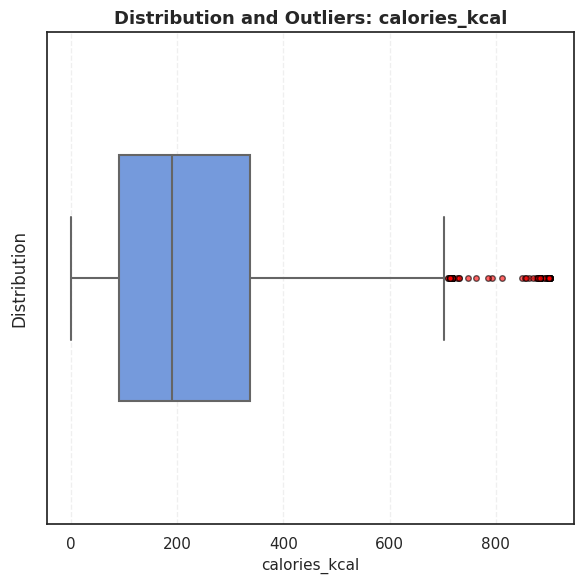

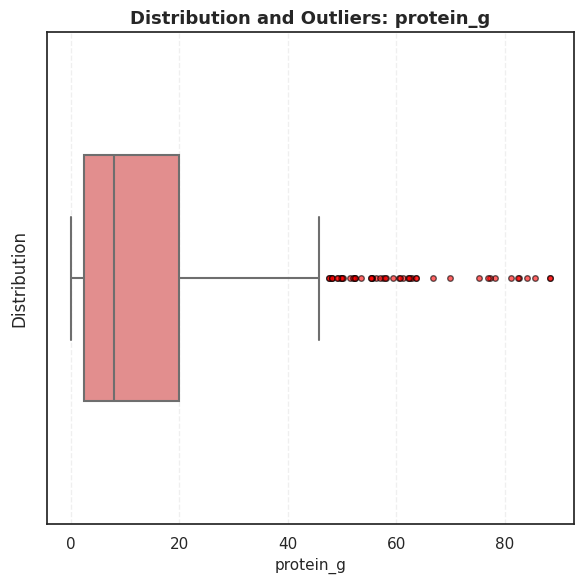

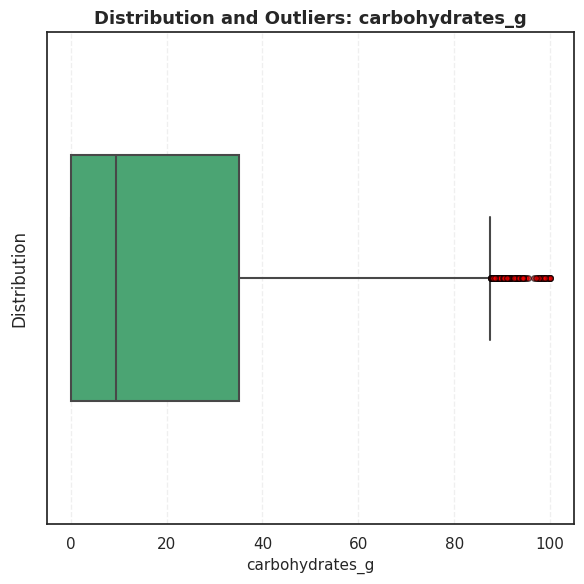

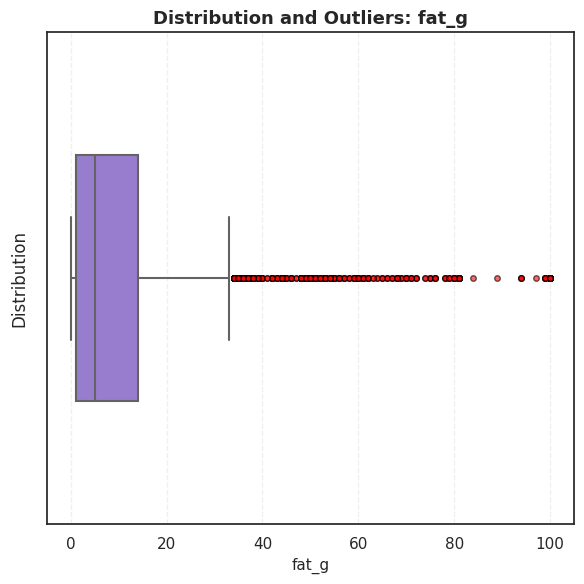

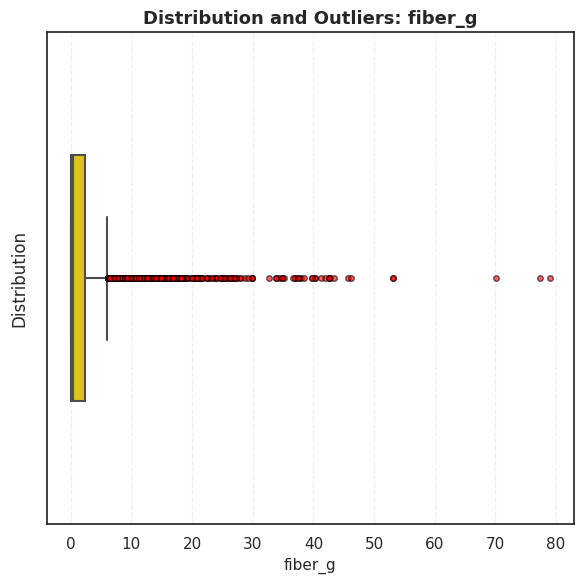

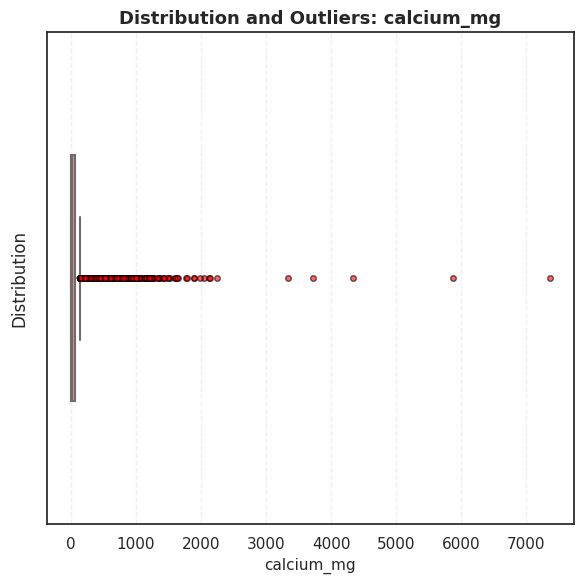

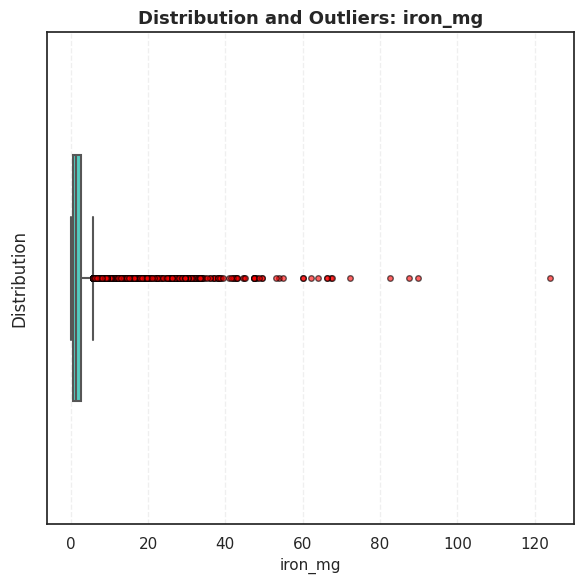

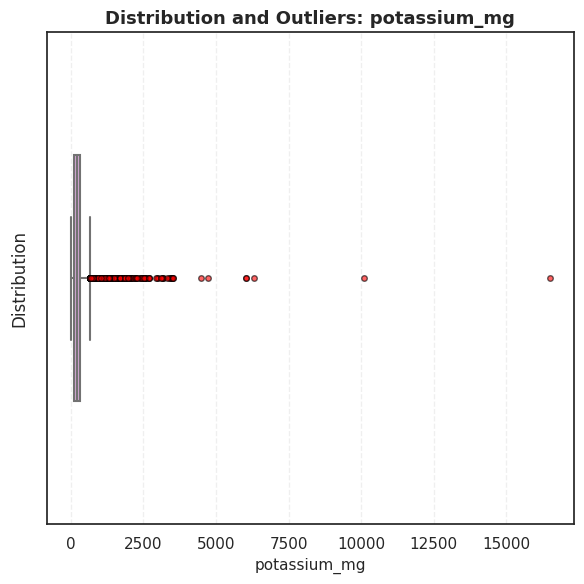

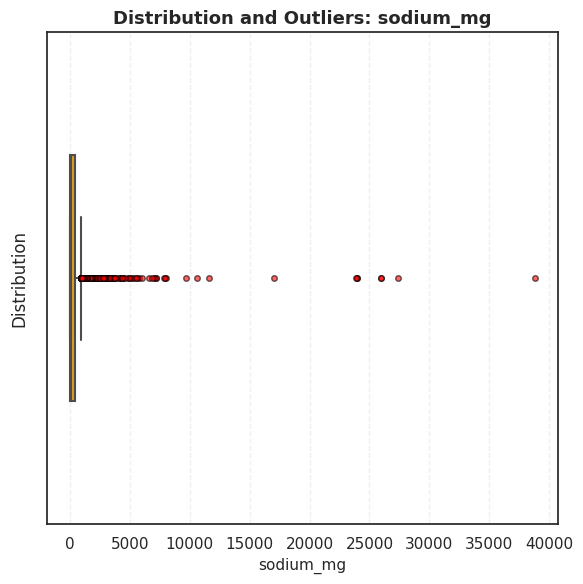

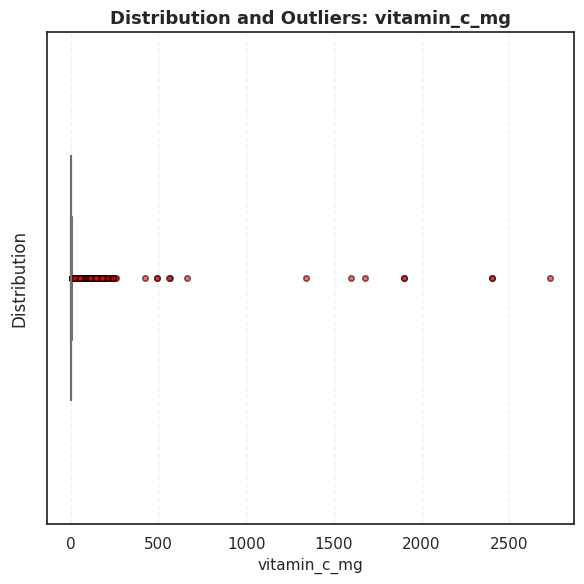

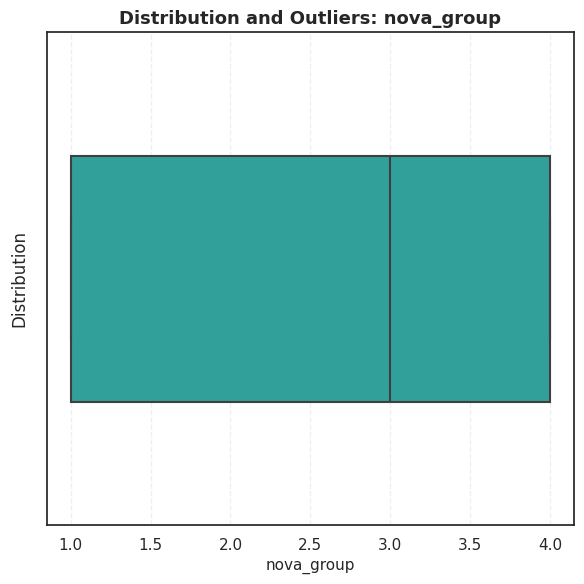

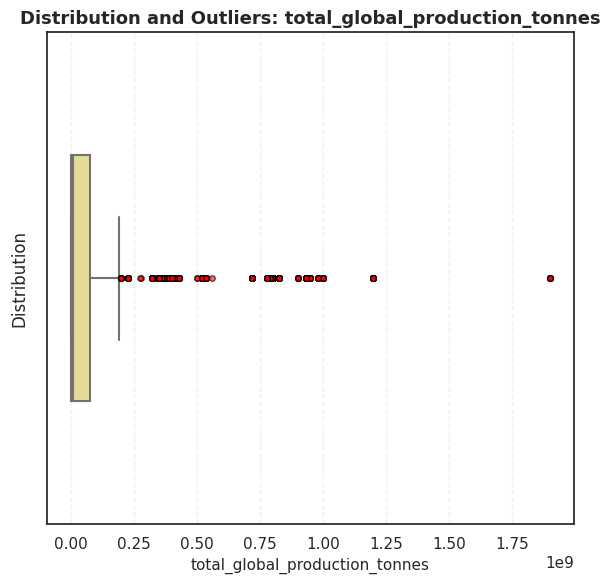

In [80]:
# Boxplots for numerical attributes (up to 12 columns)

boxplot_colors = [
    "cornflowerblue",
    "lightcoral",
    "mediumseagreen",
    "mediumpurple",
    "gold",
    "salmon",
    "turquoise",
    "plum",
    "orange",
    "skyblue",
    "lightseagreen",
    "khaki"
]

for i, col in enumerate(eda_numeric_cols[:12]):

    if df_clean[col].notna().sum() == 0:
        continue

    plt.figure(figsize=(6, 6))

    sns.boxplot(
        x=df_clean[col],
        color=boxplot_colors[i % len(boxplot_colors)],
        width=0.5,
        linewidth=1.5,
        flierprops={
            "marker": "o",
            "markersize": 4,
            "markerfacecolor": "red",
            "markeredgecolor": "black",
            "alpha": 0.6
        }
    )

    plt.title(f"Distribution and Outliers: {col}", fontsize=13, fontweight="bold")
    plt.xlabel(col, fontsize=11)
    plt.ylabel("Distribution")
    plt.grid(axis="x", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()

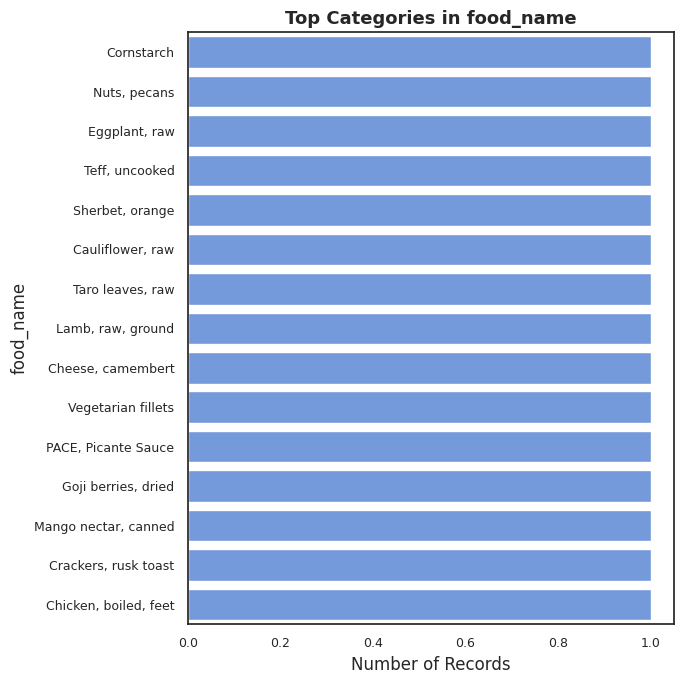

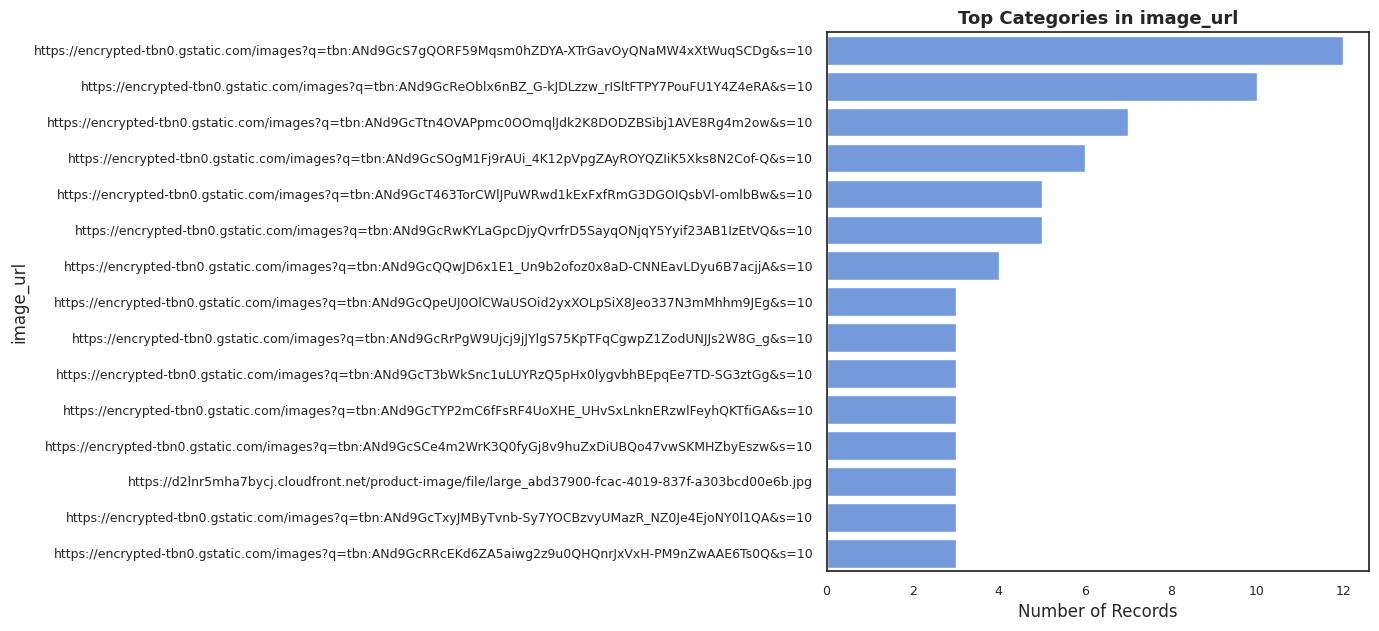

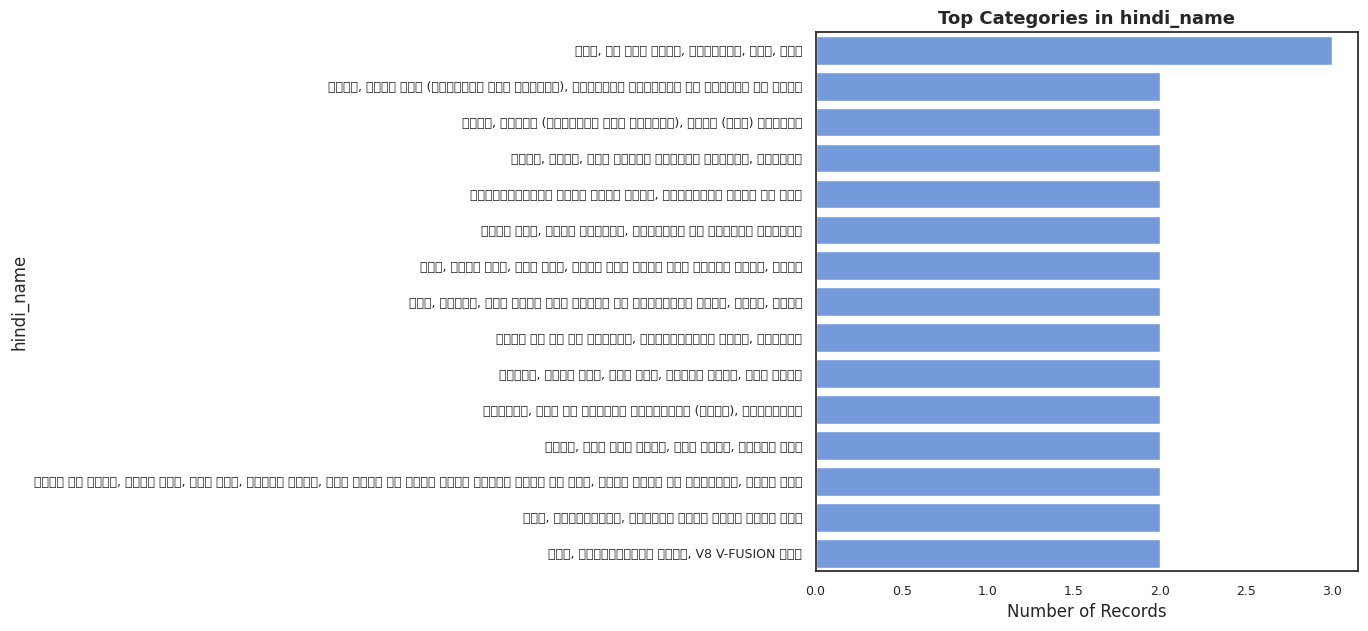

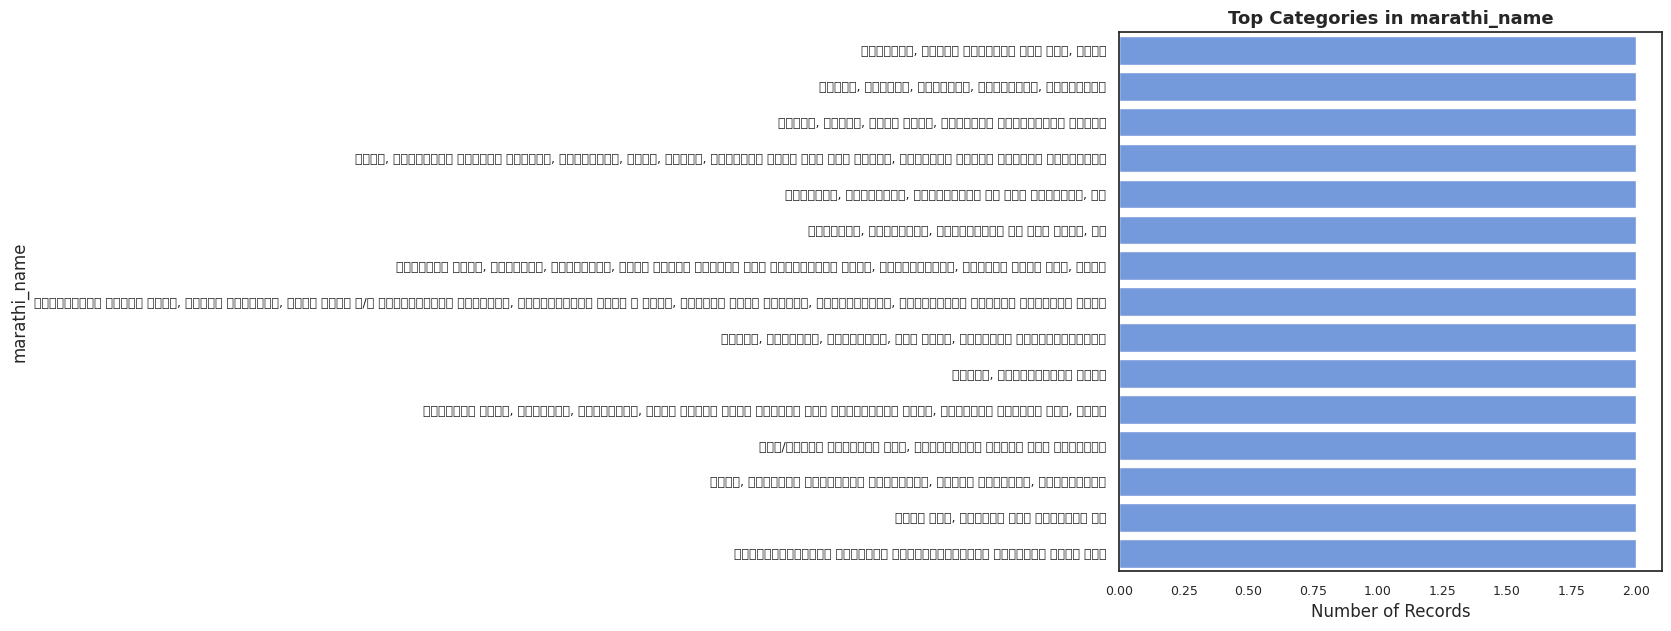

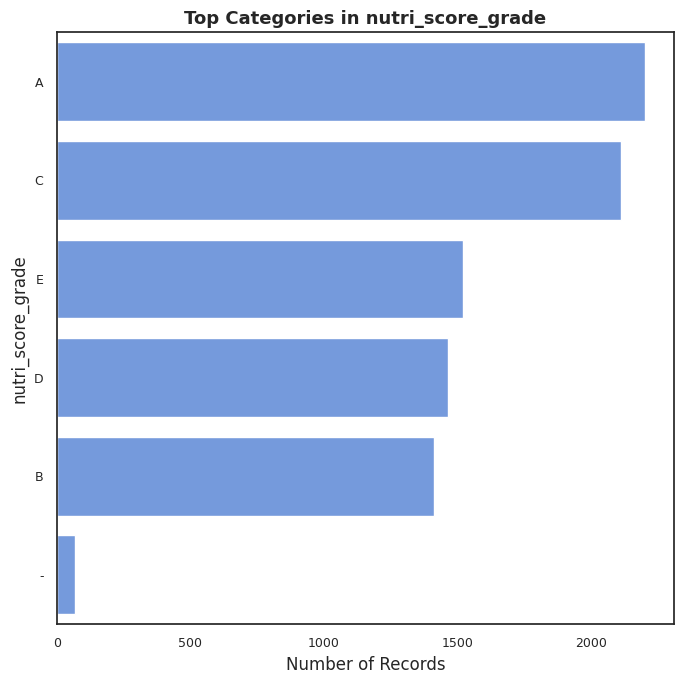

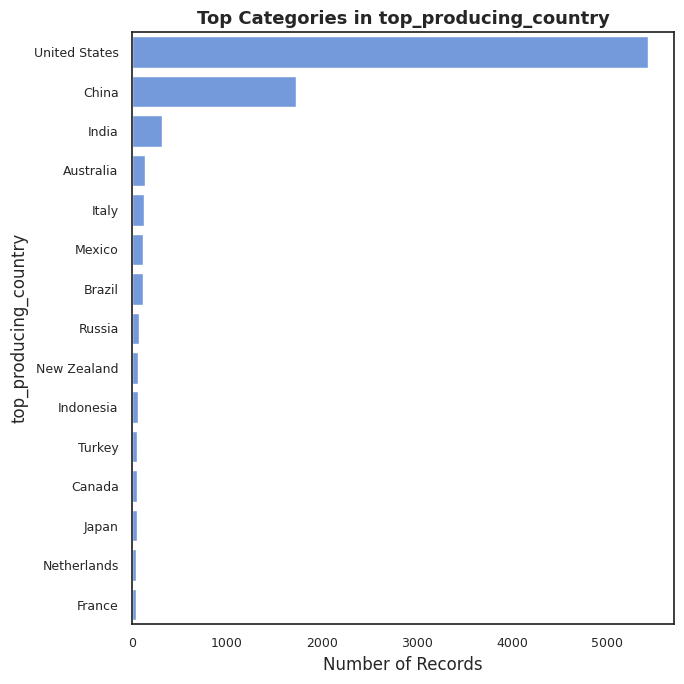

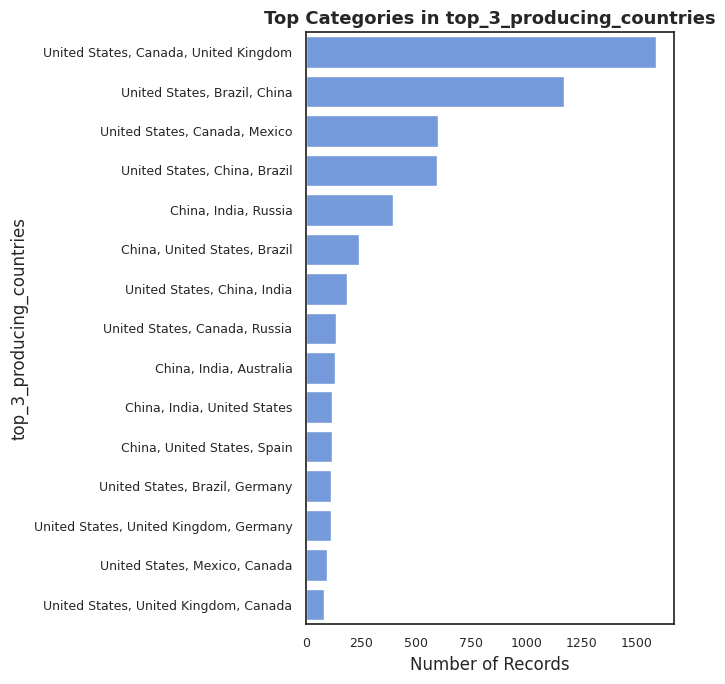

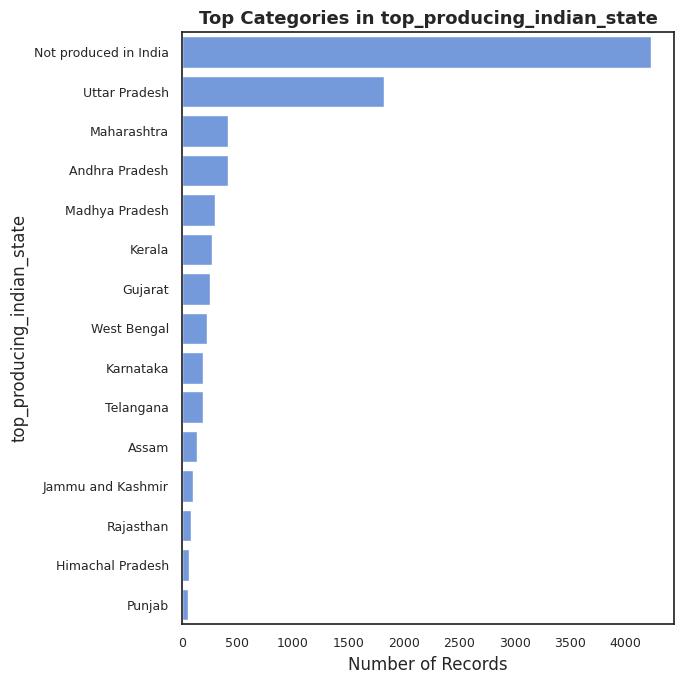

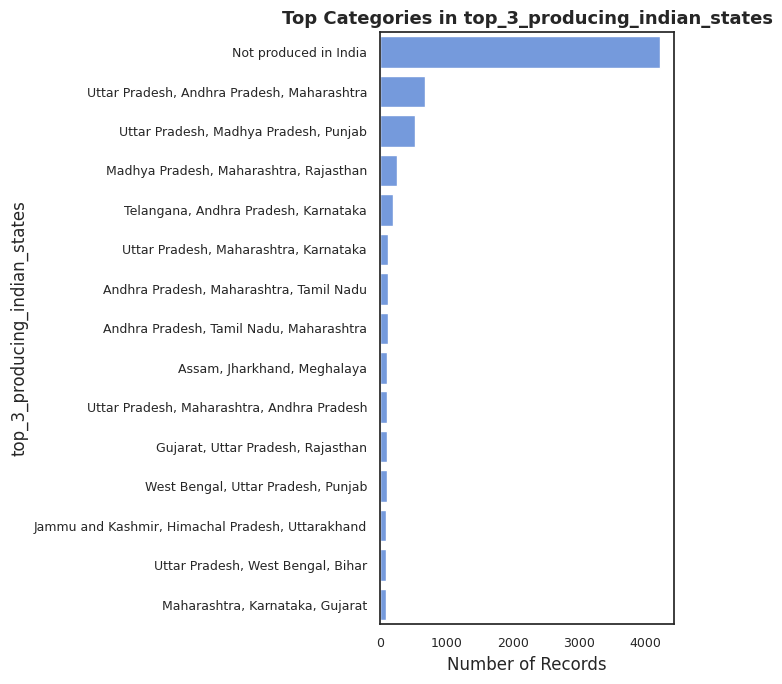

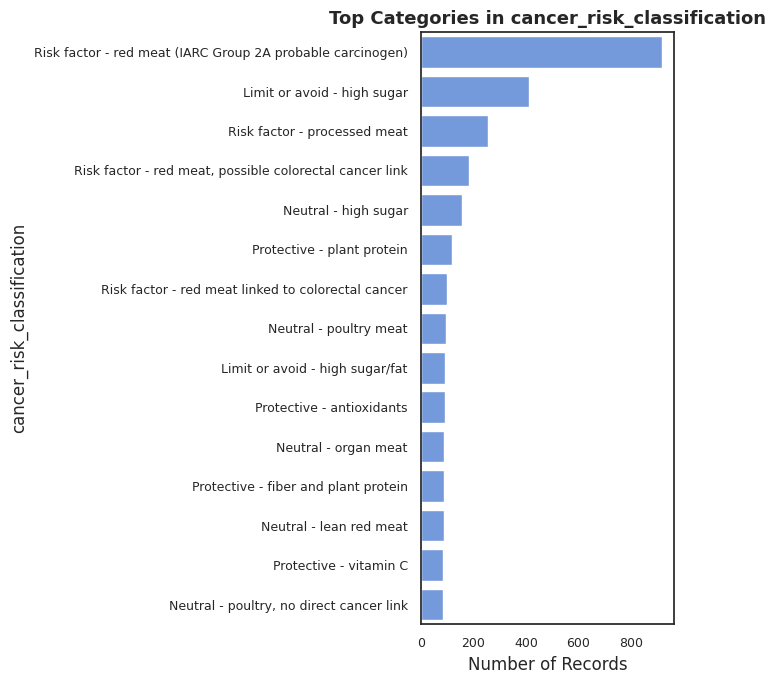

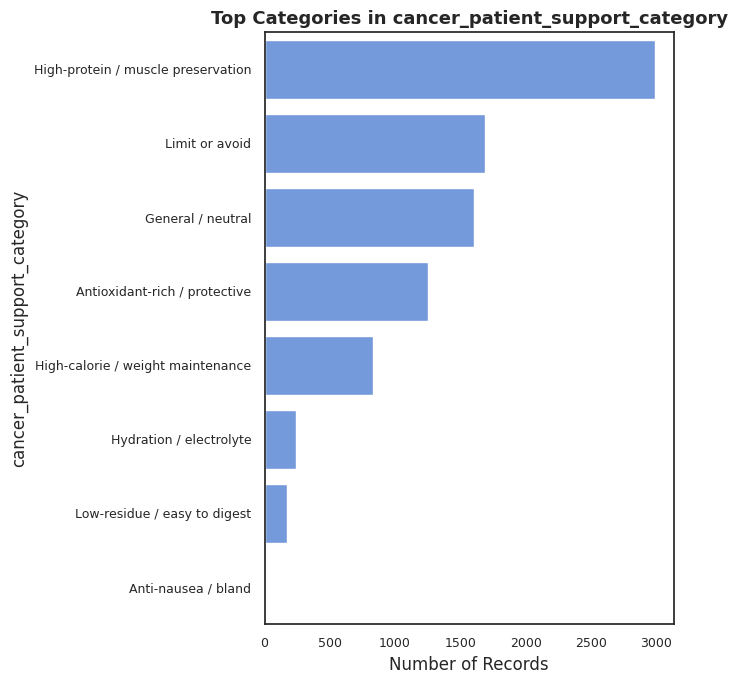

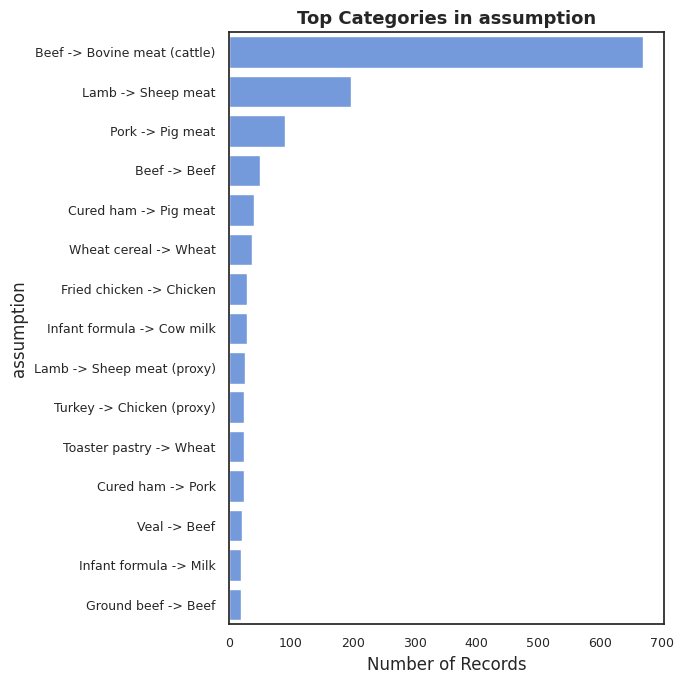

In [79]:
# Bar charts for categorical variables with manageable cardinality
eda_cat_cols = df_clean.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

for col in eda_cat_cols:

    counts = df_clean[col].value_counts(dropna=False).head(15)

    if len(counts) == 0:
        continue

    plt.figure(figsize=(7, 7))

    sns.barplot(
        x=counts.values,
        y=counts.index.astype(str),
        color="cornflowerblue"
    )

    plt.title(f"Top Categories in {col}", fontsize=13, fontweight="bold")
    plt.xlabel("Number of Records")
    plt.ylabel(col)

    plt.yticks(fontsize=9)
    plt.xticks(fontsize=9)

    plt.tight_layout()
    plt.show()

### E2. Bivariate analysis

The notebook first checks relationships between numeric attributes. For categorical variables, it compares selected numerical measurements across groups. Interpret associations as relationships, not proof of causation.

,calories_kcal,protein_g,carbohydrates_g,fat_g,fiber_g,calcium_mg,iron_mg,potassium_mg,sodium_mg,vitamin_c_mg,nova_group,total_global_production_tonnes,india_total_production_tonnes,india_s_share_in_global_production
calories_kcal,1.000000,0.114149,0.493676,0.806175,0.202256,0.125146,0.196661,0.082056,0.054923,-0.032684,0.243640,0.103798,0.073190,-0.048276
protein_g,0.114149,1.000000,-0.303569,0.063620,-0.073829,0.043002,0.128414,0.245872,-0.001515,-0.064598,-0.427167,-0.085612,-0.120939,-0.083177
carbohydrates_g,0.493676,-0.303569,1.000000,-0.048491,0.455746,0.189107,0.340096,0.118257,0.072107,0.069649,0.460482,0.247634,0.234832,0.052688
fat_g,0.806175,0.063620,-0.048491,1.000000,-0.022977,0.018211,-0.032340,-0.035811,0.011967,-0.057040,0.073312,-0.034152,-0.052395,-0.062197
fiber_g,0.202256,-0.073829,0.455746,-0.022977,1.000000,0.232401,0.378883,0.323585,0.009341,0.067131,0.055902,0.069829,0.050558,0.134773
calcium_mg,0.125146,0.043002,0.189107,0.018211,0.232401,1.000000,0.348886,0.248843,0.177197,0.094921,0.136831,0.076619,0.109569,0.080856
iron_mg,0.196661,0.128414,0.340096,-0.032340,0.378883,0.348886,1.000000,0.233554,0.028836,0.060633,0.038477,0.107762,0.076854,0.077528
potassium_mg,0.082056,0.245872,0.118257,-0.035811,0.323585,0.248843,0.233554,1.000000,0.006018,0.152023,-0.150073,-0.041604,-0.027038,0.088501
sodium_mg,0.054923,-0.001515,0.072107,0.011967,0.009341,0.177197,0.028836,0.006018,1.000000,-0.017267,0.199243,0.015233,0.008239,-0.042565
vitamin_c_mg,-0.032684,-0.064598,0.069649,-0.057040,0.067131,0.094921,0.060633,0.152023,-0.017267,1.000000,-0.014147,-0.017612,-0.007036,0.039998


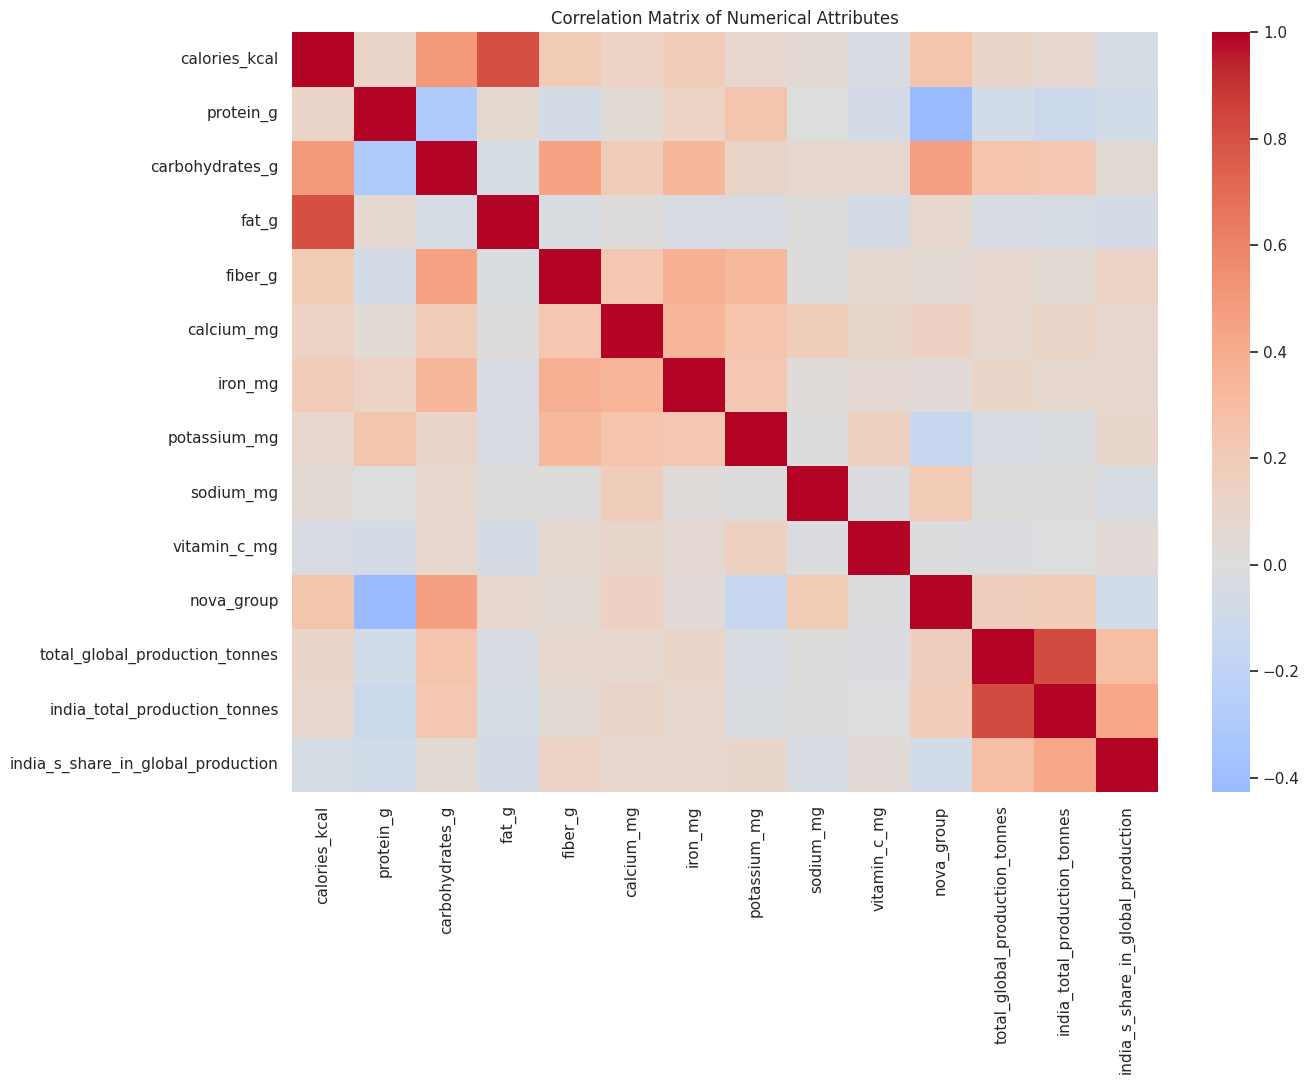

In [46]:
# Correlation matrix for numerical variables.
if len(eda_numeric_cols) >= 2:
    corr = df_clean[eda_numeric_cols].corr(method="pearson")
    display(corr)
    plt.figure(figsize=(min(14, 1 + len(eda_numeric_cols)), min(11, 1 + len(eda_numeric_cols))))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=(len(eda_numeric_cols) <= 12),
                fmt=".2f", square=False)
    plt.title("Correlation Matrix of Numerical Attributes")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are required for correlation analysis.")

,calories_kcal,protein_g,carbohydrates_g,fat_g,fiber_g,calcium_mg,iron_mg,potassium_mg,sodium_mg,vitamin_c_mg,nova_group,total_global_production_tonnes,india_total_production_tonnes,india_s_share_in_global_production
calories_kcal,1.000000,0.114149,0.493676,0.806175,0.202256,0.125146,0.196661,0.082056,0.054923,-0.032684,0.243640,0.103798,0.073190,-0.048276
protein_g,0.114149,1.000000,-0.303569,0.063620,-0.073829,0.043002,0.128414,0.245872,-0.001515,-0.064598,-0.427167,-0.085612,-0.120939,-0.083177
carbohydrates_g,0.493676,-0.303569,1.000000,-0.048491,0.455746,0.189107,0.340096,0.118257,0.072107,0.069649,0.460482,0.247634,0.234832,0.052688
fat_g,0.806175,0.063620,-0.048491,1.000000,-0.022977,0.018211,-0.032340,-0.035811,0.011967,-0.057040,0.073312,-0.034152,-0.052395,-0.062197
fiber_g,0.202256,-0.073829,0.455746,-0.022977,1.000000,0.232401,0.378883,0.323585,0.009341,0.067131,0.055902,0.069829,0.050558,0.134773
calcium_mg,0.125146,0.043002,0.189107,0.018211,0.232401,1.000000,0.348886,0.248843,0.177197,0.094921,0.136831,0.076619,0.109569,0.080856
iron_mg,0.196661,0.128414,0.340096,-0.032340,0.378883,0.348886,1.000000,0.233554,0.028836,0.060633,0.038477,0.107762,0.076854,0.077528
potassium_mg,0.082056,0.245872,0.118257,-0.035811,0.323585,0.248843,0.233554,1.000000,0.006018,0.152023,-0.150073,-0.041604,-0.027038,0.088501
sodium_mg,0.054923,-0.001515,0.072107,0.011967,0.009341,0.177197,0.028836,0.006018,1.000000,-0.017267,0.199243,0.015233,0.008239,-0.042565
vitamin_c_mg,-0.032684,-0.064598,0.069649,-0.057040,0.067131,0.094921,0.060633,0.152023,-0.017267,1.000000,-0.014147,-0.017612,-0.007036,0.039998


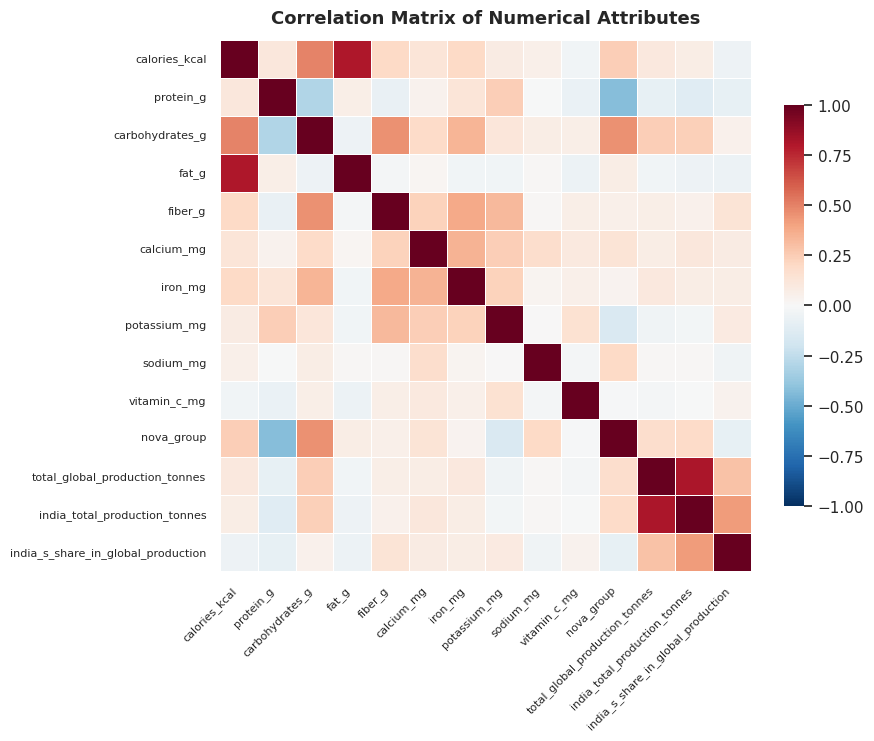

In [78]:
# Correlation matrix for numerical variables.
if len(eda_numeric_cols) >= 2:
    corr = df_clean[eda_numeric_cols].corr(method="pearson")
    display(corr)

    n = len(eda_numeric_cols)

    plt.figure(figsize=(max(8, min(12, n * 0.65)),
                        max(6, min(10, n * 0.55))))

    sns.heatmap(
        corr,
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        annot=(n <= 12),
        fmt=".2f",
        square=True,
        linewidths=0.4,
        linecolor="white",
        annot_kws={"size": 8},
        cbar_kws={"shrink": 0.7}
    )

    plt.title(
        "Correlation Matrix of Numerical Attributes",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    plt.xticks(rotation=45, ha="right", fontsize=8)
    plt.yticks(rotation=0, fontsize=8)

    plt.tight_layout()
    plt.show()

else:
    print("At least two numerical columns are required for correlation analysis.")

In [47]:
# Strongest absolute numeric correlations, excluding self-correlations.
if len(eda_numeric_cols) >= 2:
    corr_abs = df_clean[eda_numeric_cols].corr().abs()
    upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
    top_pairs = upper.stack().sort_values(ascending=False).head(15)
    display(top_pairs.rename("Absolute correlation").to_frame())

Absolute correlation
total_global_production_tonnes india_total_production_tonnes                   0.817588
calories_kcal                  fat_g                                           0.806175
                               carbohydrates_g                                 0.493676
carbohydrates_g                nova_group                                      0.460482
                               fiber_g                                         0.455746
india_total_production_tonnes  india_s_share_in_global_production              0.428913
protein_g                      nova_group                                      0.427167
fiber_g                        iron_mg                                         0.378883
calcium_mg                     iron_mg                                         0.348886
carbohydrates_g                iron_mg                                         0.340096
fiber_g                        potassium_mg                                    0.323585
protein_g                      carbohydrates_g                                 0.303569
total_global_production_tonnes india_s_share_in_global_production              0.293418
calcium_mg                     potassium_mg                                    0.248843
carbohydrates_g                total_global_production_tonnes                  0.247634

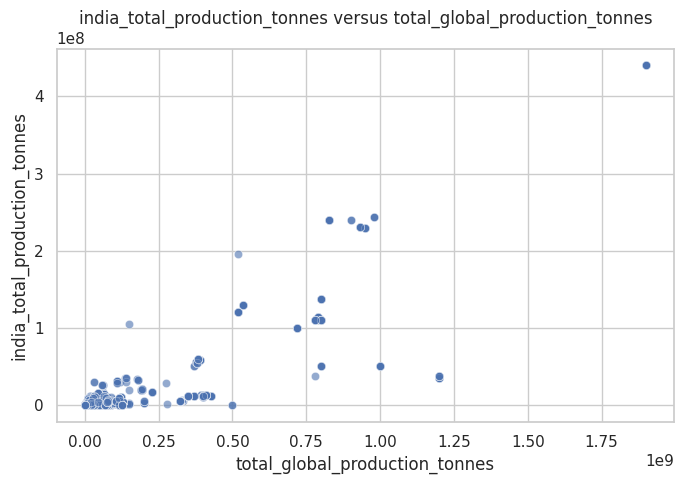

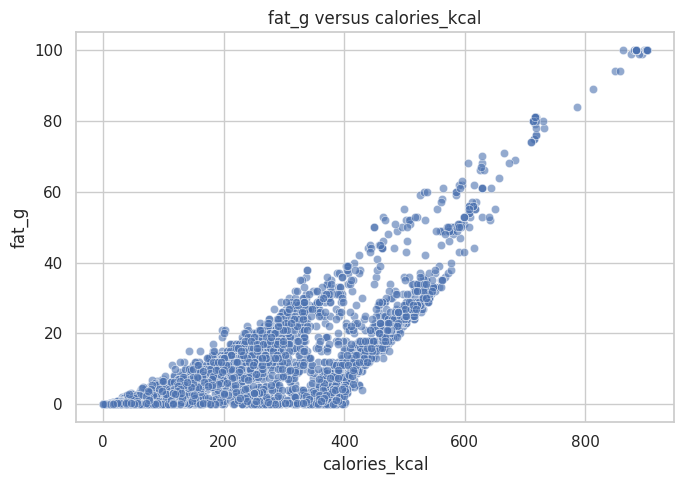

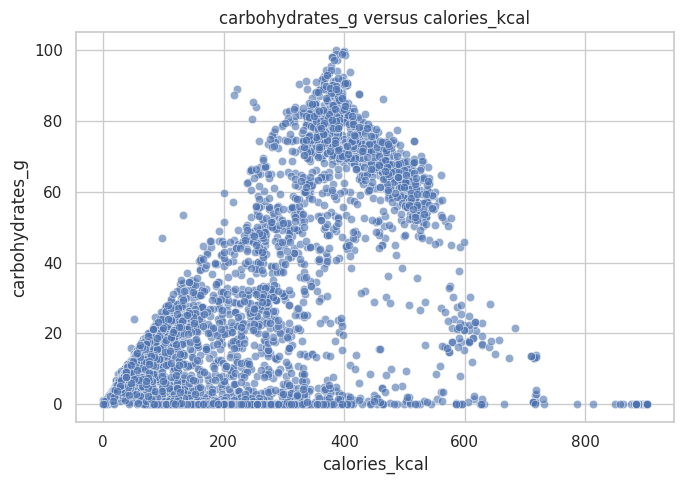

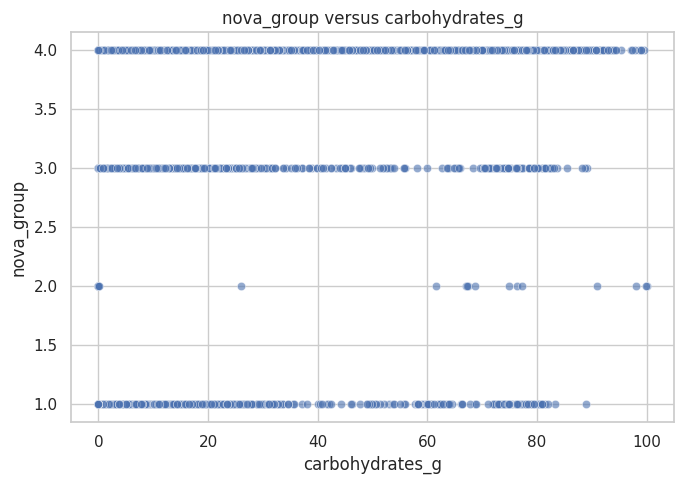

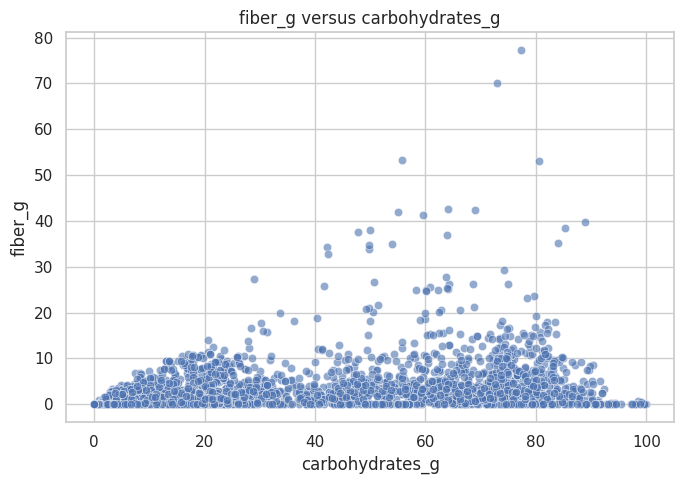

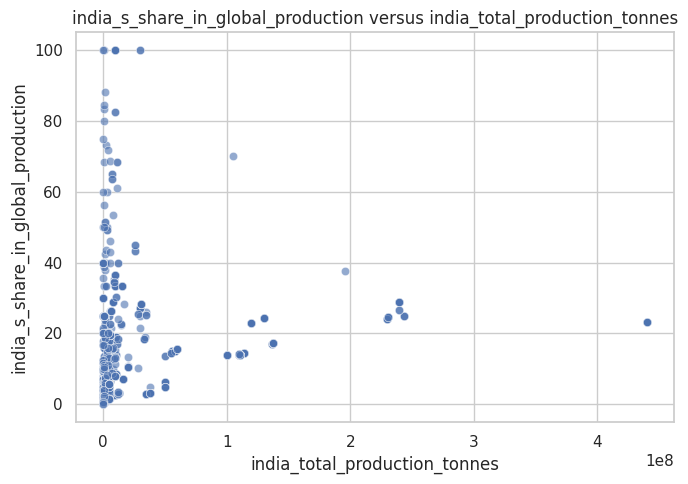

In [48]:
# Scatter plots for selected numeric pairs with highest absolute correlation.
if len(eda_numeric_cols) >= 2:
    pair_list = list(top_pairs.index[:6]) if "top_pairs" in globals() else []
    for x_col, y_col in pair_list:
        plot_data = df_clean[[x_col, y_col]].dropna()
        if len(plot_data) > 5000:
            plot_data = plot_data.sample(5000, random_state=RANDOM_STATE)
        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=plot_data, x=x_col, y=y_col, alpha=0.6)
        plt.title(f"{y_col} versus {x_col}")
        plt.tight_layout()
        plt.show()

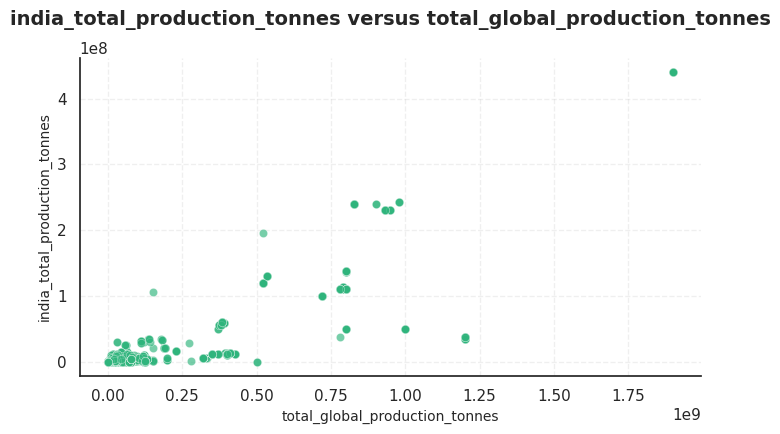

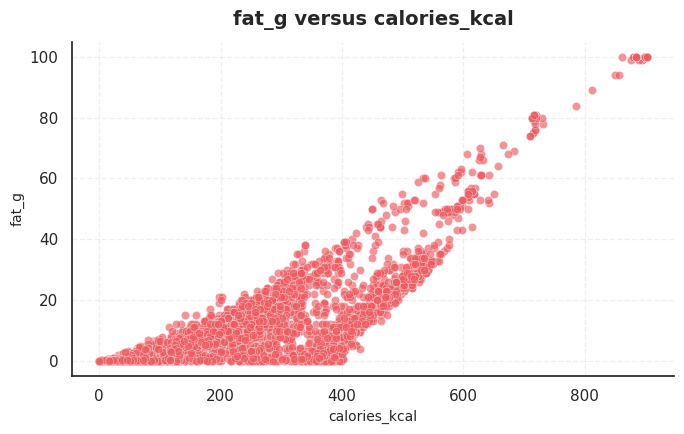

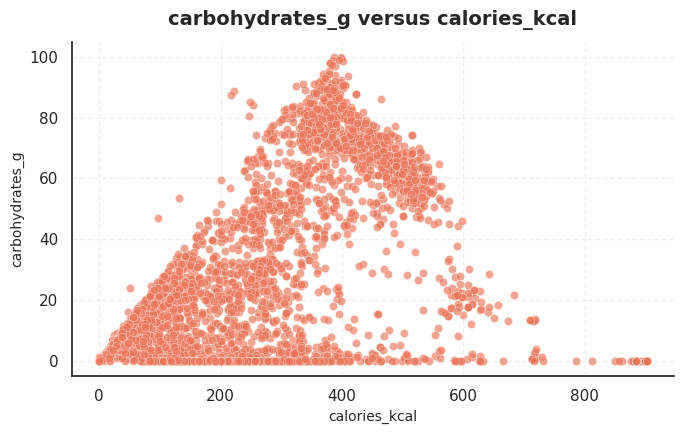

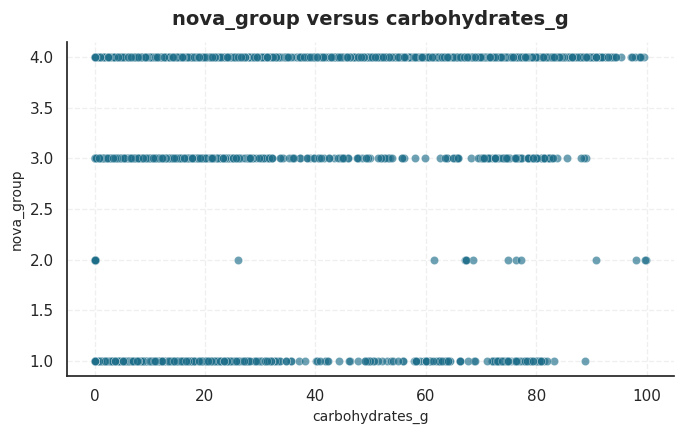

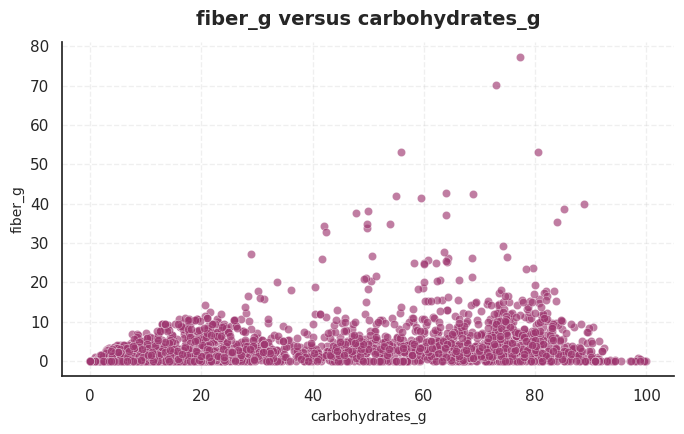

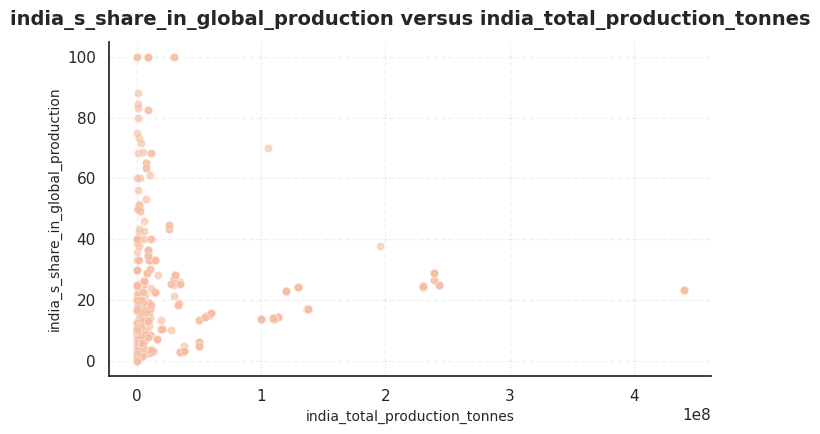

In [76]:
# Scatter plots for selected numeric pairs with highest absolute correlation.
if len(eda_numeric_cols) >= 2:
    pair_list = list(top_pairs.index[:6]) if "top_pairs" in globals() else []

    color_palettes = [
        "viridis", "magma", "plasma",
        "crest", "flare", "coolwarm"
    ]

    for i, (x_col, y_col) in enumerate(pair_list):
        plot_data = df_clean[[x_col, y_col]].dropna()

        if len(plot_data) > 5000:
            plot_data = plot_data.sample(5000, random_state=RANDOM_STATE)

        plt.figure(figsize=(7, 4.5))

        sns.scatterplot(
            data=plot_data,
            x=x_col,
            y=y_col,
            alpha=0.65,
            s=35,
            color=sns.color_palette(color_palettes[i % len(color_palettes)], as_cmap=True)(0.65),
            edgecolor="white",
            linewidth=0.3
        )

        plt.title(
            f"{y_col} versus {x_col}",
            fontsize=14,
            fontweight="bold",
            pad=12
        )

        plt.xlabel(x_col, fontsize=10)
        plt.ylabel(y_col, fontsize=10)

        plt.grid(linestyle="--", alpha=0.3)
        plt.gca().spines["top"].set_visible(False)
        plt.gca().spines["right"].set_visible(False)

        plt.tight_layout()
        plt.show()

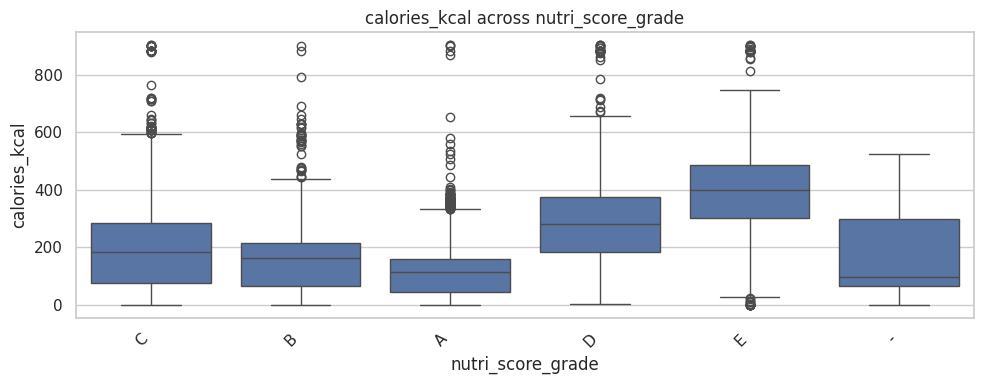

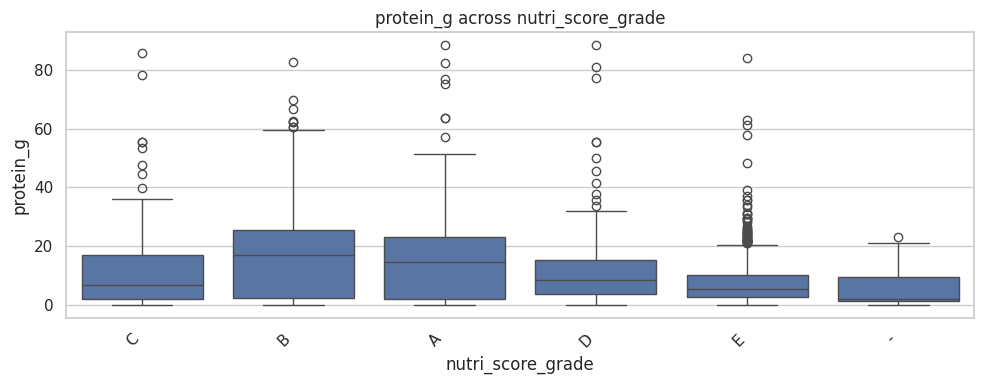

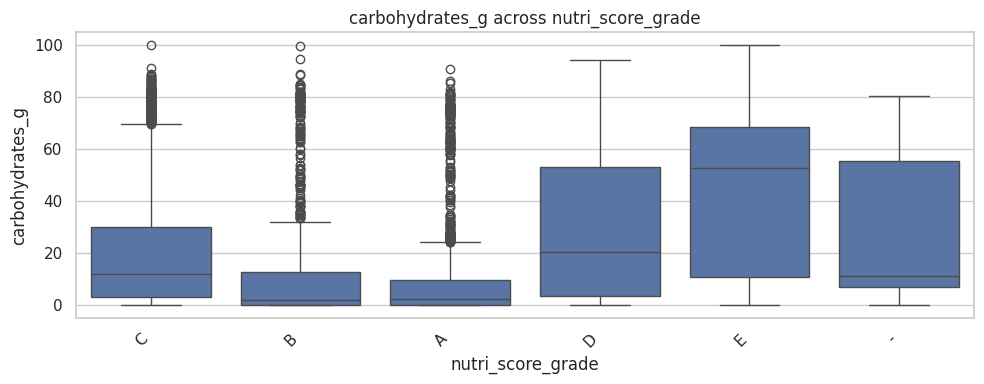

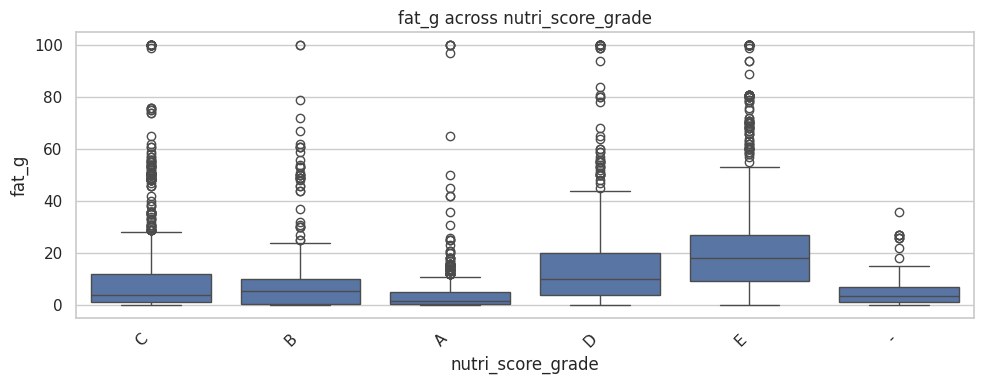

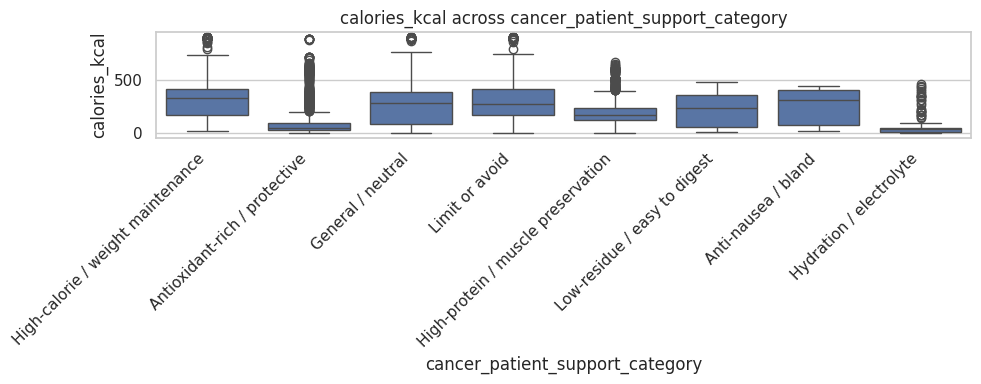

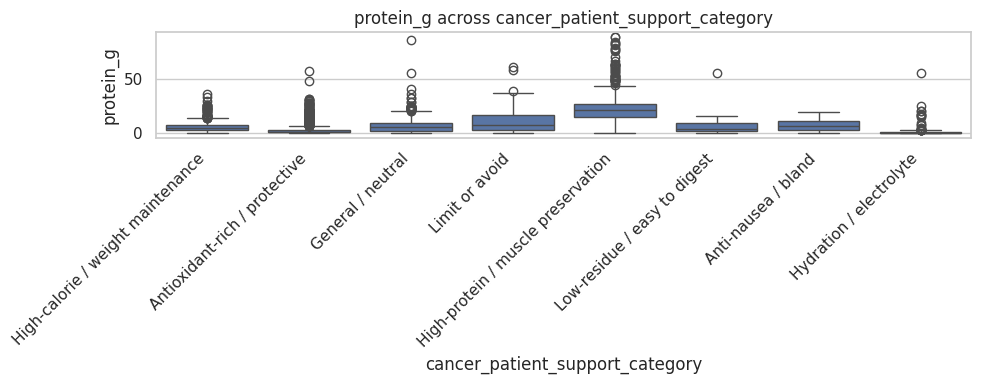

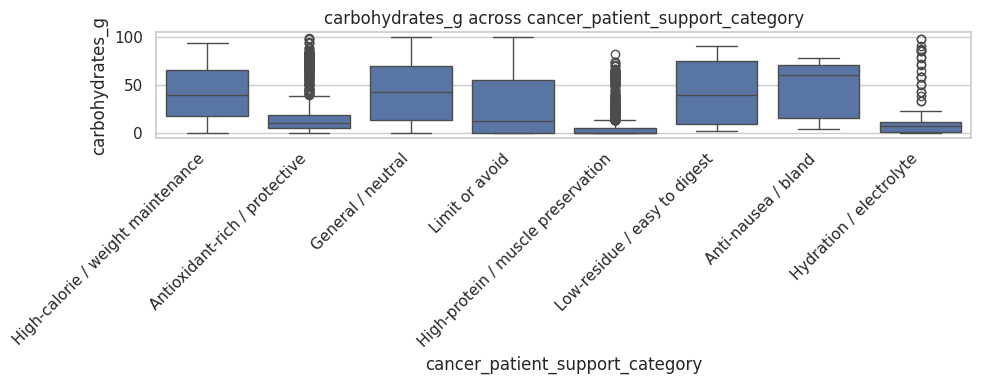

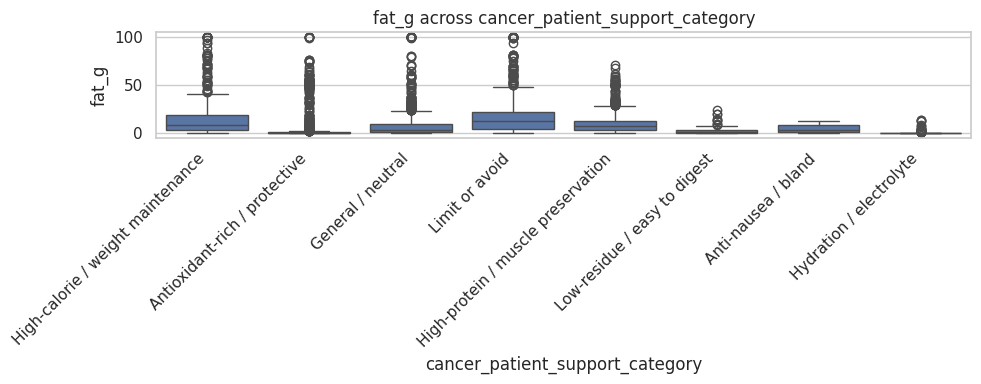

In [49]:
# Group-wise comparisons: numerical variables across low-cardinality categories.
for cat_col in eda_cat_cols:
    if df_clean[cat_col].nunique(dropna=True) < 2 or df_clean[cat_col].nunique(dropna=True) > 12:
        continue
    for num_col in eda_numeric_cols[:4]:
        plot_data = df_clean[[cat_col, num_col]].dropna()
        if plot_data.empty:
            continue
        plt.figure(figsize=(10, 4))
        sns.boxplot(data=plot_data, x=cat_col, y=num_col)
        plt.title(f"{num_col} across {cat_col}")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

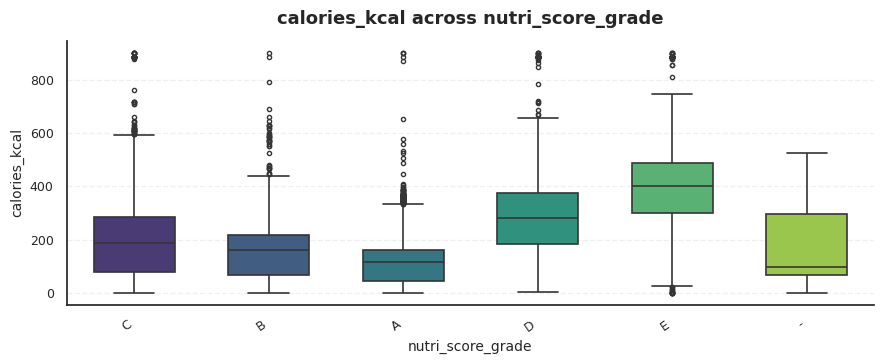

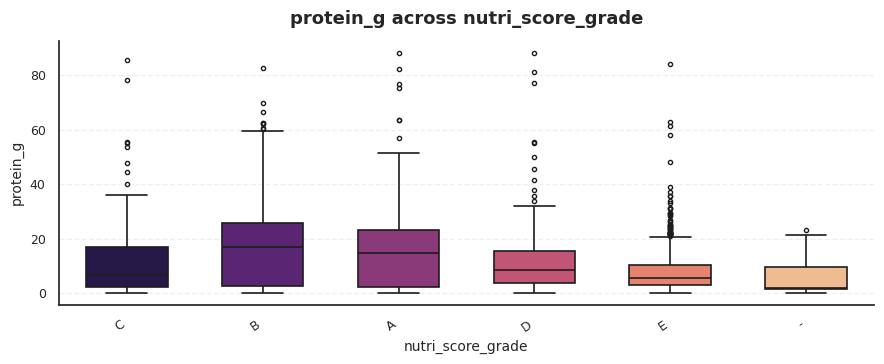

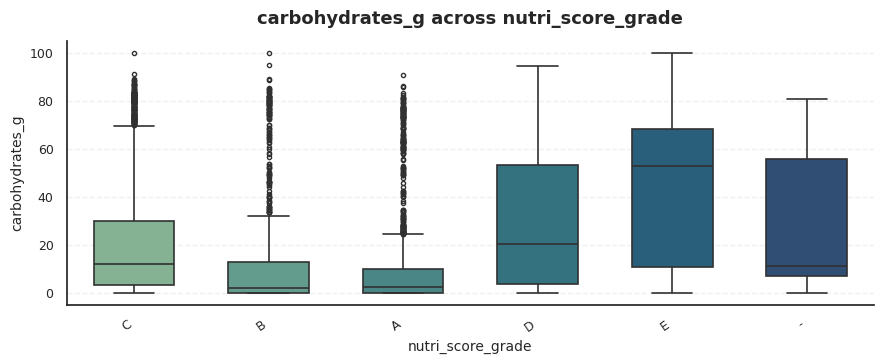

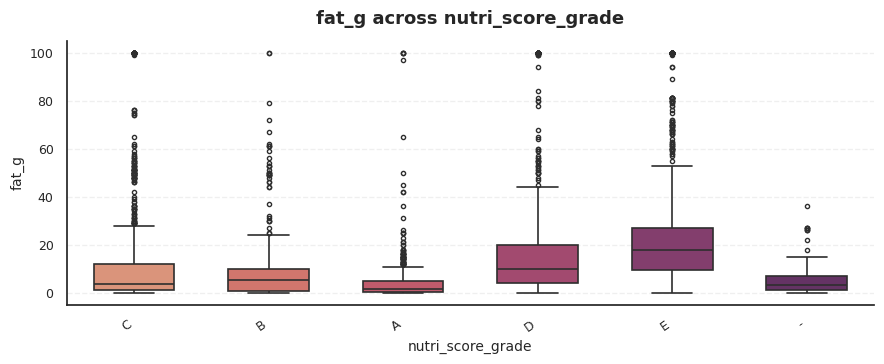

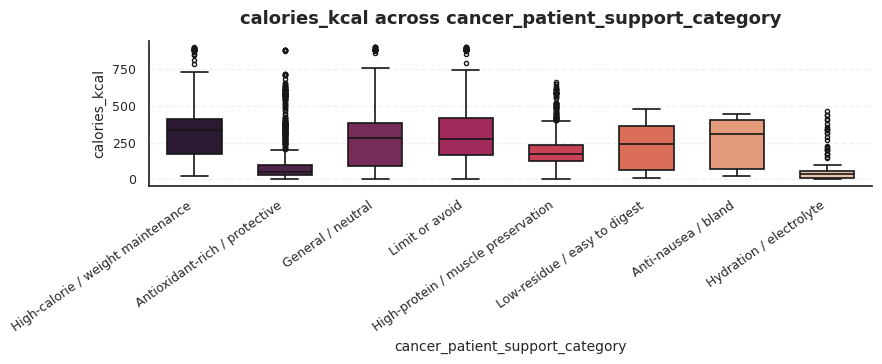

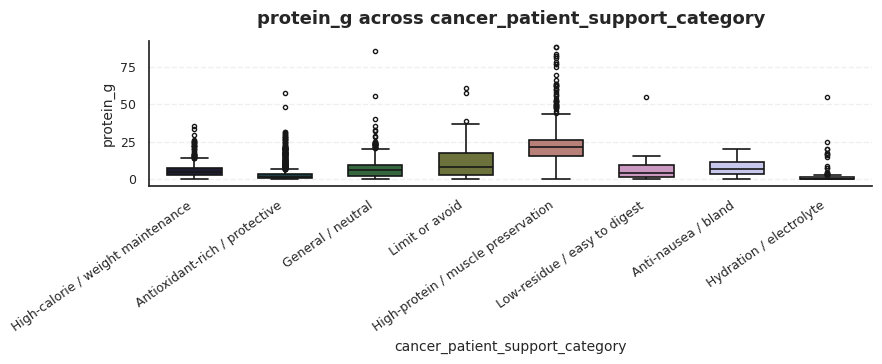

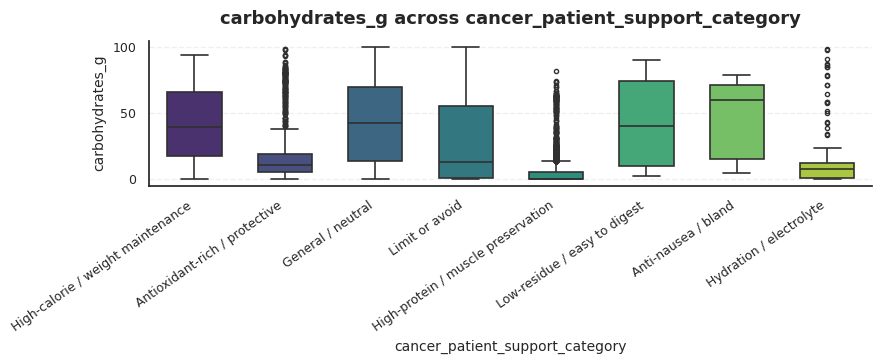

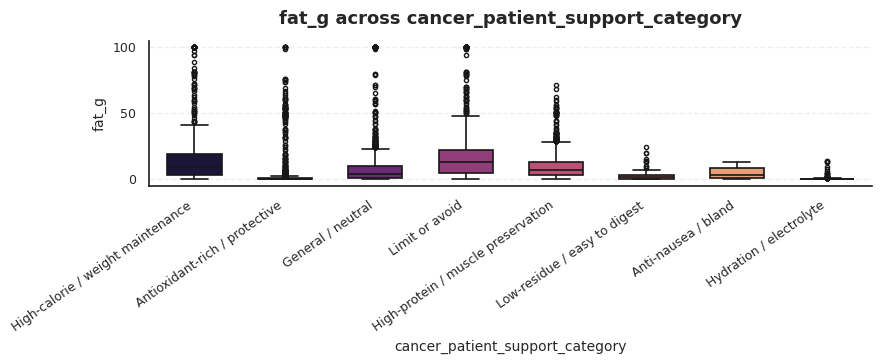

In [75]:
# Group-wise comparisons: numerical variables across low-cardinality categories.

color_palettes = ["viridis", "magma", "crest", "flare", "rocket", "cubehelix"]

plot_index = 0

for cat_col in eda_cat_cols:
    if df_clean[cat_col].nunique(dropna=True) < 2 or df_clean[cat_col].nunique(dropna=True) > 12:
        continue

    for num_col in eda_numeric_cols[:4]:
        plot_data = df_clean[[cat_col, num_col]].dropna()

        if plot_data.empty:
            continue

        plt.figure(figsize=(9, 3.8))

        sns.boxplot(
            data=plot_data,
            x=cat_col,
            y=num_col,
            palette=sns.color_palette(
                color_palettes[plot_index % len(color_palettes)],
                n_colors=plot_data[cat_col].nunique()
            ),
            width=0.6,
            linewidth=1.2,
            fliersize=3
        )

        plt.title(
            f"{num_col} across {cat_col}",
            fontsize=13,
            fontweight="bold",
            pad=12
        )

        plt.xlabel(cat_col, fontsize=10)
        plt.ylabel(num_col, fontsize=10)
        plt.xticks(rotation=35, ha="right", fontsize=9)
        plt.yticks(fontsize=9)

        plt.grid(axis="y", linestyle="--", alpha=0.3)
        plt.gca().spines["top"].set_visible(False)
        plt.gca().spines["right"].set_visible(False)

        plt.tight_layout()
        plt.show()

        plot_index += 1

In [50]:
# Compare verified original/API field pairs when they have been specified.
for original_col, api_col in SOURCE_COLUMN_PAIRS:
    if original_col in df_clean.columns and api_col in df_clean.columns:
        print(f"Comparison: {original_col} vs {api_col}")
        display(df_clean[[original_col, api_col]].head(10))
        if (pd.api.types.is_numeric_dtype(df_clean[original_col]) and
            pd.api.types.is_numeric_dtype(df_clean[api_col])):
            plt.figure(figsize=(6, 5))
            sns.scatterplot(data=df_clean, x=original_col, y=api_col)
            plt.title(f"Original-source vs API-source: {original_col} / {api_col}")
            plt.tight_layout()
            plt.show()

### E3. Multivariate analysis

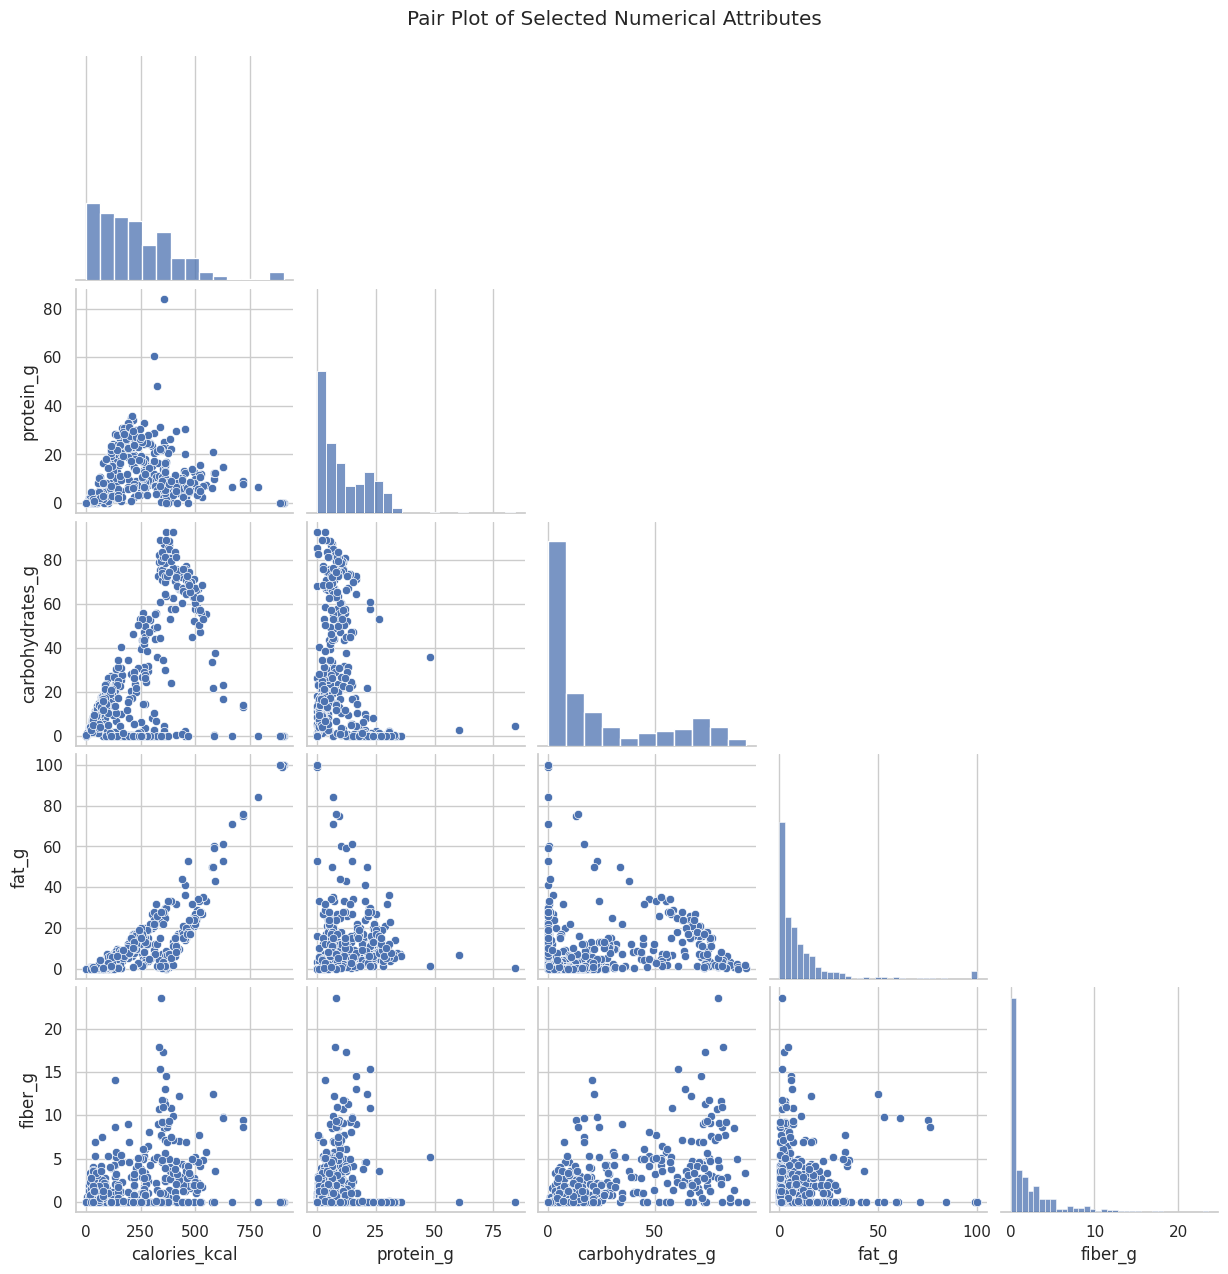

In [51]:
# Pair plot on a small set of numeric variables to avoid an unreadable figure.
if len(eda_numeric_cols) >= 2:
    pair_cols = eda_numeric_cols[:5]
    pair_data = df_clean[pair_cols].dropna()
    if len(pair_data) > 500:
        pair_data = pair_data.sample(500, random_state=RANDOM_STATE)
    if len(pair_data) >= 2:
        sns.pairplot(pair_data, corner=True, diag_kind="hist")
        plt.suptitle("Pair Plot of Selected Numerical Attributes", y=1.02)
        plt.show()

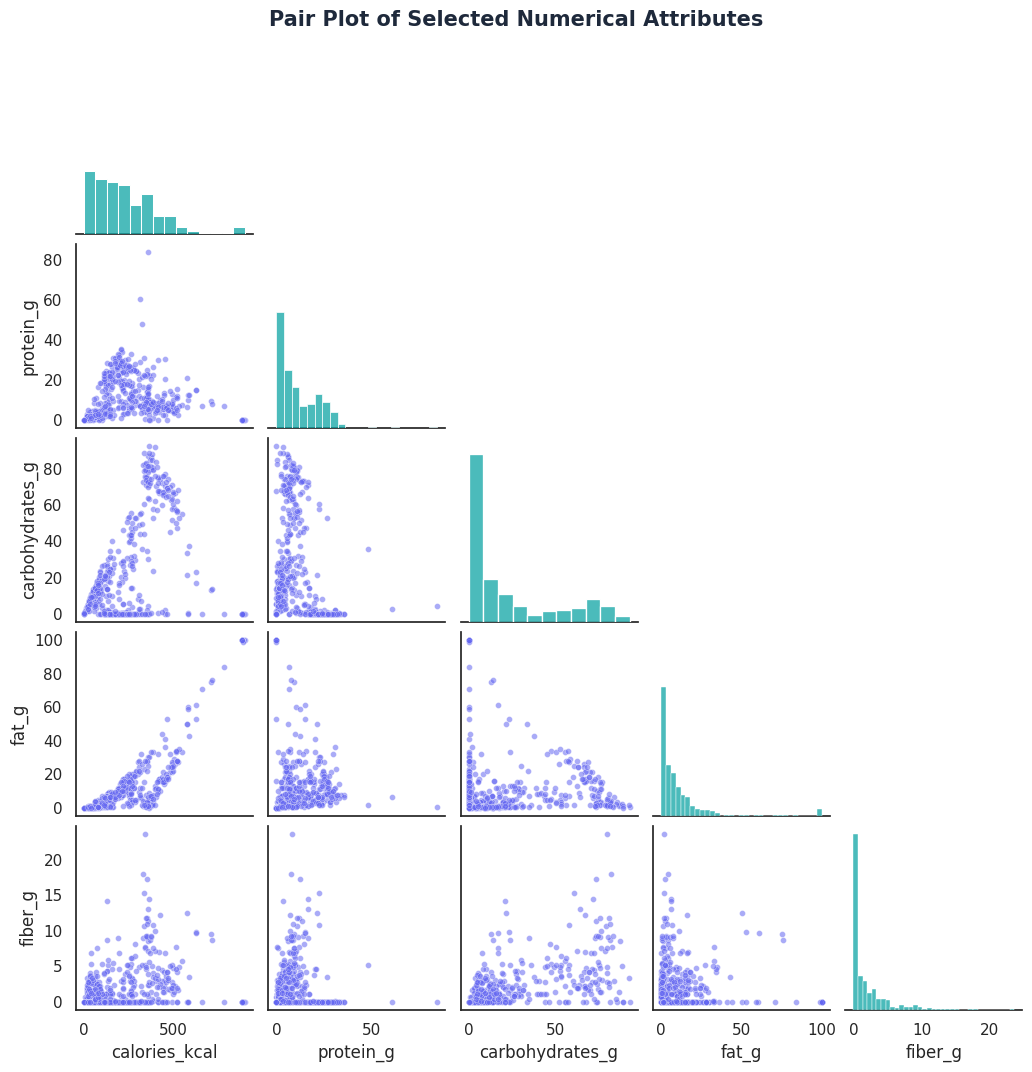

In [74]:
# Pair plot on a small set of numeric variables to avoid an unreadable figure.
if len(eda_numeric_cols) >= 2:
    pair_cols = eda_numeric_cols[:5]
    pair_data = df_clean[pair_cols].dropna()

    if len(pair_data) > 500:
        pair_data = pair_data.sample(500, random_state=RANDOM_STATE)

    if len(pair_data) >= 2:
        sns.set_theme(style="white", context="notebook")

        g = sns.pairplot(
            pair_data,
            corner=True,
            diag_kind="hist",
            height=2.1,
            aspect=1,
            plot_kws={"color": "#6366F1", "alpha": 0.55, "s": 18},
            diag_kws={"color": "#0EA5A4", "edgecolor": "white"}
        )

        g.fig.suptitle(
            "Pair Plot of Selected Numerical Attributes",
            fontsize=15,
            fontweight="bold",
            color="#1E293B",
            y=1.02
        )

        plt.show()

,calories_kcal,protein_g,carbohydrates_g,fat_g,fiber_g
nutri_score_grade,,,,,
-,182.376812,5.152464,26.711739,7.075362,6.744928
A,122.490000,14.044114,9.437768,3.381045,2.247227
B,166.089943,15.162627,11.069016,7.079887,1.787181
C,209.530525,9.817586,22.166427,9.440511,2.205348
D,289.720819,10.441017,29.796341,14.714102,2.042662
E,396.327632,7.124158,43.211336,21.813289,1.550000


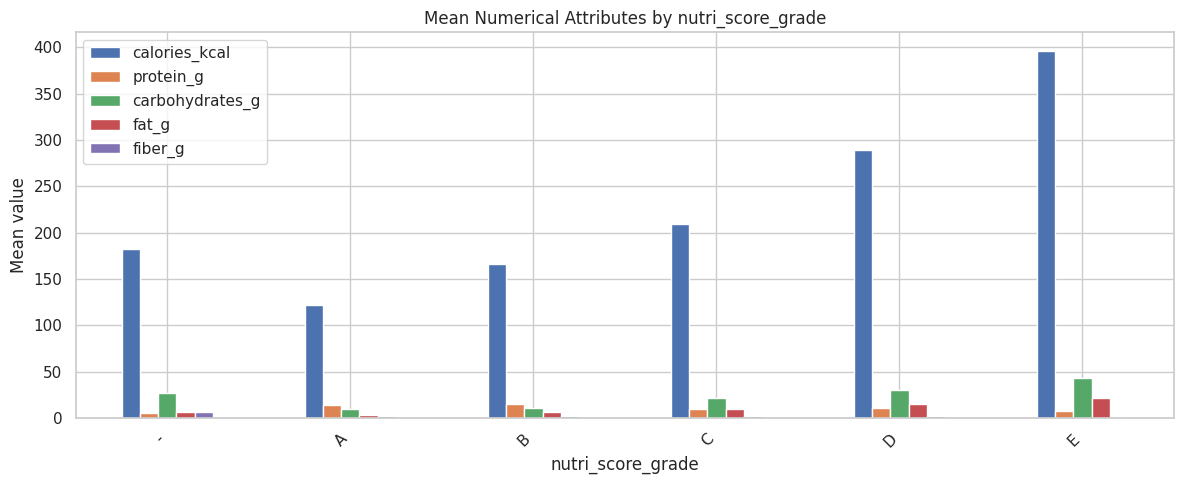

In [52]:
# Multivariable comparison by a selected categorical group, if available.
if eda_cat_cols and eda_numeric_cols:
    group_col = next((c for c in eda_cat_cols
                      if 2 <= df_clean[c].nunique(dropna=True) <= 10), None)
    if group_col:
        chosen_nums = eda_numeric_cols[:5]
        group_means = df_clean.groupby(group_col)[chosen_nums].mean(numeric_only=True)
        display(group_means)
        group_means.plot(kind="bar", figsize=(12, 5))
        plt.title(f"Mean Numerical Attributes by {group_col}")
        plt.ylabel("Mean value")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()
    else:
        print("No suitable low-cardinality categorical variable found for group-wise analysis.")

,calories_kcal,protein_g,carbohydrates_g,fat_g,fiber_g
nutri_score_grade,,,,,
-,182.376812,5.152464,26.711739,7.075362,6.744928
A,122.490000,14.044114,9.437768,3.381045,2.247227
B,166.089943,15.162627,11.069016,7.079887,1.787181
C,209.530525,9.817586,22.166427,9.440511,2.205348
D,289.720819,10.441017,29.796341,14.714102,2.042662
E,396.327632,7.124158,43.211336,21.813289,1.550000


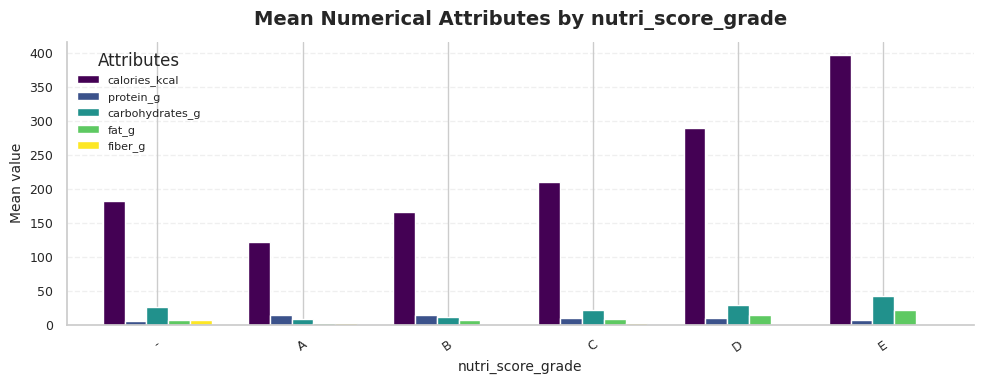

In [73]:
# Multivariable comparison by a selected categorical group, if available.
if eda_cat_cols and eda_numeric_cols:
    group_col = next((c for c in eda_cat_cols
                      if 2 <= df_clean[c].nunique(dropna=True) <= 10), None)

    if group_col:
        chosen_nums = eda_numeric_cols[:5]
        group_means = df_clean.groupby(group_col)[chosen_nums].mean(numeric_only=True)

        display(group_means)

        ax = group_means.plot(
            kind="bar",
            figsize=(10, 4),
            colormap="viridis",
            width=0.75,
            edgecolor="white"
        )

        ax.set_title(f"Mean Numerical Attributes by {group_col}",
                     fontsize=14, fontweight="bold", pad=12)
        ax.set_ylabel("Mean value", fontsize=10)
        ax.set_xlabel(group_col, fontsize=10)
        ax.tick_params(axis="x", labelrotation=35, labelsize=9)
        ax.tick_params(axis="y", labelsize=9)
        ax.legend(title="Attributes", fontsize=8, frameon=False)
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        plt.tight_layout()
        plt.show()

    else:
        print("No suitable low-cardinality categorical variable found for group-wise analysis.")

In [53]:
print("EDA dataset dimensions:", df_clean.shape)
print("Numerical attributes examined:", eda_numeric_cols)
print("Categorical attributes examined:", eda_cat_cols)

EDA dataset dimensions: (8779, 26)
Numerical attributes examined: ['calories_kcal', 'protein_g', 'carbohydrates_g', 'fat_g', 'fiber_g', 'calcium_mg', 'iron_mg', 'potassium_mg', 'sodium_mg', 'vitamin_c_mg', 'nova_group', 'total_global_production_tonnes', 'india_total_production_tonnes', 'india_s_share_in_global_production']
Categorical attributes examined: ['food_name', 'image_url', 'hindi_name', 'marathi_name', 'nutri_score_grade', 'top_producing_country', 'top_3_producing_countries', 'top_producing_indian_state', 'top_3_producing_indian_states', 'cancer_risk_classification', 'cancer_patient_support_category', 'assumption']


### E4. Key EDA findings – complete after reviewing the outputs

Write findings supported by the generated tables and figures. Do not claim a trend unless it is visible in the results.

Suggested reporting structure:
1. State the distribution and spread of important numerical attributes.
2. Identify categorical attributes with the highest frequencies.
3. Report meaningful relationships and their correlation values.
4. Discuss any differences between groups.
5. Explain what the API-added attributes contribute to the fused dataset.
6. State limitations, including missing values, small sample sizes and possible source mismatches.

## PART F – FEATURE ENGINEERING AND MACHINE-LEARNING PREPARATION

### F1. Select prediction targets

**Important:** Classification requires a categorical target; regression requires a numerical target. The following suggestions are automatic candidates only. Inspect the output and set the target variables explicitly. Do not use record IDs, names, identifiers or variables that directly reveal the answer as predictors.

If the dataset does not contain a scientifically meaningful classification or regression target, do not force a model. Discuss the limitation and select a defensible target with your instructor.

In [54]:
# EDIT AFTER REVIEWING THE COLUMN LIST.
CLASSIFICATION_TARGET = None  # Example: "food_category"
REGRESSION_TARGET = None      # Example: "energy_kcal"

# Optional: explicitly exclude identifier, name, leakage or unsuitable columns.
EXTRA_EXCLUDE_COLUMNS = []

# Automatic target suggestions (not automatic scientific approval).
id_pattern = re.compile(r"(^id$|_id$|^id_|identifier|record_no|serial|uuid)", re.I)

classification_candidates = []
for col in df_clean.columns:
    nunique = df_clean[col].nunique(dropna=True)
    if (not id_pattern.search(col) and 2 <= nunique <= 15
            and df_clean[col].dtype == "object"):
        classification_candidates.append((col, nunique))

regression_candidates = []
for col in df_clean.select_dtypes(include=np.number).columns:
    nunique = df_clean[col].nunique(dropna=True)
    if not id_pattern.search(col) and nunique >= 10:
        regression_candidates.append((col, nunique))

print("Classification target candidates (column, unique classes):")
print(classification_candidates)
print("\nRegression target candidates (column, unique values):")
print(regression_candidates)

Classification target candidates (column, unique classes):
[('nutri_score_grade', 6), ('cancer_patient_support_category', 8)]

Regression target candidates (column, unique values):
[('calories_kcal', 671), ('protein_g', 2664), ('carbohydrates_g', 3322), ('fat_g', 185), ('fiber_g', 251), ('calcium_mg', 564), ('iron_mg', 939), ('potassium_mg', 883), ('sodium_mg', 1201), ('vitamin_c_mg', 559), ('total_global_production_tonnes', 371), ('india_total_production_tonnes', 177), ('india_s_share_in_global_production', 402)]


In [55]:
# If no target is manually specified, choose a provisional candidate for exploration only.
if CLASSIFICATION_TARGET is None and classification_candidates:
    CLASSIFICATION_TARGET = classification_candidates[0][0]

if REGRESSION_TARGET is None and regression_candidates:
    REGRESSION_TARGET = regression_candidates[0][0]

print("Provisional classification target:", CLASSIFICATION_TARGET)
print("Provisional regression target:", REGRESSION_TARGET)

print("\nClassification target distribution:")
if CLASSIFICATION_TARGET in df_clean.columns:
    display(df_clean[CLASSIFICATION_TARGET].value_counts(dropna=False).to_frame("Count"))

print("\nRegression target summary:")
if REGRESSION_TARGET in df_clean.columns:
    display(df_clean[REGRESSION_TARGET].describe().to_frame("Summary"))

Provisional classification target: nutri_score_grade
Provisional regression target: calories_kcal

Classification target distribution:


,Count
nutri_score_grade,
A,2200
C,2113
E,1520
D,1465
B,1412
-,69



Regression target summary:


,Summary
count,8779.000000
mean,226.241941
std,169.775850
min,0.000000
25%,91.000000
50%,191.000000
75%,337.000000
max,902.000000


### F2. Prepare modelling features

The helper function below removes the target, identifier-like columns, explicitly excluded columns and columns that are entirely missing. It keeps numeric and categorical predictors and uses scikit-learn pipelines for imputation, encoding and scaling.

Review the selected features carefully. Exclude columns that leak the target or contain duplicate representations of the outcome.

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

def build_feature_matrix(data, target, extra_exclude=None):
    if target is None or target not in data.columns:
        raise ValueError(f"Please set a valid target column. Current target: {target}")

    exclude = set(extra_exclude or [])
    exclude.add(target)

    # Remove ID-like columns and columns with no observed values.
    for c in data.columns:
        if id_pattern.search(str(c)):
            exclude.add(c)
        if data[c].isna().all():
            exclude.add(c)

    feature_cols = [c for c in data.columns if c not in exclude]
    X = data[feature_cols].copy()
    y = data[target].copy()

    # Drop rows with missing target only; predictor missingness is imputed in pipeline.
    valid_target = y.notna()
    X = X.loc[valid_target]
    y = y.loc[valid_target]

    # Remove constant predictors.
    constant_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
    X = X.drop(columns=constant_cols)

    if X.shape[1] == 0:
        raise ValueError("No usable predictor columns remain. Review exclusions.")

    return X, y, X.columns.tolist(), constant_cols

def make_preprocessor(X, scale_numeric=True):
    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = [c for c in X.columns if c not in numeric_features]

    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_transformer = Pipeline(steps=numeric_steps)
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers = []
    if numeric_features:
        transformers.append(("numeric", numeric_transformer, numeric_features))
    if categorical_features:
        transformers.append(("categorical", categorical_transformer, categorical_features))

    return ColumnTransformer(transformers=transformers, remainder="drop", sparse_threshold=0)

## PART G – IMPLEMENTATION OF EIGHT MACHINE-LEARNING ALGORITHMS

### G1. Classification dataset preparation

The five classification algorithms are Naive Bayes, SVM, Decision Tree, Random Forest and Logistic Regression. The target must represent a meaningful category. The notebook uses stratified splitting when possible and reports class balance.

In [57]:
classification_results = []
classification_fitted_models = {}
classification_details = {}

if CLASSIFICATION_TARGET is not None and CLASSIFICATION_TARGET in df_clean.columns:
    X_cls, y_cls, cls_features, cls_constant_cols = build_feature_matrix(
        df_clean, CLASSIFICATION_TARGET, EXTRA_EXCLUDE_COLUMNS
    )

    # Keep classes with enough observations for a stratified train/test split.
    class_counts = y_cls.value_counts()
    valid_classes = class_counts[class_counts >= 2].index
    keep = y_cls.isin(valid_classes)
    X_cls, y_cls = X_cls.loc[keep], y_cls.loc[keep]

    if y_cls.nunique() < 2 or len(y_cls) < 10:
        print("Insufficient valid classes/records for classification.")
        X_cls = None
    else:
        X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
            X_cls, y_cls, test_size=0.20, random_state=RANDOM_STATE,
            stratify=y_cls
        )
        print("Classification target:", CLASSIFICATION_TARGET)
        print("Features:", cls_features)
        print("Training records:", len(X_train_cls))
        print("Testing records:", len(X_test_cls))
        display(y_cls.value_counts().rename("Class count").to_frame())
else:
    print("No valid classification target selected. Set CLASSIFICATION_TARGET in Part F.")
    X_cls = None

Classification target: nutri_score_grade
Features: ['food_name', 'image_url', 'hindi_name', 'marathi_name', 'calories_kcal', 'protein_g', 'carbohydrates_g', 'fat_g', 'fiber_g', 'calcium_mg', 'iron_mg', 'potassium_mg', 'sodium_mg', 'vitamin_c_mg', 'nova_group', 'top_producing_country', 'top_3_producing_countries', 'total_global_production_tonnes', 'top_producing_indian_state', 'top_3_producing_indian_states', 'india_total_production_tonnes', 'india_s_share_in_global_production', 'cancer_risk_classification', 'cancer_patient_support_category', 'assumption']
Training records: 7023
Testing records: 1756


,Class count
nutri_score_grade,
A,2200
C,2113
E,1520
D,1465
B,1412
-,69


In [58]:
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

if X_cls is not None:
    # GaussianNB requires dense transformed data.
    classification_models = {
        "Naive Bayes": GaussianNB(),
        "SVM": SVC(),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced"
        ),
        "Logistic Regression": LogisticRegression(
            max_iter=3000, class_weight="balanced"
        )
    }

    for model_name, estimator in classification_models.items():
        try:
            pipeline = Pipeline(steps=[
                ("preprocessor", make_preprocessor(X_train_cls, scale_numeric=True)),
                ("model", estimator)
            ])
            pipeline.fit(X_train_cls, y_train_cls)
            predictions = pipeline.predict(X_test_cls)

            average_method = "binary" if y_test_cls.nunique() == 2 else "weighted"
            result = {
                "Model": model_name,
                "Accuracy": accuracy_score(y_test_cls, predictions),
                "Precision": precision_score(y_test_cls, predictions, average=average_method, zero_division=0),
                "Recall": recall_score(y_test_cls, predictions, average=average_method, zero_division=0),
                "F1-score": f1_score(y_test_cls, predictions, average=average_method, zero_division=0)
            }
            classification_results.append(result)
            classification_fitted_models[model_name] = pipeline
            classification_details[model_name] = predictions

            print(f"\n{model_name}")
            print(classification_report(y_test_cls, predictions, zero_division=0))
        except Exception as e:
            print(f"{model_name} could not be fitted: {e}")

    display(pd.DataFrame(classification_results).sort_values("F1-score", ascending=False))
else:
    print("Classification models skipped until a valid target is selected.")


Naive Bayes
              precision    recall  f1-score   support

           -       0.14      0.86      0.24        14
           A       0.78      0.33      0.47       440
           B       0.24      0.77      0.36       282
           C       0.51      0.17      0.26       423
           D       0.41      0.43      0.42       293
           E       0.66      0.26      0.37       304

    accuracy                           0.37      1756
   macro avg       0.46      0.47      0.35      1756
weighted avg       0.54      0.37      0.37      1756


SVM
              precision    recall  f1-score   support

           -       0.00      0.00      0.00        14
           A       0.80      0.88      0.84       440
           B       0.59      0.43      0.50       282
           C       0.60      0.74      0.66       423
           D       0.63      0.50      0.56       293
           E       0.79      0.79      0.79       304

    accuracy                           0.69      1756
   ma

,Model,Accuracy,Precision,Recall,F1-score
1,SVM,0.688497,0.679092,0.688497,0.678132
3,Random Forest,0.690774,0.687215,0.690774,0.676645
2,Decision Tree,0.669704,0.667386,0.669704,0.667897
4,Logistic Regression,0.639522,0.627056,0.639522,0.630234
0,Naive Bayes,0.373007,0.541521,0.373007,0.374975


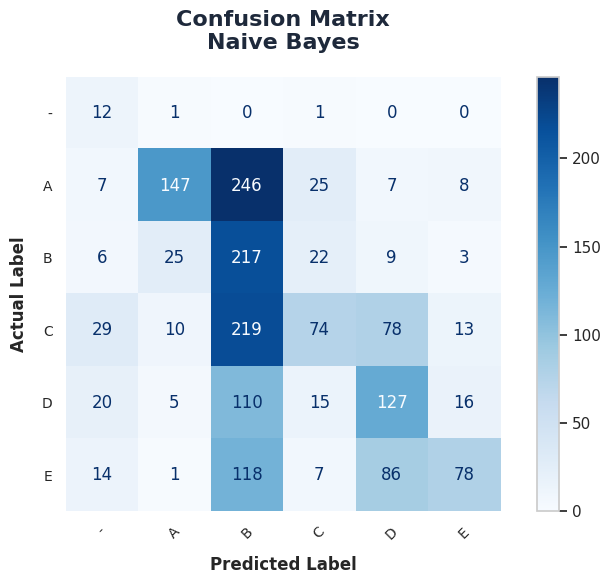

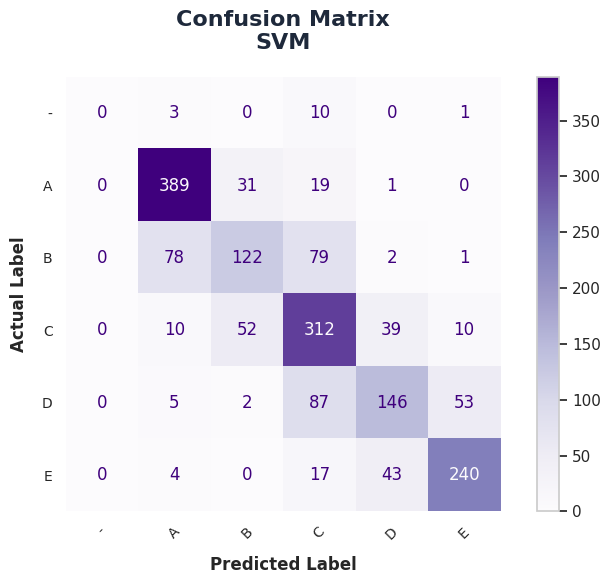

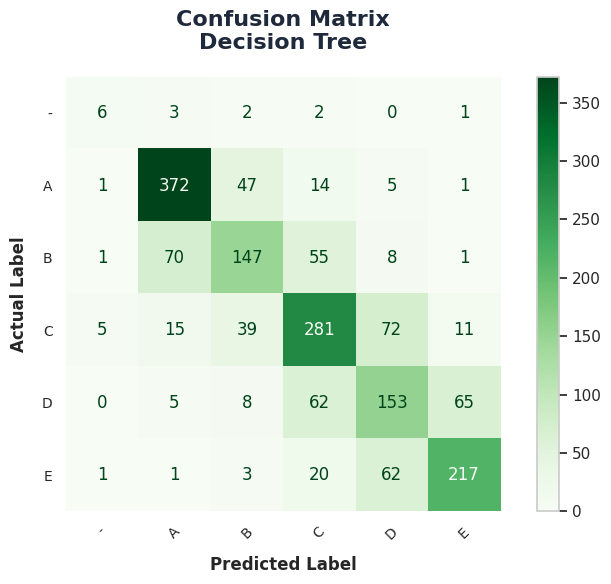

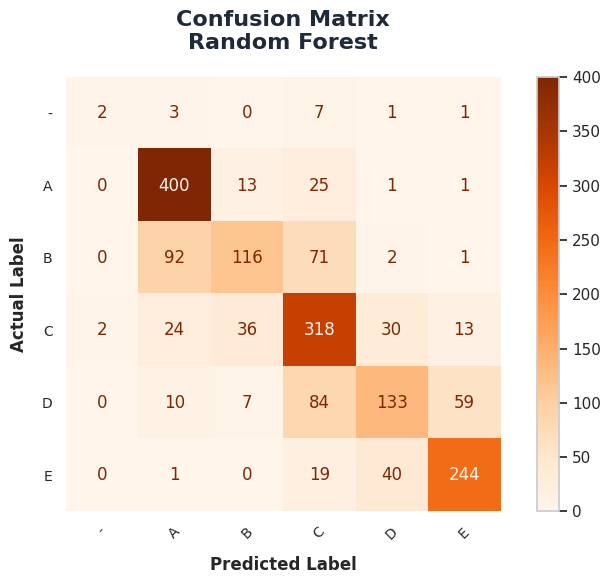

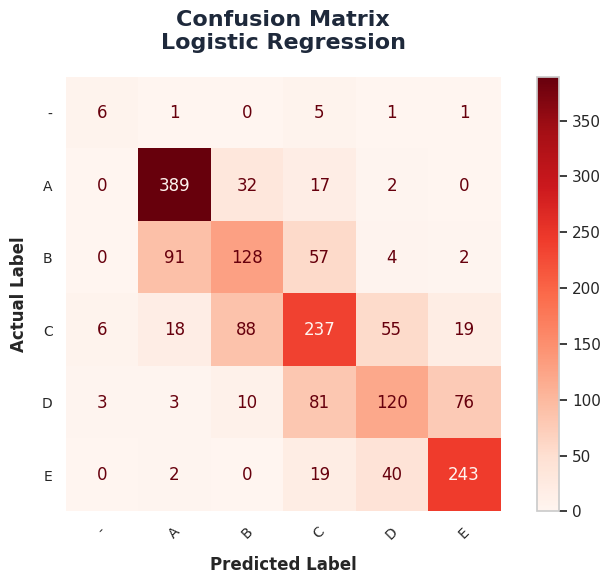

In [72]:
# Confusion matrix for each successfully fitted classification model.

# Different colour palettes for different models
color_palettes = [
    "Blues",
    "Purples",
    "Greens",
    "Oranges",
    "Reds",
    "YlGnBu",
    "PuRd",
    "BuPu",
    "YlOrBr",
    "GnBu"
]

for i, (model_name, predictions) in enumerate(classification_details.items()):

    labels = sorted(pd.Series(y_test_cls).astype(str).unique())

    cm = confusion_matrix(
        y_test_cls.astype(str),
        pd.Series(predictions).astype(str),
        labels=labels
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    disp.plot(
        ax=ax,
        cmap=color_palettes[i % len(color_palettes)],
        xticks_rotation=45,
        colorbar=True,
        values_format="d"
    )

    ax.set_title(
        f"Confusion Matrix\n{model_name}",
        fontsize=16,
        fontweight="bold",
        color="#1E293B",
        pad=20
    )

    ax.set_xlabel(
        "Predicted Label",
        fontsize=12,
        fontweight="bold",
        labelpad=10
    )

    ax.set_ylabel(
        "Actual Label",
        fontsize=12,
        fontweight="bold",
        labelpad=10
    )

    ax.tick_params(axis="both", labelsize=10)
    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()
    plt.show()

,Model,Accuracy,Precision,Recall,F1-score
1,SVM,0.688497,0.679092,0.688497,0.678132
3,Random Forest,0.690774,0.687215,0.690774,0.676645
2,Decision Tree,0.669704,0.667386,0.669704,0.667897
4,Logistic Regression,0.639522,0.627056,0.639522,0.630234
0,Naive Bayes,0.373007,0.541521,0.373007,0.374975


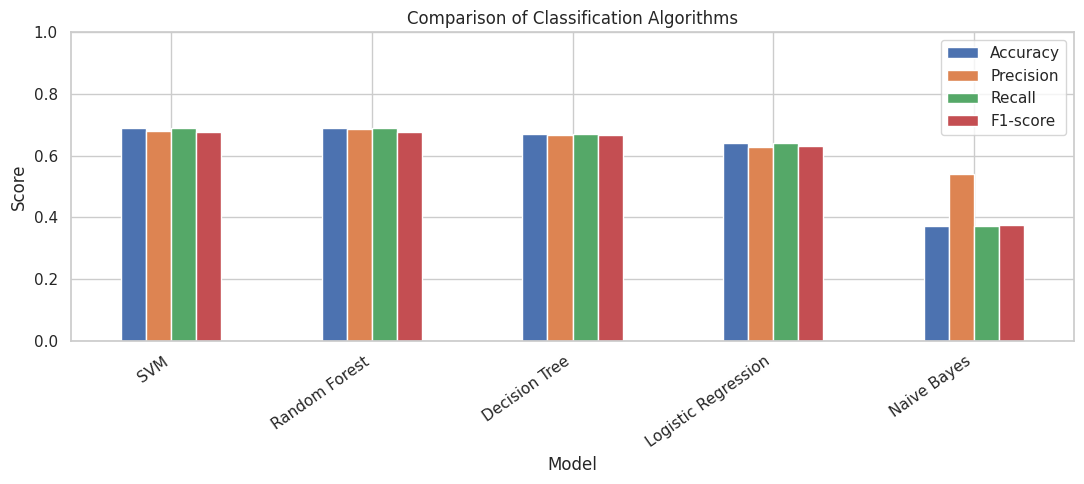

In [60]:
# Classification model comparison chart.
if classification_results:
    cls_results_df = pd.DataFrame(classification_results).sort_values("F1-score", ascending=False)
    display(cls_results_df)
    cls_results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
        kind="bar", figsize=(11, 5)
    )
    plt.title("Comparison of Classification Algorithms")
    plt.ylabel("Score")
    plt.ylim(0, 1)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

### G2. Regression dataset preparation

The regression algorithms are:
6. Simple Linear Regression (regression analysis using one predictor).
7. Multiple Linear Regression (multiple predictors).
8. Polynomial Regression (nonlinear polynomial transformation of predictors).

The numerical target must be continuous or meaningfully quantitative. The notebook uses the same train/test split for fair comparison. Categorical predictors are one-hot encoded; numerical predictors are imputed and scaled within the pipeline.

In [61]:
regression_results = []
regression_fitted_models = {}
regression_predictions = {}

if REGRESSION_TARGET is not None and REGRESSION_TARGET in df_clean.columns:
    X_reg, y_reg, reg_features, reg_constant_cols = build_feature_matrix(
        df_clean, REGRESSION_TARGET, EXTRA_EXCLUDE_COLUMNS
    )
    y_reg = pd.to_numeric(y_reg, errors="coerce")
    valid_y = y_reg.notna()
    X_reg, y_reg = X_reg.loc[valid_y], y_reg.loc[valid_y]

    if len(y_reg) < 15 or y_reg.nunique() < 5:
        print("Insufficient observations or target variation for regression.")
        X_reg = None
    else:
        X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
            X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
        )
        print("Regression target:", REGRESSION_TARGET)
        print("Predictor columns:", reg_features)
        print("Training records:", len(X_train_reg))
        print("Testing records:", len(X_test_reg))
        display(y_reg.describe().to_frame("Target summary"))
else:
    print("No valid regression target selected. Set REGRESSION_TARGET in Part F.")
    X_reg = None

Regression target: calories_kcal
Predictor columns: ['food_name', 'image_url', 'hindi_name', 'marathi_name', 'protein_g', 'carbohydrates_g', 'fat_g', 'fiber_g', 'calcium_mg', 'iron_mg', 'potassium_mg', 'sodium_mg', 'vitamin_c_mg', 'nutri_score_grade', 'nova_group', 'top_producing_country', 'top_3_producing_countries', 'total_global_production_tonnes', 'top_producing_indian_state', 'top_3_producing_indian_states', 'india_total_production_tonnes', 'india_s_share_in_global_production', 'cancer_risk_classification', 'cancer_patient_support_category', 'assumption']
Training records: 7023
Testing records: 1756


,Target summary
count,8779.000000
mean,226.241941
std,169.775850
min,0.000000
25%,91.000000
50%,191.000000
75%,337.000000
max,902.000000


In [62]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

def record_regression_model(name, pipeline):
    pipeline.fit(X_train_reg, y_train_reg)
    pred = pipeline.predict(X_test_reg)
    result = {"Model": name, **regression_metrics(y_test_reg, pred)}
    regression_results.append(result)
    regression_fitted_models[name] = pipeline
    regression_predictions[name] = pred
    print(name, result)

if X_reg is not None:
    # 6. Simple Linear Regression: use the strongest single numeric predictor
    # correlated with the target, if one exists.
    numeric_predictors = X_train_reg.select_dtypes(include=np.number).columns.tolist()
    if numeric_predictors:
        correlations = X_train_reg[numeric_predictors].corrwith(y_train_reg).abs().dropna()
        if not correlations.empty:
            simple_feature = correlations.idxmax()
            simple_X_train = X_train_reg[[simple_feature]]
            simple_X_test = X_test_reg[[simple_feature]]
            simple_pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("model", LinearRegression())
            ])
            simple_pipeline.fit(simple_X_train, y_train_reg)
            simple_pred = simple_pipeline.predict(simple_X_test)
            regression_results.append({
                "Model": f"Simple Linear Regression ({simple_feature})",
                **regression_metrics(y_test_reg, simple_pred)
            })
            regression_fitted_models["Simple Linear Regression"] = simple_pipeline
            regression_predictions["Simple Linear Regression"] = simple_pred
            print("Simple Linear Regression predictor:", simple_feature)
        else:
            print("No usable numeric predictor for Simple Linear Regression.")
    else:
        print("Simple Linear Regression skipped: no numerical predictor available.")

    # 7. Multiple Linear Regression: use all eligible predictors.
    multiple_pipeline = Pipeline([
        ("preprocessor", make_preprocessor(X_train_reg, scale_numeric=True)),
        ("model", LinearRegression())
    ])
    record_regression_model("Multiple Linear Regression", multiple_pipeline)

    # 8. Polynomial Regression: polynomial expansion on a manageable numeric feature set.
    # Categorical variables are excluded from this polynomial demonstration.
    poly_features = numeric_predictors[:5]
    if poly_features:
        poly_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
            ("model", LinearRegression())
        ])
        poly_pipeline.fit(X_train_reg[poly_features], y_train_reg)
        poly_pred = poly_pipeline.predict(X_test_reg[poly_features])
        regression_results.append({
            "Model": f"Polynomial Regression (degree 2; {len(poly_features)} numeric features)",
            **regression_metrics(y_test_reg, poly_pred)
        })
        regression_fitted_models["Polynomial Regression"] = poly_pipeline
        regression_predictions["Polynomial Regression"] = poly_pred
    else:
        print("Polynomial Regression skipped: no numeric predictors available.")

    display(pd.DataFrame(regression_results).sort_values("RMSE"))
else:
    print("Regression models skipped until a valid numerical target is selected.")

Simple Linear Regression predictor: fat_g
Multiple Linear Regression {'Model': 'Multiple Linear Regression', 'MAE': 5.64639418377573, 'MSE': 145.28197555240237, 'RMSE': np.float64(12.053297289638316), 'R2': 0.9953060068664261}


,Model,MAE,MSE,RMSE,R2
1,Multiple Linear Regression,5.646394,145.281976,12.053297,0.995306
2,Polynomial Regression (degree 2; 5 numeric fea...,6.242168,197.311065,14.046746,0.993625
0,Simple Linear Regression (fat_g),82.917791,10648.245636,103.190337,0.655960


,Model,MAE,MSE,RMSE,R2
1,Multiple Linear Regression,5.646394,145.281976,12.053297,0.995306
2,Polynomial Regression (degree 2; 5 numeric fea...,6.242168,197.311065,14.046746,0.993625
0,Simple Linear Regression (fat_g),82.917791,10648.245636,103.190337,0.655960


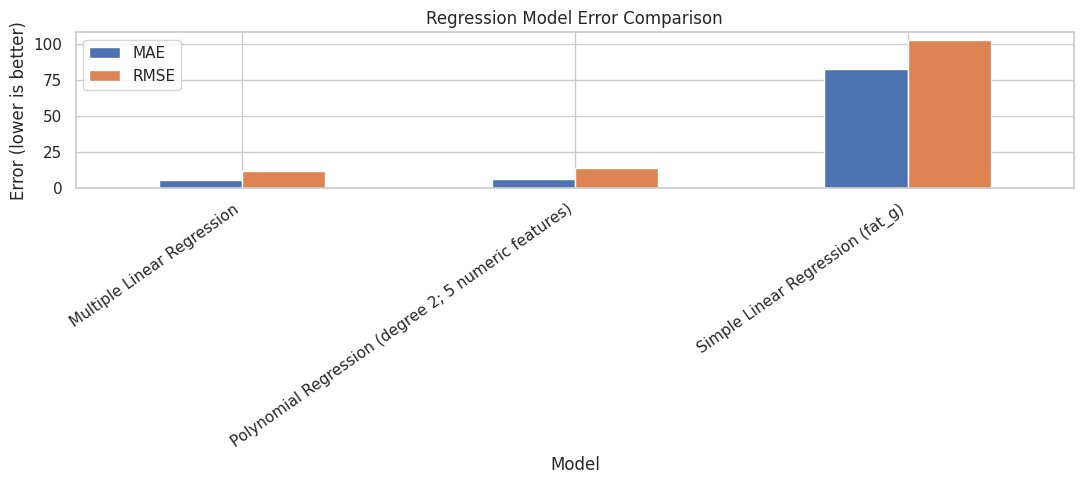

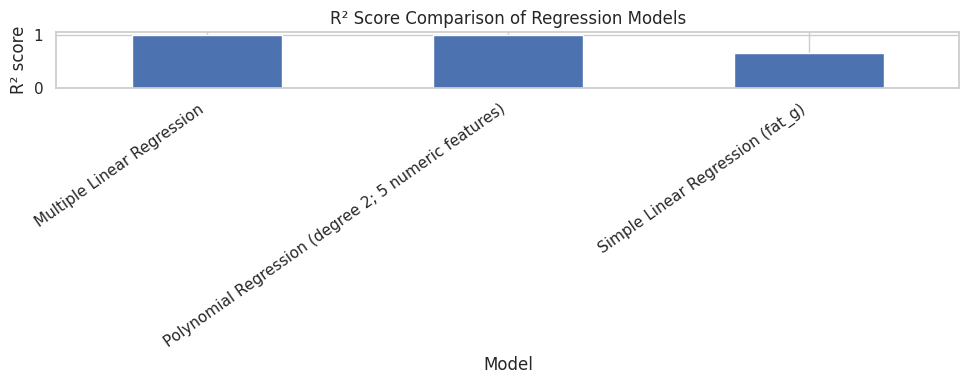

In [63]:
# Regression model comparison.
if regression_results:
    reg_results_df = pd.DataFrame(regression_results).sort_values("RMSE")
    display(reg_results_df)

    reg_results_df.set_index("Model")[["MAE", "RMSE"]].plot(
        kind="bar", figsize=(11, 5)
    )
    plt.title("Regression Model Error Comparison")
    plt.ylabel("Error (lower is better)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

    reg_results_df.set_index("Model")["R2"].plot(kind="bar", figsize=(10, 4))
    plt.title("R² Score Comparison of Regression Models")
    plt.ylabel("R² score")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

## PART H – MODEL EVALUATION AND COMPARISON

### H1. Classification evaluation

The confusion matrix shows the number of correct and incorrect predictions by class. Accuracy is the proportion of correct predictions. Precision, recall and F1-score provide additional information, particularly when class counts are imbalanced.

A high accuracy score alone is not sufficient to select a model. Consider class balance, per-class recall, the confusion matrix and the consequences of false positives and false negatives.

In [64]:
if classification_results:
    best_cls_row = pd.DataFrame(classification_results).sort_values(
        ["F1-score", "Accuracy"], ascending=False
    ).iloc[0]
    best_cls_name = best_cls_row["Model"]
    best_cls_model = classification_fitted_models[best_cls_name]
    best_cls_pred = classification_details[best_cls_name]

    print("Provisional best classification model:", best_cls_name)
    print(best_cls_row)
    print("\nDetailed classification report:")
    print(classification_report(y_test_cls, best_cls_pred, zero_division=0))
else:
    print("No classification model results are available.")

Provisional best classification model: SVM
Model             SVM
Accuracy     0.688497
Precision    0.679092
Recall       0.688497
F1-score     0.678132
Name: 1, dtype: object

Detailed classification report:
              precision    recall  f1-score   support

           -       0.00      0.00      0.00        14
           A       0.80      0.88      0.84       440
           B       0.59      0.43      0.50       282
           C       0.60      0.74      0.66       423
           D       0.63      0.50      0.56       293
           E       0.79      0.79      0.79       304

    accuracy                           0.69      1756
   macro avg       0.57      0.56      0.56      1756
weighted avg       0.68      0.69      0.68      1756



In [65]:
# ROC curve for binary classification when the selected model provides probabilities or decision scores.
from sklearn.metrics import RocCurveDisplay, roc_auc_score

if X_cls is not None and y_test_cls.nunique() == 2 and classification_fitted_models:
    for model_name, model in classification_fitted_models.items():
        try:
            if hasattr(model, "predict_proba"):
                scores = model.predict_proba(X_test_cls)[:, 1]
            elif hasattr(model, "decision_function"):
                scores = model.decision_function(X_test_cls)
            else:
                continue
            RocCurveDisplay.from_predictions(y_test_cls, scores, name=model_name)
            plt.title(f"ROC Curve – {model_name}")
            plt.tight_layout()
            plt.show()
            print(model_name, "ROC-AUC:", roc_auc_score(y_test_cls, scores))
        except Exception as e:
            print(f"ROC analysis unavailable for {model_name}: {e}")
else:
    print("ROC curve is shown only for binary classification with suitable prediction scores.")

ROC curve is shown only for binary classification with suitable prediction scores.


### H2. Regression evaluation

MAE and RMSE measure prediction error in the target's units. MSE penalises larger errors more strongly. R² describes the proportion of target variance explained by the model on the test set; it can be negative when predictions perform worse than a simple mean baseline.

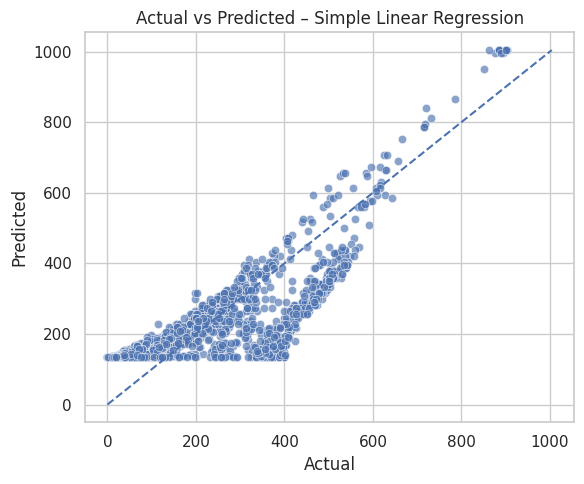

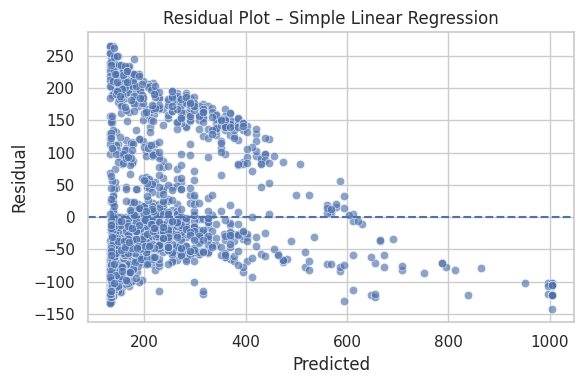

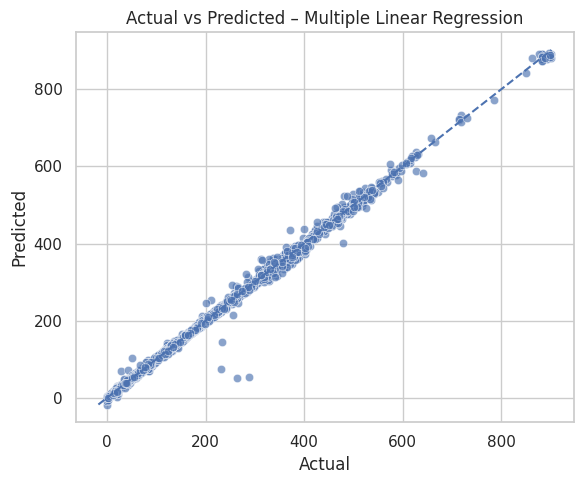

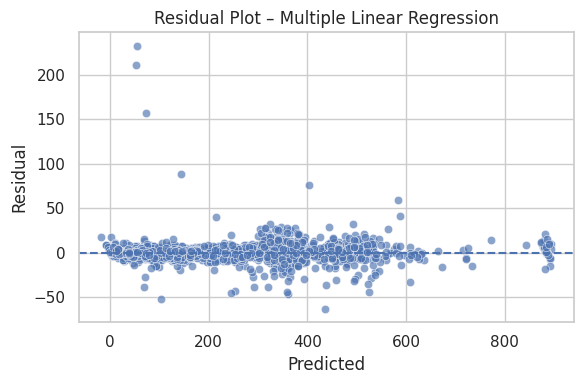

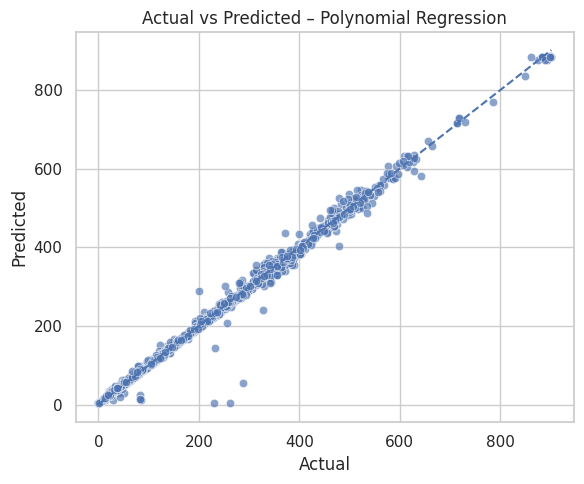

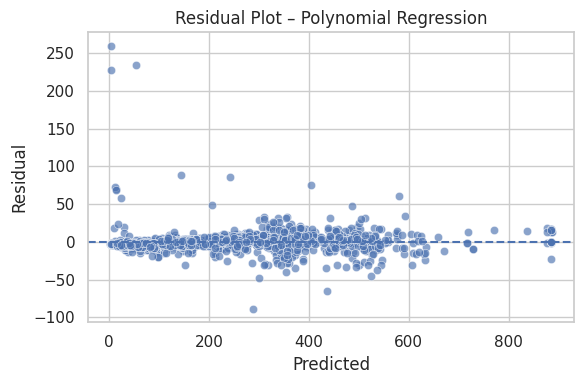

In [66]:
# Actual vs predicted and residual plots for each fitted regression model.
for model_name, pred in regression_predictions.items():
    results_plot = pd.DataFrame({
        "Actual": np.asarray(y_test_reg),
        "Predicted": np.asarray(pred)
    })
    results_plot["Residual"] = results_plot["Actual"] - results_plot["Predicted"]

    plt.figure(figsize=(6, 5))
    sns.scatterplot(data=results_plot, x="Actual", y="Predicted", alpha=0.65)
    low = min(results_plot["Actual"].min(), results_plot["Predicted"].min())
    high = max(results_plot["Actual"].max(), results_plot["Predicted"].max())
    plt.plot([low, high], [low, high], linestyle="--")
    plt.title(f"Actual vs Predicted – {model_name}")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=results_plot, x="Predicted", y="Residual", alpha=0.65)
    plt.axhline(0, linestyle="--")
    plt.title(f"Residual Plot – {model_name}")
    plt.tight_layout()
    plt.show()

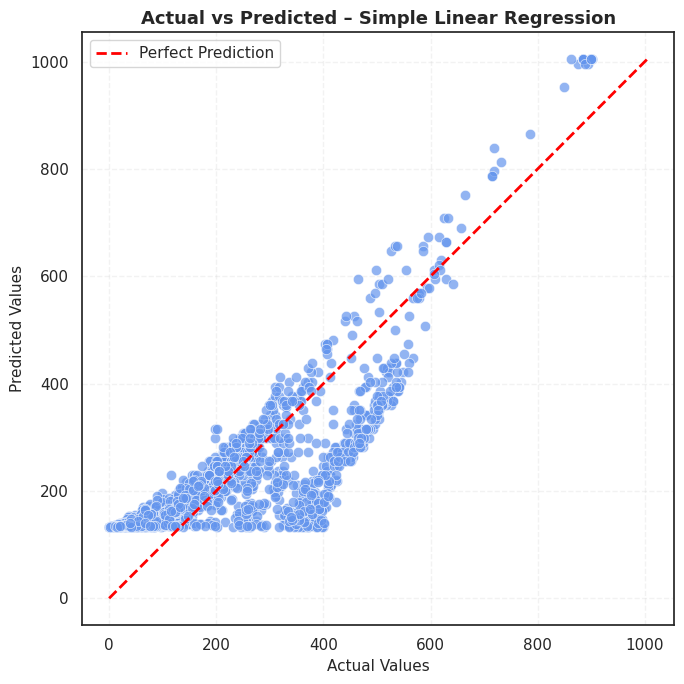

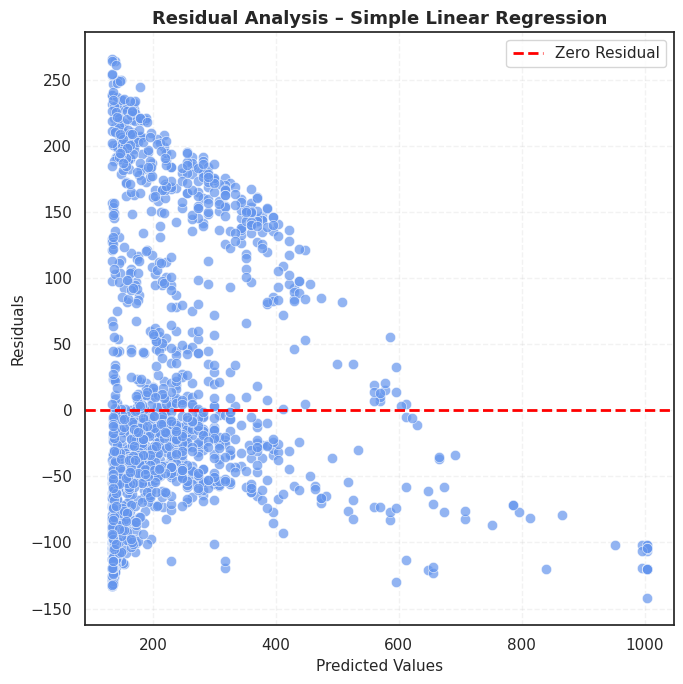

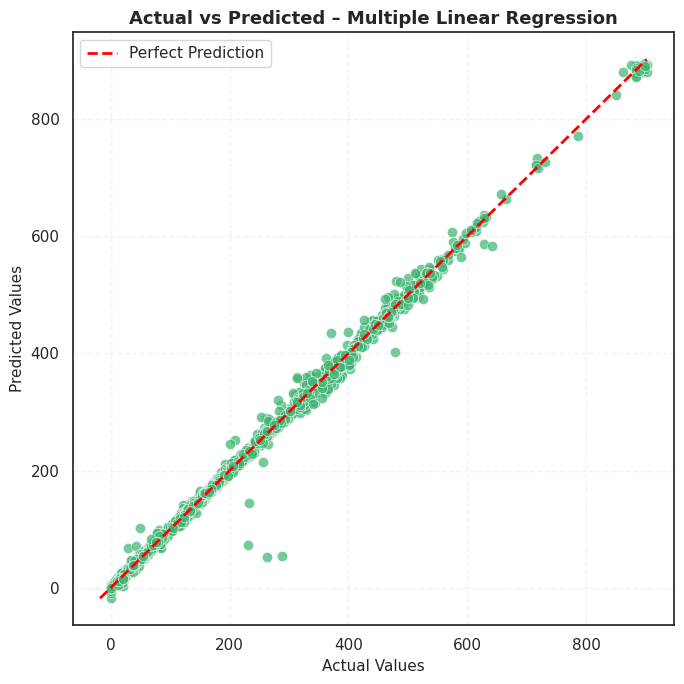

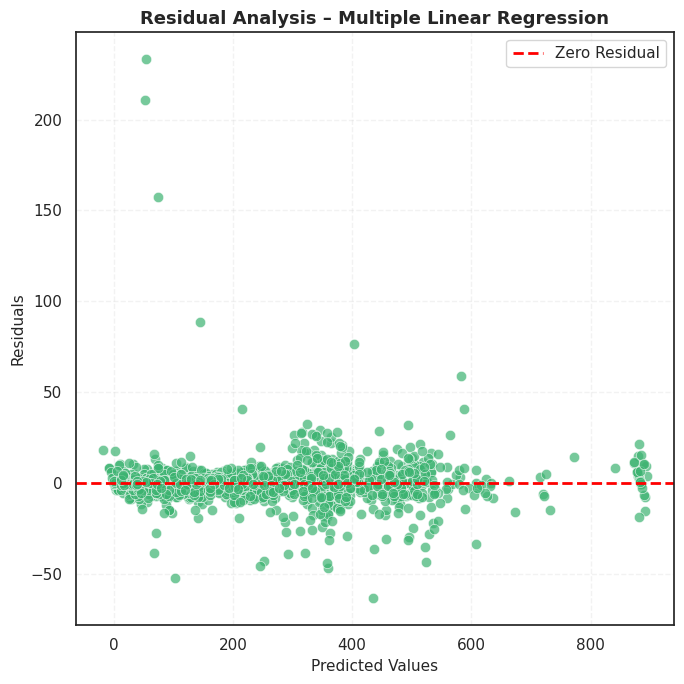

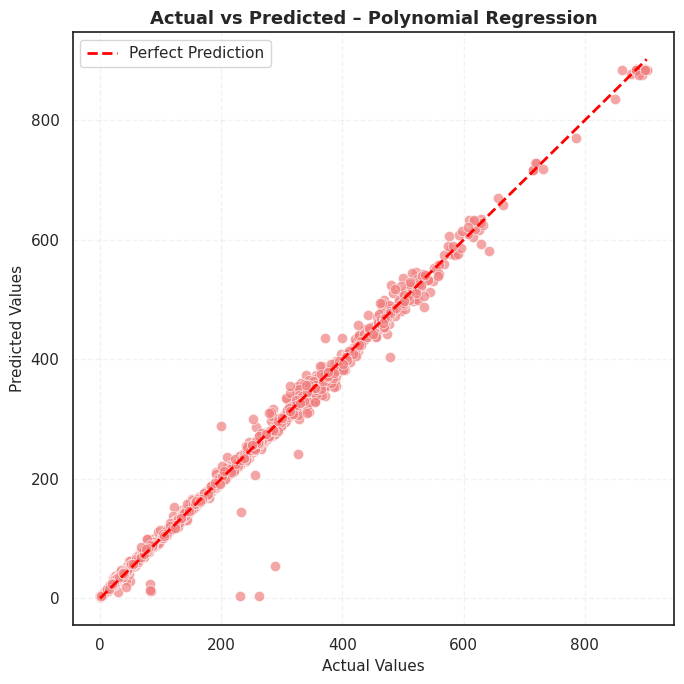

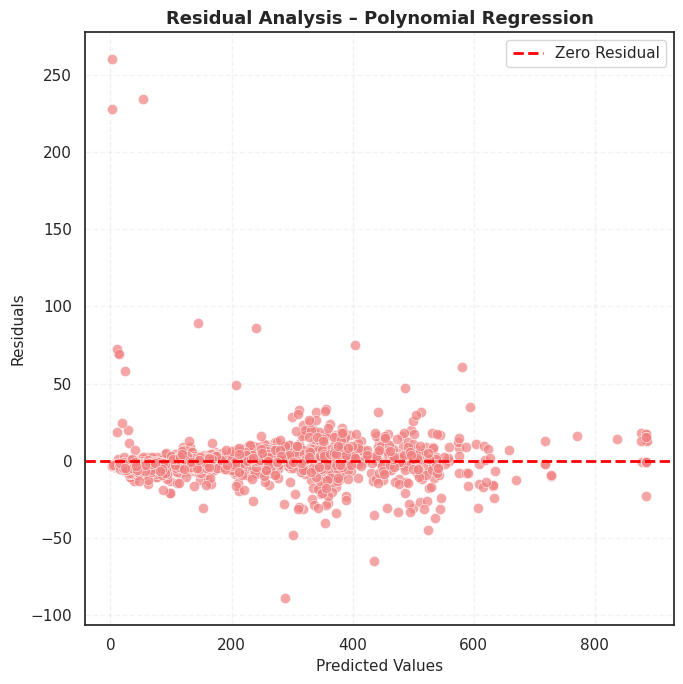

In [84]:
# Actual vs Predicted and Residual plots for each fitted regression model

regression_colors = [
    "cornflowerblue",
    "mediumseagreen",
    "lightcoral",
    "mediumpurple",
    "darkorange",
    "teal",
    "deeppink",
    "slateblue"
]

for i, (model_name, pred) in enumerate(regression_predictions.items()):

    results_plot = pd.DataFrame({
        "Actual": np.asarray(y_test_reg),
        "Predicted": np.asarray(pred)
    })

    results_plot["Residual"] = (
        results_plot["Actual"] - results_plot["Predicted"]
    )

    plot_color = regression_colors[i % len(regression_colors)]

    # Actual vs Predicted Plot
    plt.figure(figsize=(7, 7))

    sns.scatterplot(
        data=results_plot,
        x="Actual",
        y="Predicted",
        color=plot_color,
        alpha=0.7,
        s=55,
        edgecolor="white",
        linewidth=0.5
    )

    low = min(
        results_plot["Actual"].min(),
        results_plot["Predicted"].min()
    )

    high = max(
        results_plot["Actual"].max(),
        results_plot["Predicted"].max()
    )

    plt.plot(
        [low, high],
        [low, high],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Perfect Prediction"
    )

    plt.title(
        f"Actual vs Predicted – {model_name}",
        fontsize=13,
        fontweight="bold"
    )

    plt.xlabel("Actual Values", fontsize=11)
    plt.ylabel("Predicted Values", fontsize=11)
    plt.legend()
    plt.grid(linestyle="--", alpha=0.25)

    plt.tight_layout()
    plt.show()

    # Residual Plot
    plt.figure(figsize=(7, 7))

    sns.scatterplot(
        data=results_plot,
        x="Predicted",
        y="Residual",
        color=plot_color,
        alpha=0.7,
        s=55,
        edgecolor="white",
        linewidth=0.5
    )

    plt.axhline(
        0,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Zero Residual"
    )

    plt.title(
        f"Residual Analysis – {model_name}",
        fontsize=13,
        fontweight="bold"
    )

    plt.xlabel("Predicted Values", fontsize=11)
    plt.ylabel("Residuals", fontsize=11)
    plt.legend()
    plt.grid(linestyle="--", alpha=0.25)

    plt.tight_layout()
    plt.show()

In [67]:
if regression_results:
    best_reg_row = pd.DataFrame(regression_results).sort_values(
        ["RMSE", "MAE"], ascending=True
    ).iloc[0]
    print("Provisional best regression model (lowest RMSE):")
    display(best_reg_row.to_frame("Value"))
else:
    print("No regression model results are available.")

Provisional best regression model (lowest RMSE):


,Value
Model,Multiple Linear Regression
MAE,5.646394
MSE,145.281976
RMSE,12.053297
R2,0.995306


### H3. Overall model comparison

Classification and regression metrics must not be compared directly because they measure different tasks. Select the best classification model using suitable classification metrics and the best regression model using error metrics and R².

In [68]:
print("CLASSIFICATION MODEL COMPARISON")
if classification_results:
    display(pd.DataFrame(classification_results).sort_values("F1-score", ascending=False))
else:
    print("No classification results.")

print("\nREGRESSION MODEL COMPARISON")
if regression_results:
    display(pd.DataFrame(regression_results).sort_values("RMSE"))
else:
    print("No regression results.")

CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score
1,SVM,0.688497,0.679092,0.688497,0.678132
3,Random Forest,0.690774,0.687215,0.690774,0.676645
2,Decision Tree,0.669704,0.667386,0.669704,0.667897
4,Logistic Regression,0.639522,0.627056,0.639522,0.630234
0,Naive Bayes,0.373007,0.541521,0.373007,0.374975



REGRESSION MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2
1,Multiple Linear Regression,5.646394,145.281976,12.053297,0.995306
2,Polynomial Regression (degree 2; 5 numeric fea...,6.242168,197.311065,14.046746,0.993625
0,Simple Linear Regression (fat_g),82.917791,10648.245636,103.190337,0.655960


## PART I – POTENTIAL APPLICATION, LIMITATIONS AND CONCLUSION

### I1. Potential application

A possible application is a **Nutrition-Based Food Analysis and Prediction System**. Depending on the verified dataset variables and model performance, the system could classify food records into existing food/nutrition categories or estimate a selected numerical nutritional attribute from other available features.

The application must not be described as a medical diagnostic or personalised dietary recommendation tool unless it has been appropriately validated for that purpose. Predictions should be limited to the population, variables and data quality represented in the dataset.

In [69]:
# Create a concise model-selection summary from actual results.
application_summary = {}

if classification_results:
    cls_df = pd.DataFrame(classification_results).sort_values(
        ["F1-score", "Accuracy"], ascending=False
    )
    application_summary["Best classification model"] = cls_df.iloc[0]["Model"]
    application_summary["Classification F1-score"] = round(float(cls_df.iloc[0]["F1-score"]), 4)
    application_summary["Classification accuracy"] = round(float(cls_df.iloc[0]["Accuracy"]), 4)

if regression_results:
    reg_df = pd.DataFrame(regression_results).sort_values("RMSE")
    application_summary["Best regression model"] = reg_df.iloc[0]["Model"]
    application_summary["Regression RMSE"] = round(float(reg_df.iloc[0]["RMSE"]), 4)
    application_summary["Regression R2"] = round(float(reg_df.iloc[0]["R2"]), 4)

if application_summary:
    display(pd.DataFrame(application_summary.items(), columns=["Measure", "Result"]))
else:
    print("No model summary can be produced until suitable targets are configured.")

,Measure,Result
0,Best classification model,SVM
1,Classification F1-score,0.6781
2,Classification accuracy,0.6885
3,Best regression model,Multiple Linear Regression
4,Regression RMSE,12.0533
5,Regression R2,0.9953


### I2. Limitations
Complete this section based on the actual analysis. Consider:
- Missing, duplicated or inconsistent records.
- Unverified or incomplete source provenance.
- Unequal class distribution.
- Limited sample size or low variation in target variables.
- Potential bias in API-derived information.
- Features that may not generalise beyond the dataset.
- The fact that association does not establish causation.
- The need for external validation before real-world deployment.

### I3. Overall conclusion – reporting template

The fused food, nutrition and agriculture dataset was loaded and examined using Python. Structural, missing-data, consistency and outlier checks were performed before exploratory analysis. Univariate, bivariate and multivariate methods were used to investigate the distribution of attributes and relationships within the dataset.

Eight machine-learning approaches were considered: Naive Bayes, Support Vector Machine, Decision Tree, Random Forest, Logistic Regression, Simple Linear Regression, Multiple Linear Regression and Polynomial Regression. Classification models were evaluated using accuracy, precision, recall, F1-score and confusion matrices. Regression models were evaluated using MAE, MSE, RMSE and R².

**Replace this paragraph with your actual findings after running the notebook.** State which targets were used, which models completed successfully, their test-set scores, the best-performing model for each task and whether the results support the proposed application.

### I4. References
1. Kaggle. (n.d.). *NutriCare: Fused food nutrition agriculture dataset*. https://www.kaggle.com/datasets/dimpaltamta/nutricare-fused-food-nutrition-agriculture
2. KaggleHub documentation. https://github.com/Kaggle/kagglehub
3. McKinney, W. (2022). *Python for data analysis* (3rd ed.). O'Reilly Media.
4. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
5. The pandas development team. (n.d.). *pandas documentation*. https://pandas.pydata.org/docs/
6. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.

## FINAL SUBMISSION CHECKLIST

- [ ] Confirm that the correct dataset and file were loaded.
- [ ] Record the final number of rows and columns.
- [ ] Verify which attributes came from the original source and the API.
- [ ] Review duplicate identifiers and source conflicts.
- [ ] Explain the treatment of missing values.
- [ ] Review outlier flags and explain whether they are plausible observations or errors.
- [ ] Include important EDA charts and interpret them.
- [ ] Confirm that classification and regression targets are scientifically meaningful.
- [ ] Check that predictors do not leak the target.
- [ ] Report all eight algorithms or explain why any could not be run.
- [ ] Include confusion matrices and classification metrics.
- [ ] Include regression metrics and residual/actual-predicted plots.
- [ ] Write conclusions using actual outputs, not expected results.
- [ ] Keep the notebook and dataset private if required by the project.